<a href="https://colab.research.google.com/github/stano0048/Stano/blob/main/Lesson_3_Intelligent_Agents.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lesson 3:  Intelligent Agents

## Lesson Outline

1. **What is an Agent?**
2. **What is an Intelligent Agent?**
3. **Agents and Environments**
4. **Sensors**
5. **Actuators**
6. **Agent Function**
7. **Agent Program**
8. **Agent Architecture**
9. **Agent–Environment Interaction**
10. **Rational Agents**
11. **Rationality**
12. **Performance Measures**
13. **PEAS Framework**
14. **PEAS Examples**
15. **Types of AI Environments**
16. **Fully Observable Environments**
17. **Partially Observable Environments**
18. **Deterministic Environments**
19. **Stochastic Environments**
20. **Episodic Environments**
21. **Sequential Environments**
22. **Static Environments**
23. **Dynamic Environments**
24. **Discrete Environments**
25. **Continuous Environments**
26. **Single-Agent Environments**
27. **Multi-Agent Environments**
28. **Known and Unknown Environments**
29. **Simple Reflex Agents**
30. **Model-Based Reflex Agents**
31. **Goal-Based Agents**
32. **Utility-Based Agents**
33. **Learning Agents**
34. **Learning Agent Architecture**
35. **Problem-Solving Agents**
36. **Search-Based Agents**
37. **State Representation**
38. **Initial State**
39. **Actions**
40. **Transition Model**
41. **Goal Test**
42. **Path Cost**
43. **Building a Simple Agent in Python**
44. **Vacuum Cleaner Agent**
45. **Rule-Based Agent**
46. **Goal-Based Agent**
47. **Utility-Based Agent**
48. **Learning Agent**
49. **Agent and Environment Simulation**
50. **Practical Intelligent Agent Project**
51. **Exercises**
52. **Summary**
53. **Key Takeaways**
54. **End-of-Lesson Questions**

# 1. Introduction to Intelligent Agents

📚 **Detailed Notes:**

**Definition:** An intelligent agent is a system that perceives its environment through sensors, decides based on its internal logic, and acts on that environment through actuators to achieve its goals.

**Historical context:** The concept comes from AI pioneers Russell & Norvig (Artificial Intelligence: A Modern Approach). They define AI itself as "the study and design of rational agents" — meaning AI is not just about algorithms but about agents that behave rationally.

**Why agents matter:** The agent abstraction unifies everything in AI — from a thermostat to a self-driving car to an LLM chatbot. If you understand agents, you understand AI's core architecture.

**Four key properties of intelligent agents:**

- **Autonomy** — operates without constant human control
- **Reactivity** — responds to changes in the environment
- **Pro-activeness** — takes initiative toward goals
- **Social ability** — communicates with other agents/humans

**Real-world examples:**

- **Simple:** Thermostat, calculator, spell-checker
- **Medium:** Roomba vacuum, chess engine, recommendation system
- **Complex:** Self-driving car, AlphaGo, ChatGPT, autonomous drones

**The universal agent loop:** Perceive → Reason → Act → Repeat

💻 **Visual Code — Animated agent loop:**

In [1]:
# ============================================================
# 1. INTRODUCTION - Animated Agent-Environment Loop
# ============================================================
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
import numpy as np

# --- Create figure ---
fig, ax = plt.subplots(figsize=(12, 7))
ax.set_xlim(0, 12)
ax.set_ylim(0, 8)
ax.axis('off')
ax.set_title("The Agent-Environment Loop (animated)\n"
             "Perceive → Reason → Act → Repeat",
             fontsize=15, fontweight='bold')

# --- Agent box ---
agent_box = mpatches.FancyBboxPatch(
    (1, 4), 3.5, 2,
    boxstyle="round,pad=0.15",
    facecolor="#4A90E2", edgecolor="black", lw=2, zorder=3
)
ax.add_patch(agent_box)
ax.text(2.75, 5.0, "AGENT", ha='center', va='center',
        fontsize=16, color='white', fontweight='bold', zorder=4)
ax.text(2.75, 4.4, "(Decision Logic)", ha='center', va='center',
        fontsize=9, color='#FFEAA7', style='italic', zorder=4)

# --- Environment box ---
env_box = mpatches.FancyBboxPatch(
    (7, 4), 3.5, 2,
    boxstyle="round,pad=0.15",
    facecolor="#50C878", edgecolor="black", lw=2, zorder=3
)
ax.add_patch(env_box)
ax.text(8.75, 5.0, "ENVIRONMENT", ha='center', va='center',
        fontsize=14, color='white', fontweight='bold', zorder=4)
ax.text(8.75, 4.4, "(World / Context)", ha='center', va='center',
        fontsize=9, color='#D5F5E3', style='italic', zorder=4)

# --- Static arrows: Percepts (Env → Agent) ---
ax.annotate("", xy=(4.6, 5.7), xytext=(6.9, 5.7),
            arrowprops=dict(arrowstyle="-|>", lw=3, color="#E94B3C"),
            zorder=2)
ax.text(5.75, 6.15, "PERCEPTS", ha='center', color="#E94B3C",
        fontweight='bold', fontsize=12,
        bbox=dict(boxstyle="round", facecolor='white', edgecolor='#E94B3C', alpha=0.9))

# --- Static arrows: Actions (Agent → Env) ---
ax.annotate("", xy=(6.9, 4.3), xytext=(4.6, 4.3),
            arrowprops=dict(arrowstyle="-|>", lw=3, color="#8E44AD"),
            zorder=2)
ax.text(5.75, 3.75, "ACTIONS", ha='center', color="#8E44AD",
        fontweight='bold', fontsize=12,
        bbox=dict(boxstyle="round", facecolor='white', edgecolor='#8E44AD', alpha=0.9))

# --- Animated moving dot ---
dot, = ax.plot([], [], 'o', markersize=20, color='#FFD700',
               markeredgecolor='black', markeredgewidth=2, zorder=10)

# --- Status text box ---
status = ax.text(6, 1.8, "", ha='center', fontsize=13, fontweight='bold',
                 bbox=dict(boxstyle="round", facecolor="#FFF3CD",
                           edgecolor="#FFC107", lw=2), zorder=10)

# --- Step counter ---
step_label = ax.text(6, 0.7, "", ha='center', fontsize=11,
                     color='#555', style='italic')

# --- Waypoints for the animated dot ---
# Format: (x, y, status_text)
waypoints = [
    (5.75, 6.0, "🌍 Environment sends percepts..."),
    (4.5, 5.7, "📡 Percepts travel to agent..."),
    (2.75, 5.0, "🧠 Agent receives percepts..."),
    (2.75, 4.5, "⚙️ Agent processes & decides..."),
    (4.5, 4.3, "🎯 Agent selects an action..."),
    (5.75, 4.2, "📤 Action sent to environment..."),
    (7.5, 4.3, "🌍 Environment receives action..."),
    (8.75, 5.0, "🔄 Environment updates state..."),
    (7.5, 5.7, "📡 New percepts generated..."),
    (5.75, 5.9, "🔁 Loop repeats forever!"),
]

def update(i):
    x, y, text = waypoints[i]
    dot.set_data([x], [y])
    status.set_text(text)
    step_label.set_text(f"Step {i+1} of {len(waypoints)}")
    return dot, status, step_label

anim = FuncAnimation(fig, update, frames=len(waypoints),
                     interval=800, repeat=True, blit=True)
plt.close()
display(HTML(anim.to_jshtml()))

/tmp/ipykernel_4837/3328152713.py:97: UserWarning: Glyph 127757 (\N{EARTH GLOBE EUROPE-AFRICA}) missing from font(s) DejaVu Sans.
  display(HTML(anim.to_jshtml()))
/tmp/ipykernel_4837/3328152713.py:97: UserWarning: Glyph 128225 (\N{SATELLITE ANTENNA}) missing from font(s) DejaVu Sans.
  display(HTML(anim.to_jshtml()))
/tmp/ipykernel_4837/3328152713.py:97: UserWarning: Glyph 129504 (\N{BRAIN}) missing from font(s) DejaVu Sans.
  display(HTML(anim.to_jshtml()))
/tmp/ipykernel_4837/3328152713.py:97: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  display(HTML(anim.to_jshtml()))
/tmp/ipykernel_4837/3328152713.py:97: UserWarning: Glyph 128228 (\N{OUTBOX TRAY}) missing from font(s) DejaVu Sans.
  display(HTML(anim.to_jshtml()))
/tmp/ipykernel_4837/3328152713.py:97: UserWarning: Glyph 128260 (\N{ANTICLOCKWISE DOWNWARDS AND UPWARDS OPEN CIRCLE ARROWS}) missing from font(s) DejaVu Sans.
  display(HTML(anim.to_jshtml()))
/tmp/ipykernel_4837/3328152713.py:97: UserWa

🎯 **Teaching Point:** Emphasize this loop is endless. Every AI system — from Siri to self-driving cars — runs this continuously. Watch the golden dot travel around the loop; each stop is a different phase of the cycle.

---

# 2. What is an Agent?

📚 **Detailed Notes:**

**Formal definition (Russell & Norvig):** An agent is anything that can be viewed as perceiving its environment through sensors and acting upon that environment through actuators.

- The **agent function** takes a percept sequence and returns an action.
- The **agent program** is the concrete implementation running on the architecture.
- **Agent = Architecture + Program**
  - **Architecture:** the computing platform (CPU, robot body, cloud server)
  - **Program:** the algorithm that maps percepts to actions

**Types of agents by nature:**

- **Human agent:** eyes/ears (sensors), hands/legs/mouth (actuators)
- **Robotic agent:** cameras/LIDAR (sensors), motors/wheels (actuators)
- **Software agent:** API calls (sensors), function executions (actuators)

**Agent boundary:** the "skin" that separates the agent from its environment is defined by its sensors and actuators.

💻 **Visual Code — Colorful labeled robot diagram:**

/tmp/ipykernel_4837/996209005.py:592: UserWarning: Glyph 127795 (\N{DECIDUOUS TREE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4837/996209005.py:592: UserWarning: Glyph 127777 (\N{THERMOMETER}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4837/996209005.py:592: UserWarning: Glyph 128663 (\N{AUTOMOBILE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4837/996209005.py:592: UserWarning: Glyph 128100 (\N{BUST IN SILHOUETTE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4837/996209005.py:592: UserWarning: Glyph 127783 (\N{CLOUD WITH RAIN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4837/996209005.py:592: UserWarning: Glyph 128205 (\N{ROUND PUSHPIN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127795 (\N{DECIDUOUS TREE}) missing from font(s) DejaVu Sans.
  fig.canv

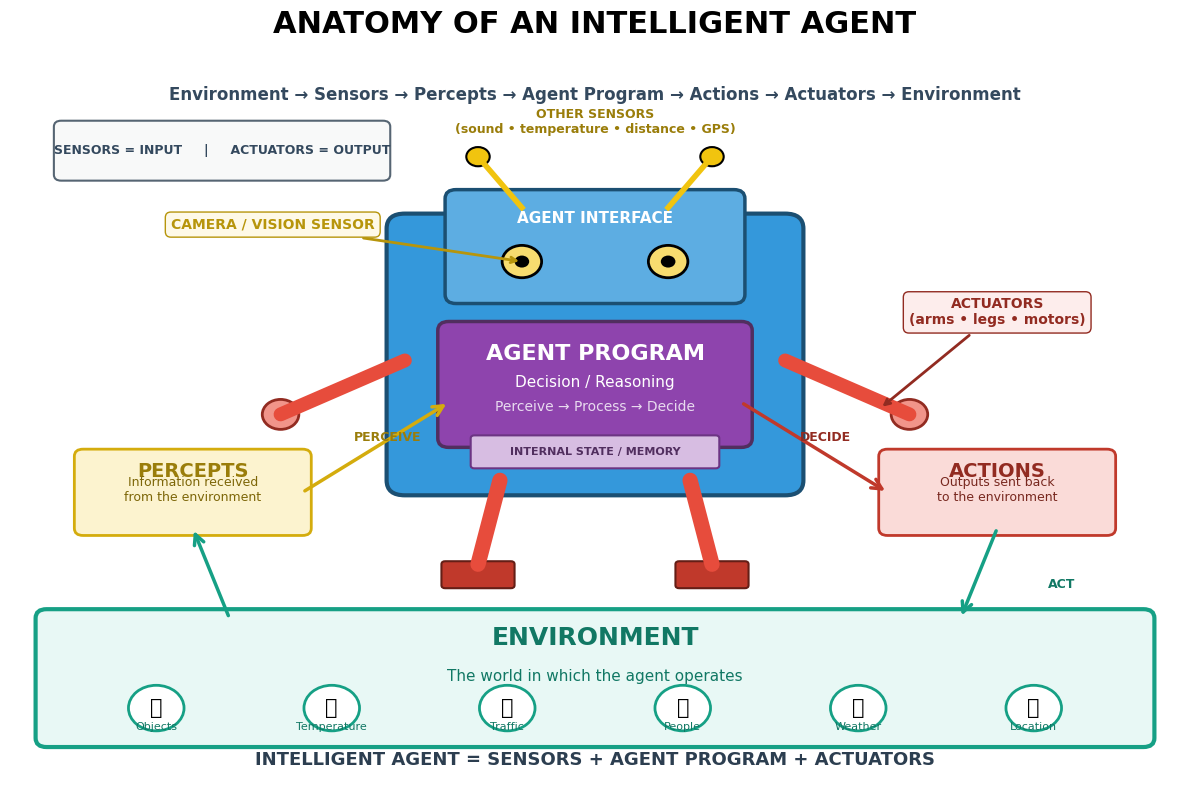

KEY CONCEPTS
1. ENVIRONMENT  → The world in which the agent operates
2. SENSORS      → Collect information from the environment
3. PERCEPTS     → Information received by the agent
4. AGENT PROGRAM→ Processes percepts and makes decisions
5. INTERNAL STATE→ Stores useful information / memory
6. DECISION     → Determines what the agent should do
7. ACTION       → The selected response
8. ACTUATORS    → Execute actions in the environment
9. FEEDBACK     → The environment changes and is sensed again
AGENT LOOP: PERCEIVE → THINK → ACT → PERCEIVE → THINK → ACT


In [2]:
# ============================================================
# WHAT IS AN AGENT? — VISUAL ANATOMY OF AN INTELLIGENT AGENT
# ============================================================

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.patches import FancyArrowPatch

# ------------------------------------------------------------
# 1. CREATE FIGURE
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 8))

ax.set_xlim(0, 16)
ax.set_ylim(0, 12)
ax.axis("off")

ax.set_title(
    "ANATOMY OF AN INTELLIGENT AGENT",
    fontsize=22,
    fontweight="bold",
    pad=20
)

ax.text(
    8, 11.35,
    "Environment → Sensors → Percepts → Agent Program → Actions → Actuators → Environment",
    ha="center",
    fontsize=12,
    color="#34495E",
    fontweight="bold"
)

# ============================================================
# 2. ENVIRONMENT
# ============================================================

environment = patches.FancyBboxPatch(
    (0.5, 0.7),
    15,
    2.0,
    boxstyle="round,pad=0.15",
    facecolor="#E8F8F5",
    edgecolor="#16A085",
    linewidth=3
)

ax.add_patch(environment)

ax.text(
    8, 2.25,
    "ENVIRONMENT",
    ha="center",
    fontsize=18,
    fontweight="bold",
    color="#117864"
)

ax.text(
    8, 1.65,
    "The world in which the agent operates",
    ha="center",
    fontsize=11,
    color="#117864"
)

# Environment examples

env_items = [
    ("🌳", "Objects"),
    ("🌡", "Temperature"),
    ("🚗", "Traffic"),
    ("👤", "People"),
    ("🌧", "Weather"),
    ("📍", "Location")
]

x_positions = [2, 4.4, 6.8, 9.2, 11.6, 14]

for x, (symbol, label) in zip(x_positions, env_items):

    circle = patches.Circle(
        (x, 1.2),
        0.38,
        facecolor="white",
        edgecolor="#16A085",
        linewidth=2
    )

    ax.add_patch(circle)

    ax.text(
        x, 1.2,
        symbol,
        ha="center",
        va="center",
        fontsize=15
    )

    ax.text(
        x, 0.83,
        label,
        ha="center",
        fontsize=8,
        color="#117864"
    )

# ============================================================
# 3. ROBOT / AGENT BODY
# ============================================================

# Main body

body = patches.FancyBboxPatch(
    (5.4, 5.0),
    5.2,
    4.2,
    boxstyle="round,pad=0.25",
    facecolor="#3498DB",
    edgecolor="#1B4F72",
    linewidth=3
)

ax.add_patch(body)

# ============================================================
# 4. HEAD
# ============================================================

head = patches.FancyBboxPatch(
    (6.1, 8.1),
    3.8,
    1.6,
    boxstyle="round,pad=0.15",
    facecolor="#5DADE2",
    edgecolor="#1B4F72",
    linewidth=2.5
)

ax.add_patch(head)

ax.text(
    8, 9.3,
    "AGENT INTERFACE",
    ha="center",
    fontsize=11,
    color="white",
    fontweight="bold"
)

# ============================================================
# 5. EYES = SENSORS
# ============================================================

for x in [7.0, 9.0]:

    eye = patches.Circle(
        (x, 8.65),
        0.27,
        facecolor="#F7DC6F",
        edgecolor="black",
        linewidth=2
    )

    pupil = patches.Circle(
        (x, 8.65),
        0.10,
        facecolor="black"
    )

    ax.add_patch(eye)
    ax.add_patch(pupil)

# Eye label

ax.annotate(
    "CAMERA / VISION SENSOR",
    xy=(7.0, 8.65),
    xytext=(2.2, 9.2),
    fontsize=10,
    fontweight="bold",
    color="#B7950B",
    arrowprops=dict(
        arrowstyle="->",
        linewidth=2,
        color="#B7950B"
    ),
    bbox=dict(
        boxstyle="round,pad=0.4",
        facecolor="#FEF9E7",
        edgecolor="#B7950B"
    )
)

# ============================================================
# 6. ANTENNAE = ADDITIONAL SENSORS
# ============================================================

ax.plot(
    [7.0, 6.4],
    [9.55, 10.4],
    color="#F1C40F",
    linewidth=4
)

ax.plot(
    [9.0, 9.6],
    [9.55, 10.4],
    color="#F1C40F",
    linewidth=4
)

for x in [6.4, 9.6]:

    ax.add_patch(
        patches.Circle(
            (x, 10.4),
            0.16,
            facecolor="#F1C40F",
            edgecolor="black",
            linewidth=1.5
        )
    )

ax.text(
    8, 10.8,
    "OTHER SENSORS\n(sound • temperature • distance • GPS)",
    ha="center",
    fontsize=9,
    color="#9A7D0A",
    fontweight="bold"
)

# ============================================================
# 7. AGENT PROGRAM / BRAIN
# ============================================================

brain = patches.FancyBboxPatch(
    (6.0, 5.7),
    4.0,
    1.8,
    boxstyle="round,pad=0.15",
    facecolor="#8E44AD",
    edgecolor="#512E5F",
    linewidth=2.5
)

ax.add_patch(brain)

ax.text(
    8, 7.0,
    "AGENT PROGRAM",
    ha="center",
    fontsize=16,
    color="white",
    fontweight="bold"
)

ax.text(
    8, 6.55,
    "Decision / Reasoning",
    ha="center",
    fontsize=11,
    color="white"
)

ax.text(
    8, 6.15,
    "Perceive → Process → Decide",
    ha="center",
    fontsize=10,
    color="#E8DAEF"
)

# ============================================================
# 8. INTERNAL STATE
# ============================================================

state = patches.FancyBboxPatch(
    (6.35, 5.25),
    3.3,
    0.45,
    boxstyle="round,pad=0.05",
    facecolor="#D7BDE2",
    edgecolor="#6C3483",
    linewidth=1.5
)

ax.add_patch(state)

ax.text(
    8, 5.47,
    "INTERNAL STATE / MEMORY",
    ha="center",
    va="center",
    fontsize=8,
    color="#512E5F",
    fontweight="bold"
)

# ============================================================
# 9. ARMS = ACTUATORS
# ============================================================

# Left arm
ax.plot(
    [5.4, 3.7],
    [7.0, 6.1],
    color="#E74C3C",
    linewidth=10,
    solid_capstyle="round"
)

# Right arm
ax.plot(
    [10.6, 12.3],
    [7.0, 6.1],
    color="#E74C3C",
    linewidth=10,
    solid_capstyle="round"
)

# Hands

for x, y in [(3.7, 6.1), (12.3, 6.1)]:

    ax.add_patch(
        patches.Circle(
            (x, y),
            0.25,
            facecolor="#F1948A",
            edgecolor="#922B21",
            linewidth=2
        )
    )

# ============================================================
# 10. LEGS = ACTUATORS
# ============================================================

ax.plot(
    [6.7, 6.4],
    [5.0, 3.6],
    color="#E74C3C",
    linewidth=11,
    solid_capstyle="round"
)

ax.plot(
    [9.3, 9.6],
    [5.0, 3.6],
    color="#E74C3C",
    linewidth=11,
    solid_capstyle="round"
)

# Feet

for x in [6.4, 9.6]:

    ax.add_patch(
        patches.FancyBboxPatch(
            (x - 0.45, 3.25),
            0.9,
            0.35,
            boxstyle="round,pad=0.05",
            facecolor="#C0392B",
            edgecolor="#641E16",
            linewidth=1.5
        )
    )

# ============================================================
# 11. ACTUATOR LABEL
# ============================================================

ax.annotate(
    "ACTUATORS\n(arms • legs • motors)",
    xy=(11.9, 6.2),
    xytext=(13.5, 7.6),
    fontsize=10,
    fontweight="bold",
    color="#922B21",
    ha="center",
    arrowprops=dict(
        arrowstyle="->",
        linewidth=2,
        color="#922B21"
    ),
    bbox=dict(
        boxstyle="round,pad=0.4",
        facecolor="#FDEDEC",
        edgecolor="#922B21"
    )
)

# ============================================================
# 12. PERCEPTS
# ============================================================

percept_box = patches.FancyBboxPatch(
    (1.0, 4.2),
    3.0,
    1.2,
    boxstyle="round,pad=0.12",
    facecolor="#FCF3CF",
    edgecolor="#D4AC0D",
    linewidth=2
)

ax.add_patch(percept_box)

ax.text(
    2.5, 5.05,
    "PERCEPTS",
    ha="center",
    fontsize=14,
    fontweight="bold",
    color="#9A7D0A"
)

ax.text(
    2.5, 4.65,
    "Information received\nfrom the environment",
    ha="center",
    fontsize=9,
    color="#7D6608"
)

# ============================================================
# 13. ACTIONS
# ============================================================

action_box = patches.FancyBboxPatch(
    (12.0, 4.2),
    3.0,
    1.2,
    boxstyle="round,pad=0.12",
    facecolor="#FADBD8",
    edgecolor="#C0392B",
    linewidth=2
)

ax.add_patch(action_box)

ax.text(
    13.5, 5.05,
    "ACTIONS",
    ha="center",
    fontsize=14,
    fontweight="bold",
    color="#922B21"
)

ax.text(
    13.5, 4.65,
    "Outputs sent back\nto the environment",
    ha="center",
    fontsize=9,
    color="#78281F"
)

# ============================================================
# 14. INFORMATION FLOW
# ============================================================

# Environment → Percepts

ax.add_patch(
    FancyArrowPatch(
        (3.0, 2.7),
        (2.5, 4.2),
        arrowstyle="->",
        mutation_scale=18,
        linewidth=2.5,
        color="#16A085"
    )
)

# Percepts → Agent

ax.add_patch(
    FancyArrowPatch(
        (4.0, 4.8),
        (6.0, 6.3),
        arrowstyle="->",
        mutation_scale=18,
        linewidth=2.5,
        color="#D4AC0D"
    )
)

# Agent → Actions

ax.add_patch(
    FancyArrowPatch(
        (10.0, 6.3),
        (12.0, 4.8),
        arrowstyle="->",
        mutation_scale=18,
        linewidth=2.5,
        color="#C0392B"
    )
)

# Actions → Environment

ax.add_patch(
    FancyArrowPatch(
        (13.5, 4.2),
        (13.0, 2.7),
        arrowstyle="->",
        mutation_scale=18,
        linewidth=2.5,
        color="#16A085"
    )
)

# ============================================================
# 15. LABEL THE FLOW
# ============================================================

ax.text(
    4.7, 5.65,
    "PERCEIVE",
    fontsize=9,
    fontweight="bold",
    color="#9A7D0A"
)

ax.text(
    10.8, 5.65,
    "DECIDE",
    fontsize=9,
    fontweight="bold",
    color="#922B21"
)

ax.text(
    14.2, 3.2,
    "ACT",
    fontsize=9,
    fontweight="bold",
    color="#117864"
)

# ============================================================
# 16. LEGEND
# ============================================================

legend_box = patches.FancyBboxPatch(
    (0.7, 10.1),
    4.4,
    0.8,
    boxstyle="round,pad=0.1",
    facecolor="#F8F9F9",
    edgecolor="#566573",
    linewidth=1.5
)

ax.add_patch(legend_box)

ax.text(
    2.9, 10.5,
    "SENSORS = INPUT     |     ACTUATORS = OUTPUT",
    ha="center",
    va="center",
    fontsize=9,
    fontweight="bold",
    color="#34495E"
)

# ============================================================
# 17. KEY FORMULA
# ============================================================

ax.text(
    8,
    0.25,
    "INTELLIGENT AGENT = SENSORS + AGENT PROGRAM + ACTUATORS",
    ha="center",
    fontsize=13,
    fontweight="bold",
    color="#2C3E50"
)

# ============================================================
# 18. DISPLAY
# ============================================================

plt.tight_layout()
plt.show()

# ============================================================
# KEY TEACHING POINTS
# ============================================================

print("============================================================")
print("KEY CONCEPTS")
print("============================================================")
print("1. ENVIRONMENT  → The world in which the agent operates")
print("2. SENSORS      → Collect information from the environment")
print("3. PERCEPTS     → Information received by the agent")
print("4. AGENT PROGRAM→ Processes percepts and makes decisions")
print("5. INTERNAL STATE→ Stores useful information / memory")
print("6. DECISION     → Determines what the agent should do")
print("7. ACTION       → The selected response")
print("8. ACTUATORS    → Execute actions in the environment")
print("9. FEEDBACK     → The environment changes and is sensed again")
print("============================================================")
print("AGENT LOOP: PERCEIVE → THINK → ACT → PERCEIVE → THINK → ACT")
print("============================================================")

# 3. What is an Intelligent Agent?

📚 **Detailed Notes:**

An **intelligent agent** is an agent that acts **rationally** — meaning it selects actions that maximize its expected performance given what it knows.

**Four factors that define rationality (memorize this!):**

1. **Performance measure** — the criterion for success
2. **Prior knowledge** — what the agent knows about the world
3. **Actions available** — what the agent can do
4. **Percept sequence** — the entire history of what the agent has perceived

**What intelligence does NOT mean:**

- ❌ **Omniscience** (knowing everything) — agents don't know the future
- ❌ **Perfection** (always succeeding) — agents can fail despite rationality
- ❌ **Consciousness** — no requirement for awareness

**Agent characteristics:**

- **Reactive:** responds to environment changes
- **Proactive:** acts toward goals
- **Autonomous:** operates independently
- **Adaptive/Learning:** improves with experience

**The exploration vs. exploitation trade-off:** intelligent agents must balance trying new things (exploration) with using known good strategies (exploitation).

💻 **Visual Code — Score evolution graph + decision heatmap:**

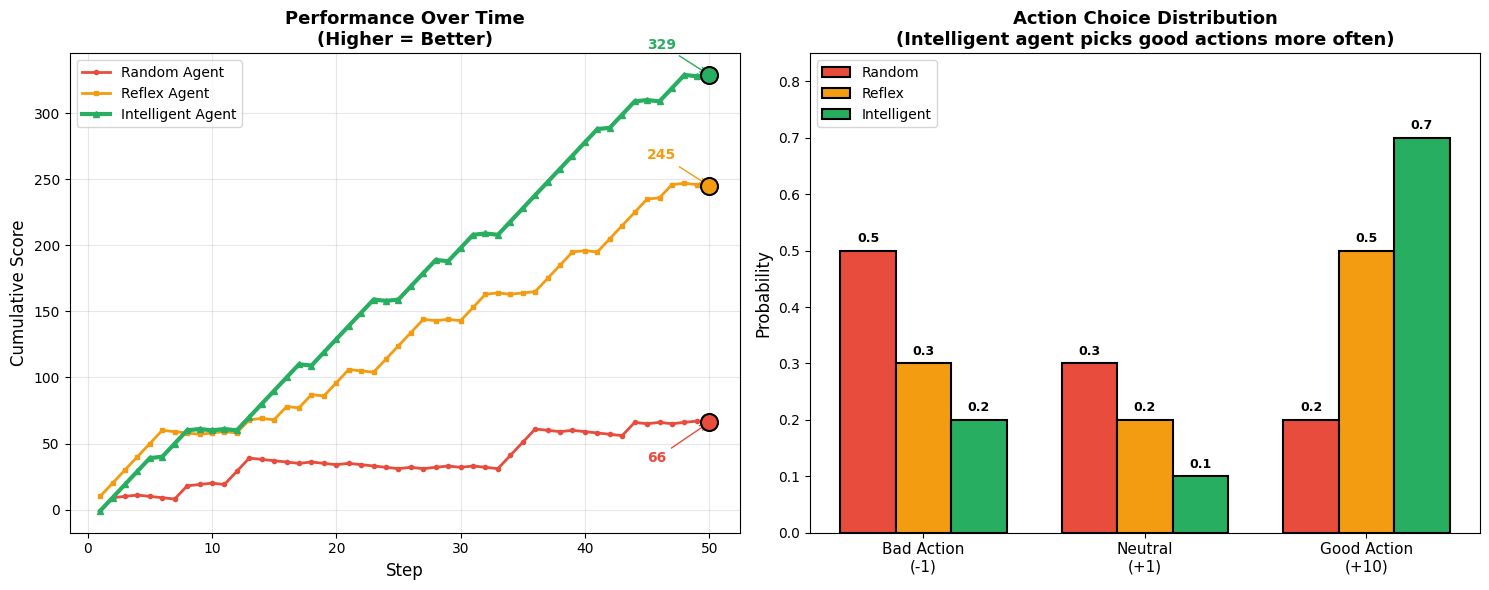

📌 Final scores → Random: 66, Reflex: 245, Intelligent: 329
📌 Intelligence = choosing better actions more often, which compounds over time.


In [3]:
# ============================================================
# 3. INTELLIGENT AGENT - Score Growth Visualization
# ============================================================
import matplotlib.pyplot as plt
import numpy as np

np.random.seed(42)

# --- Simulate three agents with different "intelligence" levels ---
steps = np.arange(1, 51)
random_agent = np.cumsum(np.random.choice([-1, 1, 10], size=50, p=[0.5, 0.3, 0.2]))
reflex_agent = np.cumsum(np.random.choice([-1, 1, 10], size=50, p=[0.3, 0.2, 0.5]))
smart_agent  = np.cumsum(np.random.choice([-1, 1, 10], size=50, p=[0.2, 0.1, 0.7]))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# --- Left: cumulative score ---
ax1.plot(steps, random_agent, label="Random Agent", color='#E74C3C',
         lw=2, marker='o', markersize=3)
ax1.plot(steps, reflex_agent, label="Reflex Agent", color='#F39C12',
         lw=2, marker='s', markersize=3)
ax1.plot(steps, smart_agent,  label="Intelligent Agent", color='#27AE60',
         lw=3, marker='^', markersize=4)

# Highlight final values
ax1.scatter([50], [random_agent[-1]], color='#E74C3C', s=150,
            zorder=5, edgecolor='black', lw=1.5)
ax1.scatter([50], [reflex_agent[-1]], color='#F39C12', s=150,
            zorder=5, edgecolor='black', lw=1.5)
ax1.scatter([50], [smart_agent[-1]], color='#27AE60', s=150,
            zorder=5, edgecolor='black', lw=1.5)

ax1.annotate(f"{smart_agent[-1]}", xy=(50, smart_agent[-1]),
             xytext=(45, smart_agent[-1]+20), fontsize=10,
             fontweight='bold', color='#27AE60',
             arrowprops=dict(arrowstyle='->', color='#27AE60'))
ax1.annotate(f"{reflex_agent[-1]}", xy=(50, reflex_agent[-1]),
             xytext=(45, reflex_agent[-1]+20), fontsize=10,
             fontweight='bold', color='#F39C12',
             arrowprops=dict(arrowstyle='->', color='#F39C12'))
ax1.annotate(f"{random_agent[-1]}", xy=(50, random_agent[-1]),
             xytext=(45, random_agent[-1]-30), fontsize=10,
             fontweight='bold', color='#E74C3C',
             arrowprops=dict(arrowstyle='->', color='#E74C3C'))

ax1.set_xlabel("Step", fontsize=12)
ax1.set_ylabel("Cumulative Score", fontsize=12)
ax1.set_title("Performance Over Time\n(Higher = Better)", fontweight='bold',
              fontsize=13)
ax1.legend(loc='upper left', fontsize=10)
ax1.grid(alpha=0.3)

# --- Right: probability distribution of choices ---
choices = ["Bad Action\n(-1)", "Neutral\n(+1)", "Good Action\n(+10)"]
random_p = [0.5, 0.3, 0.2]
reflex_p = [0.3, 0.2, 0.5]
smart_p  = [0.2, 0.1, 0.7]

x = np.arange(3)
w = 0.25
bars1 = ax2.bar(x - w, random_p, w, label="Random",
                color='#E74C3C', edgecolor='black', lw=1.5)
bars2 = ax2.bar(x,     reflex_p, w, label="Reflex",
                color='#F39C12', edgecolor='black', lw=1.5)
bars3 = ax2.bar(x + w, smart_p,  w, label="Intelligent",
                color='#27AE60', edgecolor='black', lw=1.5)

# Add value labels on bars
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                 f'{height:.1f}', ha='center', va='bottom',
                 fontsize=9, fontweight='bold')

ax2.set_xticks(x)
ax2.set_xticklabels(choices, fontsize=11)
ax2.set_ylabel("Probability", fontsize=12)
ax2.set_title("Action Choice Distribution\n(Intelligent agent picks good actions more often)",
              fontweight='bold', fontsize=13)
ax2.legend(fontsize=10)
ax2.set_ylim(0, 0.85)

plt.tight_layout()
plt.show()

print(f"📌 Final scores → Random: {random_agent[-1]}, "
      f"Reflex: {reflex_agent[-1]}, Intelligent: {smart_agent[-1]}")
print("📌 Intelligence = choosing better actions more often, which compounds over time.")

How the Above factors work

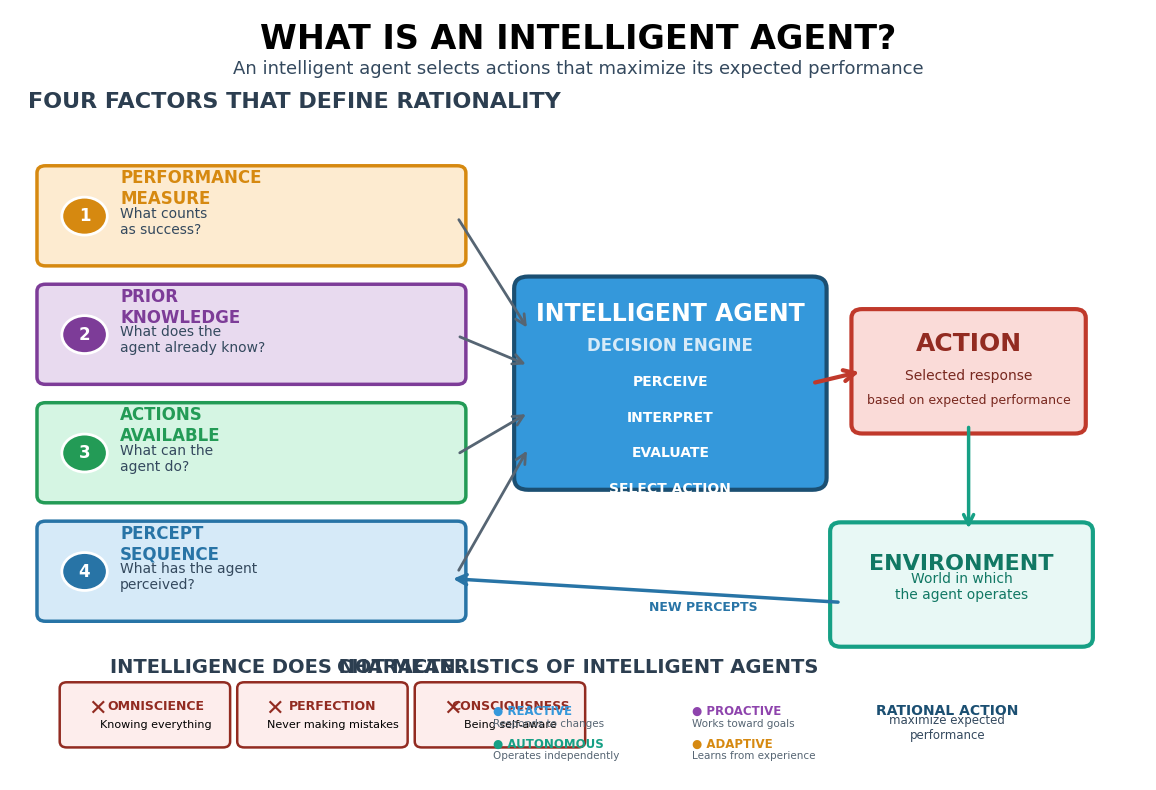

WHAT IS AN INTELLIGENT AGENT?

An intelligent agent is an agent that acts RATIONALLY.

RATIONALITY means:
The agent selects the action that is expected to produce
the best performance, given the information available to it.

FOUR FACTORS THAT DEFINE RATIONALITY

1. PERFORMANCE MEASURE
   → What criterion defines success?

2. PRIOR KNOWLEDGE
   → What does the agent already know?

3. ACTIONS AVAILABLE
   → What actions can the agent perform?

4. PERCEPT SEQUENCE
   → What has the agent observed over time?

IMPORTANT: INTELLIGENCE ≠ PERFECTION

Intelligent agents:

✗ Do NOT need to know everything (omniscience)
✗ Do NOT need to succeed every time (perfection)
✗ Do NOT need to be conscious

✓ They need to choose rational actions using available information.

AGENT CHARACTERISTICS

⚡ REACTIVE    → responds to environmental changes
🎯 PROACTIVE   → acts toward goals
🤖 AUTONOMOUS  → operates independently
📈 ADAPTIVE    → improves through experience

EXPLORATION VS EXPLOITATION

🔎 EXPLORATION


In [4]:
# ============================================================
# WHAT IS AN INTELLIGENT AGENT?
# VISUAL EXPLANATION OF RATIONALITY
# ============================================================

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.patches import FancyArrowPatch

# ------------------------------------------------------------
# CREATE FIGURE
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 8))

ax.set_xlim(0, 16)
ax.set_ylim(0, 13)
ax.axis("off")

# ------------------------------------------------------------
# TITLE
# ------------------------------------------------------------

ax.text(
    8, 12.5,
    "WHAT IS AN INTELLIGENT AGENT?",
    ha="center",
    va="center",
    fontsize=24,
    fontweight="bold"
)

ax.text(
    8, 12.0,
    "An intelligent agent selects actions that maximize its expected performance",
    ha="center",
    va="center",
    fontsize=13,
    color="#34495E"
)

# ============================================================
# SECTION 1 — FOUR FACTORS OF RATIONALITY
# ============================================================

ax.text(
    4, 11.35,
    "FOUR FACTORS THAT DEFINE RATIONALITY",
    ha="center",
    fontsize=16,
    fontweight="bold",
    color="#2C3E50"
)

# ------------------------------------------------------------
# Factor boxes
# ------------------------------------------------------------

factors = [
    (
        0.5, 8.8,
        "1",
        "PERFORMANCE\nMEASURE",
        "What counts\nas success?",
        "#FDEBD0",
        "#D68910"
    ),

    (
        0.5, 6.8,
        "2",
        "PRIOR\nKNOWLEDGE",
        "What does the\nagent already know?",
        "#E8DAEF",
        "#7D3C98"
    ),

    (
        0.5, 4.8,
        "3",
        "ACTIONS\nAVAILABLE",
        "What can the\nagent do?",
        "#D5F5E3",
        "#239B56"
    ),

    (
        0.5, 2.8,
        "4",
        "PERCEPT\nSEQUENCE",
        "What has the agent\nperceived?",
        "#D6EAF8",
        "#2874A6"
    )
]

for x, y, number, title, description, face, edge in factors:

    box = patches.FancyBboxPatch(
        (x, y),
        5.8,
        1.45,
        boxstyle="round,pad=0.12",
        facecolor=face,
        edgecolor=edge,
        linewidth=2.5
    )

    ax.add_patch(box)

    # Number circle

    circle = patches.Circle(
        (x + 0.55, y + 0.72),
        0.32,
        facecolor=edge,
        edgecolor="white",
        linewidth=2
    )

    ax.add_patch(circle)

    ax.text(
        x + 0.55,
        y + 0.72,
        number,
        ha="center",
        va="center",
        color="white",
        fontsize=12,
        fontweight="bold"
    )

    # Title

    ax.text(
        x + 1.05,
        y + 0.92,
        title,
        fontsize=12,
        fontweight="bold",
        color=edge
    )

    # Description

    ax.text(
        x + 1.05,
        y + 0.42,
        description,
        fontsize=10,
        color="#34495E"
    )

# ============================================================
# CENTRAL AGENT DECISION ENGINE
# ============================================================

agent = patches.FancyBboxPatch(
    (7.3, 5.1),
    4.0,
    3.2,
    boxstyle="round,pad=0.2",
    facecolor="#3498DB",
    edgecolor="#1B4F72",
    linewidth=3
)

ax.add_patch(agent)

ax.text(
    9.3,
    7.75,
    "INTELLIGENT AGENT",
    ha="center",
    fontsize=17,
    color="white",
    fontweight="bold"
)

ax.text(
    9.3,
    7.25,
    "DECISION ENGINE",
    ha="center",
    fontsize=12,
    color="#D6EAF8",
    fontweight="bold"
)

# ------------------------------------------------------------
# Internal processes
# ------------------------------------------------------------

processes = [
    (6.65, "PERCEIVE"),
    (6.05, "INTERPRET"),
    (5.45, "EVALUATE"),
    (4.85, "SELECT ACTION")
]

for y, text in processes:

    ax.text(
        9.3,
        y,
        text,
        ha="center",
        fontsize=10,
        color="white",
        fontweight="bold"
    )

# ============================================================
# ARROWS FROM FOUR FACTORS TO AGENT
# ============================================================

arrow_positions = [
    (6.3, 9.5, 7.3, 7.6),
    (6.3, 7.5, 7.3, 7.0),
    (6.3, 5.5, 7.3, 6.2),
    (6.3, 3.5, 7.3, 5.6)
]

for x1, y1, x2, y2 in arrow_positions:

    ax.add_patch(
        FancyArrowPatch(
            (x1, y1),
            (x2, y2),
            arrowstyle="->",
            mutation_scale=18,
            linewidth=2,
            color="#566573"
        )
    )

# ============================================================
# ACTION OUTPUT
# ============================================================

action = patches.FancyBboxPatch(
    (12.0, 6.0),
    3.0,
    1.8,
    boxstyle="round,pad=0.15",
    facecolor="#FADBD8",
    edgecolor="#C0392B",
    linewidth=3
)

ax.add_patch(action)

ax.text(
    13.5,
    7.25,
    "ACTION",
    ha="center",
    fontsize=18,
    fontweight="bold",
    color="#922B21"
)

ax.text(
    13.5,
    6.75,
    "Selected response",
    ha="center",
    fontsize=10,
    color="#78281F"
)

ax.text(
    13.5,
    6.35,
    "based on expected performance",
    ha="center",
    fontsize=9,
    color="#78281F"
)

# Agent → Action

ax.add_patch(
    FancyArrowPatch(
        (11.3, 6.7),
        (12.0, 6.9),
        arrowstyle="->",
        mutation_scale=20,
        linewidth=3,
        color="#C0392B"
    )
)

# ============================================================
# ENVIRONMENT
# ============================================================

environment = patches.FancyBboxPatch(
    (11.7, 2.4),
    3.4,
    1.8,
    boxstyle="round,pad=0.15",
    facecolor="#E8F8F5",
    edgecolor="#16A085",
    linewidth=3
)

ax.add_patch(environment)

ax.text(
    13.4,
    3.55,
    "ENVIRONMENT",
    ha="center",
    fontsize=16,
    fontweight="bold",
    color="#117864"
)

ax.text(
    13.4,
    3.05,
    "World in which\nthe agent operates",
    ha="center",
    fontsize=10,
    color="#117864"
)

# Action → Environment

ax.add_patch(
    FancyArrowPatch(
        (13.5, 6.0),
        (13.5, 4.2),
        arrowstyle="->",
        mutation_scale=18,
        linewidth=2.5,
        color="#16A085"
    )
)

# Environment → Percepts

ax.add_patch(
    FancyArrowPatch(
        (11.7, 3.0),
        (6.2, 3.4),
        arrowstyle="->",
        mutation_scale=18,
        linewidth=2.5,
        color="#2874A6"
    )
)

ax.text(
    9.0,
    2.85,
    "NEW PERCEPTS",
    fontsize=9,
    fontweight="bold",
    color="#2874A6"
)

# ============================================================
# SECTION 2 — WHAT INTELLIGENCE DOES NOT MEAN
# ============================================================

ax.text(
    4.0,
    1.8,
    "INTELLIGENCE DOES NOT MEAN...",
    ha="center",
    fontsize=14,
    fontweight="bold",
    color="#2C3E50"
)

not_intelligence = [
    ("✕", "OMNISCIENCE", "Knowing everything", "#922B21"),
    ("✕", "PERFECTION", "Never making mistakes", "#922B21"),
    ("✕", "CONSCIOUSNESS", "Being self-aware", "#922B21")
]

x_positions = [0.8, 3.3, 5.8]

for x, (symbol, title, desc, color) in zip(
    x_positions,
    not_intelligence
):

    box = patches.FancyBboxPatch(
        (x, 0.65),
        2.2,
        0.9,
        boxstyle="round,pad=0.1",
        facecolor="#FDEDEC",
        edgecolor=color,
        linewidth=1.8
    )

    ax.add_patch(box)

    ax.text(
        x + 0.3,
        1.1,
        symbol,
        fontsize=16,
        color=color,
        fontweight="bold"
    )

    ax.text(
        x + 1.25,
        1.18,
        title,
        ha="center",
        fontsize=9,
        fontweight="bold",
        color=color
    )

    ax.text(
        x + 1.25,
        0.87,
        desc,
        ha="center",
        fontsize=8
    )

# ============================================================
# SECTION 3 — AGENT CHARACTERISTICS
# ============================================================

characteristics_x = 8.0

ax.text(
    characteristics_x,
    1.8,
    "CHARACTERISTICS OF INTELLIGENT AGENTS",
    ha="center",
    fontsize=14,
    fontweight="bold",
    color="#2C3E50"
)

characteristics = [
    ("REACTIVE", "Responds to changes", "#3498DB"),
    ("PROACTIVE", "Works toward goals", "#8E44AD"),
    ("AUTONOMOUS", "Operates independently", "#16A085"),
    ("ADAPTIVE", "Learns from experience", "#D68910")
]

for i, (title, desc, color) in enumerate(characteristics):

    x = 6.8 + (i % 2) * 2.8
    y = 1.1 - (i // 2) * 0.55

    ax.text(
        x,
        y,
        "● " + title,
        fontsize=8.5,
        fontweight="bold",
        color=color
    )

    ax.text(
        x,
        y - 0.2,
        desc,
        fontsize=7.5,
        color="#566573"
    )

# ============================================================
# MAIN FORMULA
# ============================================================

ax.text(
    13.2,
    1.1,
    "RATIONAL ACTION",
    ha="center",
    fontsize=10,
    fontweight="bold",
    color="#1B4F72"
)

ax.text(
    13.2,
    0.7,
    "maximize expected\nperformance",
    ha="center",
    fontsize=8.5,
    color="#34495E"
)

plt.tight_layout()
plt.show()


# ============================================================
# EXPLANATION FOR STUDENTS
# ============================================================

print("=" * 70)
print("WHAT IS AN INTELLIGENT AGENT?")
print("=" * 70)

print("""
An intelligent agent is an agent that acts RATIONALLY.

RATIONALITY means:
The agent selects the action that is expected to produce
the best performance, given the information available to it.
""")

print("=" * 70)
print("FOUR FACTORS THAT DEFINE RATIONALITY")
print("=" * 70)

print("""
1. PERFORMANCE MEASURE
   → What criterion defines success?

2. PRIOR KNOWLEDGE
   → What does the agent already know?

3. ACTIONS AVAILABLE
   → What actions can the agent perform?

4. PERCEPT SEQUENCE
   → What has the agent observed over time?
""")

print("=" * 70)
print("IMPORTANT: INTELLIGENCE ≠ PERFECTION")
print("=" * 70)

print("""
Intelligent agents:

✗ Do NOT need to know everything (omniscience)
✗ Do NOT need to succeed every time (perfection)
✗ Do NOT need to be conscious

✓ They need to choose rational actions using available information.
""")

print("=" * 70)
print("AGENT CHARACTERISTICS")
print("=" * 70)

print("""
⚡ REACTIVE    → responds to environmental changes
🎯 PROACTIVE   → acts toward goals
🤖 AUTONOMOUS  → operates independently
📈 ADAPTIVE    → improves through experience
""")

print("=" * 70)
print("EXPLORATION VS EXPLOITATION")
print("=" * 70)

print("""
🔎 EXPLORATION
Try something new to discover potentially better options.

⭐ EXPLOITATION
Use something already known to work well.

Intelligent agents often need to balance:
EXPLORATION ↔ EXPLOITATION
""")

🎯 **Teaching Point:** The left graph shows how small advantages in decision quality compound dramatically over time. The right graph shows *why* — the intelligent agent has a higher probability of picking the best action.

---

# 4. Agents and Environments

📚 **Detailed Notes:**

**Environment:** everything external to the agent that the agent can perceive and act upon.

The **agent-environment boundary** is not physical — it's **functional**: it's where sensors and actuators live.

The interaction cycle produces a **percept sequence** and an **action sequence**:

```text
p₁ → a₁ → p₂ → a₂ → p₃ → ...

In [5]:
# ============================================================
# SECTION 4 — AGENTS AND ENVIRONMENTS
# CLEAN ANIMATED AGENT–ENVIRONMENT TIMELINE
# ============================================================

import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display


# ============================================================
# 1. SIMULATION DATA
# ============================================================

states = [
    "DIRTY",
    "CLEAN",
    "DIRTY",
    "CLEAN",
    "DIRTY",
    "CLEAN"
]

percepts = [
    "Dirt detected",
    "No dirt",
    "Dirt detected",
    "No dirt",
    "Dirt detected",
    "No dirt"
]

actions = [
    "SUCK",
    "MOVE",
    "SUCK",
    "MOVE",
    "SUCK",
    "MOVE"
]

decisions = [
    "Clean the location",
    "Move to another location",
    "Clean the location",
    "Move to another location",
    "Clean the location",
    "Move to another location"
]


# ============================================================
# 2. FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(16, 9))

ax.set_xlim(-1.2, 6.2)
ax.set_ylim(-3.8, 4.2)

ax.axis("off")


# ============================================================
# 3. TITLE
# ============================================================

ax.text(
    2.5, 3.75,
    "AGENTS AND ENVIRONMENTS",
    ha="center",
    va="center",
    fontsize=22,
    fontweight="bold"
)

ax.text(
    2.5, 3.30,
    "The agent perceives the environment, makes a decision, "
    "and performs an action.",
    ha="center",
    va="center",
    fontsize=12,
    color="#555555"
)


# ============================================================
# 4. ROW POSITIONS
# ============================================================

Y_ENV = 2.20
Y_PERCEPT = 0.95
Y_DECISION = -0.25
Y_ACTION = -1.55


# ============================================================
# 5. ROW LABELS
# ============================================================

ax.text(
    -0.85, Y_ENV,
    "ENVIRONMENT",
    ha="center",
    va="center",
    fontsize=11,
    fontweight="bold",
    color="#1B7F5A",
    rotation=90
)

ax.text(
    -0.85, Y_PERCEPT,
    "PERCEPT",
    ha="center",
    va="center",
    fontsize=11,
    fontweight="bold",
    color="#2471A3",
    rotation=90
)

ax.text(
    -0.85, Y_DECISION,
    "DECISION",
    ha="center",
    va="center",
    fontsize=11,
    fontweight="bold",
    color="#B9770E",
    rotation=90
)

ax.text(
    -0.85, Y_ACTION,
    "ACTION",
    ha="center",
    va="center",
    fontsize=11,
    fontweight="bold",
    color="#7D3C98",
    rotation=90
)


# ============================================================
# 6. STATIC TIMELINE
# ============================================================

for i in range(len(states)):

    # --------------------------------------------------------
    # TIME
    # --------------------------------------------------------

    ax.text(
        i,
        3.05,
        f"t = {i + 1}",
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold",
        color="#555555"
    )


    # --------------------------------------------------------
    # ENVIRONMENT BOX
    # --------------------------------------------------------

    env_color = (
        "#F5B7B1"
        if states[i] == "DIRTY"
        else "#A9DFBF"
    )

    env_edge = (
        "#C0392B"
        if states[i] == "DIRTY"
        else "#239B56"
    )

    ax.add_patch(
        plt.Rectangle(
            (i - 0.40, Y_ENV - 0.35),
            0.80,
            0.70,
            facecolor=env_color,
            edgecolor=env_edge,
            linewidth=2
        )
    )

    ax.text(
        i,
        Y_ENV,
        states[i],
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold"
    )


    # --------------------------------------------------------
    # PERCEPT BOX
    # --------------------------------------------------------

    ax.add_patch(
        plt.Rectangle(
            (i - 0.48, Y_PERCEPT - 0.30),
            0.96,
            0.60,
            facecolor="#D6EAF8",
            edgecolor="#2471A3",
            linewidth=1.5
        )
    )

    # Short text to guarantee visibility
    percept_short = (
        "Dirt detected"
        if states[i] == "DIRTY"
        else
        "No dirt"
    )

    ax.text(
        i,
        Y_PERCEPT,
        percept_short,
        ha="center",
        va="center",
        fontsize=8.5,
        color="#1B4F72"
    )


    # --------------------------------------------------------
    # DECISION BOX
    # --------------------------------------------------------

    ax.add_patch(
        plt.Rectangle(
            (i - 0.50, Y_DECISION - 0.33),
            1.00,
            0.66,
            facecolor="#FCF3CF",
            edgecolor="#B9770E",
            linewidth=1.5
        )
    )

    decision_short = (
        "Clean"
        if states[i] == "DIRTY"
        else
        "Move"
    )

    ax.text(
        i,
        Y_DECISION,
        decision_short,
        ha="center",
        va="center",
        fontsize=9,
        fontweight="bold",
        color="#7D6608"
    )


    # --------------------------------------------------------
    # ACTION BOX
    # --------------------------------------------------------

    ax.add_patch(
        plt.Rectangle(
            (i - 0.40, Y_ACTION - 0.35),
            0.80,
            0.70,
            facecolor="#E8DAEF",
            edgecolor="#7D3C98",
            linewidth=2
        )
    )

    ax.text(
        i,
        Y_ACTION,
        actions[i],
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold",
        color="#6C3483"
    )


# ============================================================
# 7. VERTICAL FLOW ARROWS
# ============================================================

for i in range(len(states)):

    # Environment → Percept
    ax.annotate(
        "",
        xy=(i, Y_PERCEPT + 0.32),
        xytext=(i, Y_ENV - 0.38),
        arrowprops=dict(
            arrowstyle="->",
            linewidth=1.5,
            color="#2471A3"
        )
    )

    # Percept → Decision
    ax.annotate(
        "",
        xy=(i, Y_DECISION + 0.35),
        xytext=(i, Y_PERCEPT - 0.33),
        arrowprops=dict(
            arrowstyle="->",
            linewidth=1.5,
            color="#B9770E"
        )
    )

    # Decision → Action
    ax.annotate(
        "",
        xy=(i, Y_ACTION + 0.38),
        xytext=(i, Y_DECISION - 0.36),
        arrowprops=dict(
            arrowstyle="->",
            linewidth=1.5,
            color="#7D3C98"
        )
    )


# ============================================================
# 8. HORIZONTAL TIME FLOW
# ============================================================

for i in range(len(states) - 1):

    ax.annotate(
        "",
        xy=(i + 0.80, Y_ACTION),
        xytext=(i + 0.42, Y_ACTION),
        arrowprops=dict(
            arrowstyle="->",
            linewidth=1.2,
            color="#AAAAAA"
        )
    )


# ============================================================
# 9. ANIMATED HIGHLIGHT BOXES
# ============================================================

highlight_env = plt.Rectangle(
    (-0.46, Y_ENV - 0.41),
    0.92,
    0.82,
    facecolor="none",
    edgecolor="#E74C3C",
    linewidth=4,
    visible=False
)

highlight_percept = plt.Rectangle(
    (-0.54, Y_PERCEPT - 0.36),
    1.08,
    0.72,
    facecolor="none",
    edgecolor="#3498DB",
    linewidth=4,
    visible=False
)

highlight_decision = plt.Rectangle(
    (-0.56, Y_DECISION - 0.39),
    1.12,
    0.78,
    facecolor="none",
    edgecolor="#F39C12",
    linewidth=4,
    visible=False
)

highlight_action = plt.Rectangle(
    (-0.46, Y_ACTION - 0.41),
    0.92,
    0.82,
    facecolor="none",
    edgecolor="#8E44AD",
    linewidth=4,
    visible=False
)

ax.add_patch(highlight_env)
ax.add_patch(highlight_percept)
ax.add_patch(highlight_decision)
ax.add_patch(highlight_action)


# ============================================================
# 10. INFORMATION PANEL
# ============================================================

info_box = ax.text(
    2.5,
    -2.75,
    "",
    ha="center",
    va="center",
    fontsize=12,
    fontweight="bold",
    bbox=dict(
        boxstyle="round,pad=0.7",
        facecolor="#F8F9F9",
        edgecolor="#566573",
        linewidth=2
    )
)


# ============================================================
# 11. AGENT LOOP AT BOTTOM
# ============================================================

ax.text(
    2.5,
    -3.45,
    "PERCEIVE   →   DECIDE   →   ACT   →   ENVIRONMENT CHANGES   →   PERCEIVE AGAIN",
    ha="center",
    va="center",
    fontsize=11,
    fontweight="bold",
    color="#2C3E50"
)


# ============================================================
# 12. ANIMATION FUNCTION
# ============================================================

def update(frame):

    # Hide all highlights
    highlight_env.set_visible(False)
    highlight_percept.set_visible(False)
    highlight_decision.set_visible(False)
    highlight_action.set_visible(False)

    # Current time step
    i = frame

    # Highlight current complete cycle
    highlight_env.set_xy(
        (i - 0.46, Y_ENV - 0.41)
    )

    highlight_percept.set_xy(
        (i - 0.54, Y_PERCEPT - 0.36)
    )

    highlight_decision.set_xy(
        (i - 0.56, Y_DECISION - 0.39)
    )

    highlight_action.set_xy(
        (i - 0.46, Y_ACTION - 0.41)
    )

    highlight_env.set_visible(True)
    highlight_percept.set_visible(True)
    highlight_decision.set_visible(True)
    highlight_action.set_visible(True)


    # --------------------------------------------------------
    # Information panel
    # --------------------------------------------------------

    info_box.set_text(
        f"TIME {i + 1}\n"
        f"Environment: {states[i]}\n"
        f"Percept: {percepts[i]}\n"
        f"Decision: {decisions[i]}\n"
        f"Action: {actions[i]}"
    )

    return (
        highlight_env,
        highlight_percept,
        highlight_decision,
        highlight_action,
        info_box
    )


# ============================================================
# 13. CREATE ANIMATION
# ============================================================

animation = FuncAnimation(
    fig,
    update,
    frames=len(states),
    interval=1800,
    repeat=True,
    blit=False
)


# ============================================================
# 14. DISPLAY IN GOOGLE COLAB
# ============================================================

plt.close(fig)

display(
    HTML(
        animation.to_jshtml()
    )
)

# 5. Sensors

📚 **Detailed Notes:**

**Sensors** = hardware/software components that convert environmental phenomena into **percepts** (data).

**Sensor types:**

- **Physical:** cameras, microphones, thermometers, GPS, LIDAR, tactile
- **Virtual:** API responses, database queries, keyboard/mouse input, web scrapers

**Sensor quality determines:**

- **Observability** — how much of the state is visible
- **Accuracy** — how reliable percepts are
- **Noise** — random errors in readings
- **Resolution** — granularity of readings

**Real-world challenges:**

- Sensors are **noisy** — readings have random errors
- Sensors are **limited** — they can't see everything
- Sensors can **fail** — graceful degradation is essential

**Sensor fusion:** combining multiple sensors for a better picture.

💻 **Visual Code — Multi-panel sensor dashboard:**

/tmp/ipykernel_4837/769637848.py:71: UserWarning: Glyph 127777 (\N{THERMOMETER}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4837/769637848.py:71: UserWarning: Glyph 128247 (\N{CAMERA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4837/769637848.py:71: UserWarning: Glyph 128752 (\N{SATELLITE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4837/769637848.py:71: UserWarning: Glyph 127908 (\N{MICROPHONE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127777 (\N{THERMOMETER}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128247 (\N{CAMERA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: 

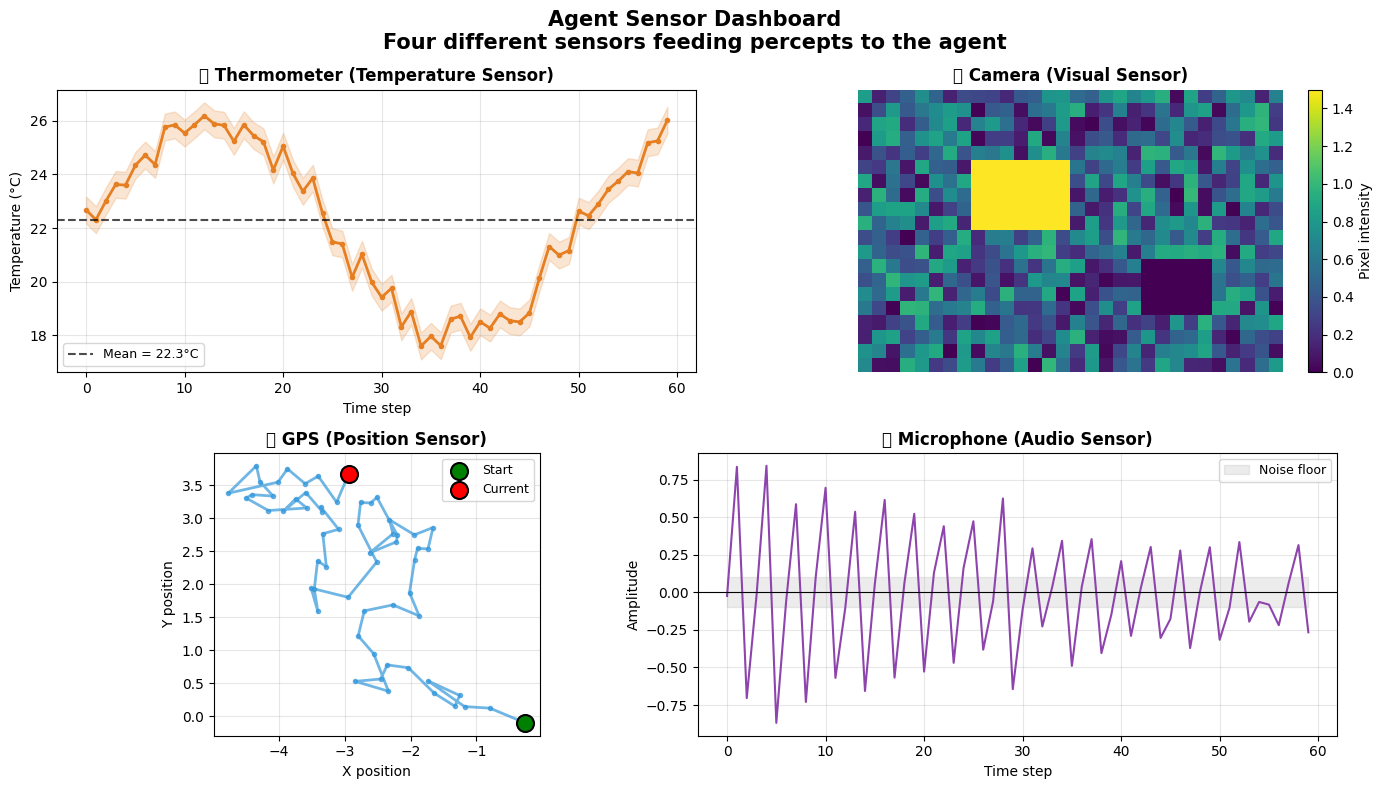

📌 Multiple sensors → richer percepts → better decisions.
📌 Each sensor has different noise characteristics, resolution, and range.


In [6]:
# ============================================================
# 5. SENSORS - Live Multi-Sensor Dashboard
# ============================================================
import matplotlib.pyplot as plt
import numpy as np

np.random.seed(7)
t = np.arange(60)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle("Agent Sensor Dashboard\n"
             "Four different sensors feeding percepts to the agent",
             fontsize=15, fontweight='bold')

# --- Temperature (smooth with noise) ---
temp = 22 + 4*np.sin(t/8) + np.random.randn(60)*0.4
axes[0, 0].plot(t, temp, color='#E67E22', lw=2, marker='o', markersize=3)
axes[0, 0].fill_between(t, temp - 0.5, temp + 0.5,
                         alpha=0.2, color='#E67E22')
axes[0, 0].axhline(temp.mean(), color='black', ls='--',
                   lw=1.5, alpha=0.7,
                   label=f'Mean = {temp.mean():.1f}°C')
axes[0, 0].set_title("🌡️ Thermometer (Temperature Sensor)",
                     fontweight='bold', fontsize=12)
axes[0, 0].set_ylabel("Temperature (°C)", fontsize=10)
axes[0, 0].set_xlabel("Time step", fontsize=10)
axes[0, 0].legend(fontsize=9)
axes[0, 0].grid(alpha=0.3)

# --- Camera (image) ---
camera_img = np.random.rand(20, 30)
camera_img[5:10, 8:15] = 1.5
camera_img[12:16, 20:25] = 0.0
im = axes[0, 1].imshow(camera_img, cmap='viridis')
axes[0, 1].set_title("📷 Camera (Visual Sensor)",
                     fontweight='bold', fontsize=12)
axes[0, 1].axis('off')
plt.colorbar(im, ax=axes[0, 1], fraction=0.046, pad=0.04,
             label='Pixel intensity')

# --- GPS (2D path) ---
x = np.cumsum(np.random.randn(60)*0.3)
y = np.cumsum(np.random.randn(60)*0.3)
axes[1, 0].plot(x, y, color='#3498DB', lw=2,
                marker='o', markersize=3, alpha=0.7)
axes[1, 0].scatter([x[0]], [y[0]], color='green', s=150,
                   label='Start', zorder=5, edgecolor='black', lw=1.5)
axes[1, 0].scatter([x[-1]], [y[-1]], color='red', s=150,
                   label='Current', zorder=5, edgecolor='black', lw=1.5)
axes[1, 0].set_title("🛰️ GPS (Position Sensor)",
                     fontweight='bold', fontsize=12)
axes[1, 0].legend(fontsize=9)
axes[1, 0].set_aspect('equal')
axes[1, 0].grid(alpha=0.3)
axes[1, 0].set_xlabel("X position", fontsize=10)
axes[1, 0].set_ylabel("Y position", fontsize=10)

# --- Microphone (audio waveform) ---
audio = np.sin(2*np.pi*t/3) * np.exp(-t/40) + np.random.randn(60)*0.1
axes[1, 1].plot(t, audio, color='#8E44AD', lw=1.5)
axes[1, 1].axhline(0, color='black', lw=0.8)
axes[1, 1].fill_between(t, -0.1, 0.1, alpha=0.15, color='gray',
                         label='Noise floor')
axes[1, 1].set_title("🎤 Microphone (Audio Sensor)",
                     fontweight='bold', fontsize=12)
axes[1, 1].set_ylabel("Amplitude", fontsize=10)
axes[1, 1].set_xlabel("Time step", fontsize=10)
axes[1, 1].legend(fontsize=9)
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("📌 Multiple sensors → richer percepts → better decisions.")
print("📌 Each sensor has different noise characteristics, resolution, and range.")

# 6. Actuators

📚 **Detailed Notes:**

**Actuators** = components that take commands from the agent and produce physical/virtual effects on the environment.

**Types of actuators:**

- **Physical:** motors, wheels, robotic arms, speakers, screens, LEDs
- **Virtual:** HTTP requests, database writes, function calls, API triggers

**Key properties:**

- **Precision:** how accurately actions are executed
- **Range:** the extent of action possibilities
- **Latency:** time from command to effect
- **Power/cost:** energy or compute required

**Action space:** the set of all possible actions

- **Discrete:** finite set (e.g., up/down/left/right)
- **Continuous:** infinite set (e.g., steering angle 0–360°)

**Actuator noise** can make actions stochastic.

💻 **Visual Code — Animated robot arm actuators:**

In [ ]:
# ============================================================
# 6. ACTUATORS - Animated Robot Arm
# ============================================================
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

fig, ax = plt.subplots(figsize=(9, 9))
ax.set_xlim(-2.8, 2.8)
ax.set_ylim(-2.8, 2.8)
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)
ax.set_title("Robotic Arm - Two Actuators in Motion\n"
             "Each joint = one actuator; purple trail = reachable workspace",
             fontweight='bold', fontsize=13)
ax.set_xlabel("X position", fontsize=11)
ax.set_ylabel("Y position", fontsize=11)

# --- Robot arm segments ---
L1, L2 = 1.5, 1.2

base, = ax.plot([0], [0], 's', markersize=18, color='black',
                zorder=10, label='Base')
arm1, = ax.plot([], [], '-', lw=10, color='#E74C3C',
                solid_capstyle='round', zorder=5, label='Actuator 1 (shoulder)')
arm2, = ax.plot([], [], '-', lw=8, color='#3498DB',
                solid_capstyle='round', zorder=5, label='Actuator 2 (elbow)')
joint, = ax.plot([], [], 'o', markersize=14, color='yellow',
                 markeredgecolor='black', markeredgewidth=2, zorder=8,
                 label='Joint')
tip, = ax.plot([], [], 'o', markersize=12, color='#27AE60',
               markeredgecolor='black', markeredgewidth=2, zorder=8,
               label='End effector')

trail_x, trail_y = [], []
trail, = ax.plot([], [], '-', color='#9B59B6', lw=1.5, alpha=0.6,
                 zorder=3, label='Trail (workspace)')

# --- Angle display ---
angle_text = ax.text(-2.6, 2.4, "", fontsize=11, family='monospace',
                     bbox=dict(boxstyle="round", facecolor="#FFF3CD",
                               edgecolor="#FFC107", lw=1.5), zorder=10)

ax.legend(loc='lower right', fontsize=9, framealpha=0.9)

def update(frame):
    t = frame * 0.1
    theta1 = np.pi/2 + 0.8*np.sin(t)
    theta2 = np.pi/4 + 1.2*np.cos(t*1.3)

    x1 = L1 * np.cos(theta1)
    y1 = L1 * np.sin(theta1)
    x2 = x1 + L2 * np.cos(theta1 + theta2)
    y2 = y1 + L2 * np.sin(theta1 + theta2)

    arm1.set_data([0, x1], [0, y1])
    arm2.set_data([x1, x2], [y1, y2])
    joint.set_data([x1], [y1])
    tip.set_data([x2], [y2])

    trail_x.append(x2)
    trail_y.append(y2)
    trail.set_data(trail_x[-100:], trail_y[-100:])

    angle_text.set_text(
        f"θ₁ = {np.degrees(theta1):6.1f}°\n"
        f"θ₂ = {np.degrees(theta2):6.1f}°\n"
        f"Tip = ({x2:+.2f}, {y2:+.2f})"
    )
    return arm1, arm2, joint, tip, trail, angle_text

anim = FuncAnimation(fig, update, frames=200, interval=40,
                     blit=True, repeat=True)
plt.close()
display(HTML(anim.to_jshtml()))

# 7. Agent Function

📚 **Detailed Notes:**

**Agent function** is a mathematical abstraction: **f: P\* → A**

- **P\*** = set of all possible percept histories (sequences)
- **A** = set of all possible actions

It describes **what** the agent does, not **how**.

Two agents are **behaviorally identical** iff they have the same agent function.

**Why is it useful?** It lets us reason about agents mathematically before implementing them.

**Size of the agent function:** for a finite environment, the function can be enormous. A vacuum cleaner with 2 locations × 2 states × T steps has 4^T entries. This is why we don't use lookup tables in practice.

The **agent program** is the actual implementation, which may compute the function efficiently.

💻 **Visual Code — Heatmap of agent function:**

In [ ]:
# ============================================================
# 7. AGENT FUNCTION - Heatmap of Mapping
# ============================================================
import matplotlib.pyplot as plt
import numpy as np

# --- Percept history → action (as a 2D heatmap) ---
histories = ["[]", "[dirty]", "[clean]", "[c,d]", "[c,c]",
             "[d,d]", "[c,c,d]", "[d,c,d]", "[c,c,c]"]
actions   = ["noop", "suck", "move", "suck", "move",
             "suck", "suck", "suck", "move"]
action_codes = {"noop": 0, "move": 1, "suck": 2}

values = np.array([action_codes[a] for a in actions]).reshape(3, 3)

fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(values, cmap='RdYlGn', vmin=0, vmax=2)

# --- Annotate each cell ---
for i in range(3):
    for j in range(3):
        idx = i * 3 + j
        ax.text(j, i, f"{histories[idx]}\n→\n{actions[idx]}",
                ha='center', va='center', fontsize=11,
                fontweight='bold',
                color='white' if values[i, j] > 1 else 'black')

ax.set_xticks([])
ax.set_yticks([])
ax.set_title("Agent Function Heatmap\n"
             "Every percept history maps to exactly one action",
             fontweight='bold', fontsize=13)

# --- Colorbar ---
cbar = plt.colorbar(im, ax=ax, ticks=[0, 1, 2], shrink=0.8)
cbar.ax.set_yticklabels(['noop', 'move', 'suck'], fontsize=11)
cbar.set_label('Action type', fontsize=11)

# --- Legend ---
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#E74C3C', label='noop (0)'),
    Patch(facecolor='#F1C40F', label='move (1)'),
    Patch(facecolor='#27AE60', label='suck (2)'),
]
ax.legend(handles=legend_elements, loc='upper left',
          bbox_to_anchor=(1.25, 1), fontsize=10)

plt.tight_layout()
plt.show()

print("📌 Every percept history maps to exactly one action.")
print("📌 This is a deterministic mapping — same input always gives same output.")

# 8. Agent Program

📚 **Detailed Notes:**

The **agent program** is a concrete implementation of the agent function.

Runs on the **architecture** (CPU, robot body, cloud VM).

**Implementation strategies:**

- **Lookup table** — enumerate all percepts → actions (impractical for large spaces)
- **Rule-based** — if-then conditions
- **Search-based** — explore state space
- **Learning-based** — neural networks, reinforcement learning
- **Hybrid** — combine multiple approaches

**Efficiency matters:** the same agent function can be implemented with very different performance characteristics.

In Python, an agent program is typically a class with a `__call__` or `act` method.

💻 **Visual Code — Comparing program action distributions:**

In [ ]:
# ============================================================
# 8. AGENT PROGRAM - Action Distribution Comparison
# ============================================================
import matplotlib.pyplot as plt
import random
from collections import Counter

# --- Two different agent programs ---
class RuleProgram:
    """A rule-based agent program: specific percept → specific action."""
    def __call__(self, percept):
        if percept == "dirty": return "suck"
        if percept == "A":     return "right"
        if percept == "B":     return "left"
        return "noop"

class RandomProgram:
    """A random agent program: picks any action regardless of percept."""
    def __call__(self, percept):
        return random.choice(["suck", "right", "left", "noop"])

# --- Generate random percepts ---
percepts = [random.choice(["dirty", "clean", "A", "B"]) for _ in range(500)]

# --- Run both programs ---
rule_actions   = [RuleProgram()(p) for p in percepts]
random_actions = [RandomProgram()(p) for p in percepts]

rule_counts   = Counter(rule_actions)
random_counts = Counter(random_actions)
all_actions   = ["suck", "right", "left", "noop"]

rule_vals   = [rule_counts.get(a, 0)   for a in all_actions]
random_vals = [random_counts.get(a, 0) for a in all_actions]

# --- Plot comparison ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

x = range(len(all_actions))
w = 0.38

# Left: bar chart
bars1 = ax1.bar([i - w/2 for i in x], rule_vals, w,
                label="Rule-Based Program", color='#27AE60',
                edgecolor='black', lw=1.5)
bars2 = ax1.bar([i + w/2 for i in x], random_vals, w,
                label="Random Program", color='#E74C3C',
                edgecolor='black', lw=1.5)

# Add value labels
for bars in [bars1, bars2]:
    for bar in bars:
        h = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2, h + 3,
                 str(int(h)), ha='center', fontsize=10, fontweight='bold')

ax1.set_xticks(x)
ax1.set_xticklabels(all_actions, fontsize=11)
ax1.set_ylabel("Frequency (out of 500)", fontsize=12)
ax1.set_title("Agent Program: Action Distributions\n"
              "Rule-based vs Random program",
              fontweight='bold', fontsize=13)
ax1.legend(fontsize=10)
ax1.grid(alpha=0.3, axis='y')

# Right: pie chart for rule-based
rule_pie_vals = [rule_counts.get(a, 0) for a in all_actions if rule_counts.get(a, 0) > 0]
rule_pie_labels = [a for a in all_actions if rule_counts.get(a, 0) > 0]
rule_pie_colors = ['#27AE60', '#F39C12', '#3498DB', '#9B59B6'][:len(rule_pie_vals)]

ax2.pie(rule_pie_vals, labels=rule_pie_labels, autopct='%1.0f%%',
        colors=rule_pie_colors, startangle=90,
        wedgeprops=dict(edgecolor='black', lw=2))
ax2.set_title("Rule-Based Program\nAction Distribution",
              fontweight='bold', fontsize=13)

plt.tight_layout()
plt.show()

print("📌 Rule-based program produces a structured policy:")
print(f"   - 'suck' fires {rule_counts.get('suck', 0)} times (when percept = 'dirty')")
print(f"   - 'right' fires {rule_counts.get('right', 0)} times (when percept = 'A')")
print(f"   - 'left' fires {rule_counts.get('left', 0)} times (when percept = 'B')")
print(f"   - 'noop' fires {rule_counts.get('noop', 0)} times (when percept = 'clean')")
print("\n📌 Random program spreads actions uniformly — it ignores the percept entirely.")

# 9. Agent Architecture

📚 **Detailed Notes:**

**Architecture** = the underlying computing substrate that executes the agent program.

**Types of architecture:**

- **Reactive architecture:** direct stimulus-response, no memory
- **Deliberative architecture:** maintains world model, plans ahead
- **Hybrid:** combines reactive and deliberative layers
- **Subsumption architecture (Brooks):** layered behaviors

**Hardware examples:** CPU, GPU, FPGA, robotic chassis

**Software examples:** OS process, container, cloud VM

**Key formula:** **Agent = Architecture + Program**

**Architecture determines:**

- How fast decisions can be made
- How much memory is available
- What sensors/actuators can be attached

💻 **Visual Code — Layered architecture diagram:**

In [ ]:
# ============================================================
# 9. AGENT ARCHITECTURE - Layered Block Diagram
# ============================================================
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, ax = plt.subplots(figsize=(11, 9))
ax.set_xlim(0, 11)
ax.set_ylim(0, 10)
ax.axis('off')
ax.set_title("Agent Architecture: Layered View\n"
             "Data flows DOWN, Feedback flows UP",
             fontweight='bold', fontsize=15)

# --- Layers: (label, y, color, description) ---
layers = [
    ("Sensors Layer",          8.5, "#F39C12", "Cameras, LIDAR, mic"),
    ("Perception Module",      7.0, "#F1C40F", "Filtering, fusion"),
    ("World Model",            5.5, "#3498DB", "Internal state / belief"),
    ("Decision Engine",        4.0, "#9B59B6", "Agent program"),
    ("Action Planner",         2.5, "#E67E22", "Sequence actions"),
    ("Actuators Layer",        1.0, "#E74C3C", "Motors, speakers, APIs"),
]

for label, y, color, desc in layers:
    # Main box
    box = mpatches.FancyBboxPatch(
        (1, y - 0.45), 5.5, 0.9,
        boxstyle="round,pad=0.1",
        facecolor=color, edgecolor='black', lw=2.5, zorder=3
    )
    ax.add_patch(box)
    ax.text(3.75, y, label, ha='center', va='center',
            color='white', fontweight='bold', fontsize=12, zorder=4)

    # Description box
    desc_box = mpatches.FancyBboxPatch(
        (7, y - 0.35), 3.5, 0.7,
        boxstyle="round,pad=0.08",
        facecolor='#F8F9FA', edgecolor=color, lw=1.5, zorder=3
    )
    ax.add_patch(desc_box)
    ax.text(8.75, y, desc, ha='center', va='center',
            fontsize=10, style='italic', color='#333', zorder=4)

    # Arrow from main box to description
    ax.annotate("", xy=(7, y), xytext=(6.5, y),
                arrowprops=dict(arrowstyle="->", lw=1.5,
                                color=color, alpha=0.7), zorder=2)

# --- Bidirectional arrows between layers ---
for y1, y2 in zip([8.05, 6.55, 5.05, 3.55, 2.05],
                  [7.45, 5.95, 4.45, 2.95, 1.45]):
    # Down arrow (data)
    ax.annotate("", xy=(2.5, y2), xytext=(2.5, y1),
                arrowprops=dict(arrowstyle="-|>", lw=2.5,
                                color='#2C3E50'), zorder=2)
    # Up arrow (feedback)
    ax.annotate("", xy=(5, y1), xytext=(5, y2),
                arrowprops=dict(arrowstyle="-|>", lw=2.5,
                                color='#95A5A6'), zorder=2)

# --- Legend ---
ax.plot([], [], color='#2C3E50', lw=2.5, label='Data flow (down)')
ax.plot([], [], color='#95A5A6', lw=2.5, label='Feedback (up)')
ax.legend(loc='upper left', fontsize=10, framealpha=0.9)

plt.tight_layout()
plt.show()

print("📌 Sensors → Perception → World Model → Decision → Action")
print("📌 Architecture = the computing substrate that runs the agent program.")

# 10. Agent–Environment Interaction

📚 **Detailed Notes:**

The complete interaction produces a **percept sequence** and an **action sequence**.

Formally: at time **t**, the agent receives percept **p_t** and issues action **a_t**.

**Environment dynamics:** p_{t+1} = env(p_t, a_t) (for deterministic envs).

**Interaction outcomes:**

- **Episodic:** previous actions don't affect current percepts
- **Sequential:** actions compound

**Learning opportunities:** from each interaction, the agent can update its model.

**Key loop invariant:** the agent never sees the environment directly — only through sensors.

💻 **Visual Code — Animated vacuum cleaner on 2×2 grid:**

In [ ]:
# ============================================================
# 10. AGENT-ENVIRONMENT INTERACTION - Animated Vacuum
# ============================================================
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

# --- Environment: 2x2 grid, 1 = dirty, 0 = clean ---
grid = np.array([[1, 1],
                 [0, 1]])

fig, ax = plt.subplots(figsize=(8, 7))
ax.set_xlim(-0.5, 1.5)
ax.set_ylim(-0.5, 1.5)
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(['A', 'B'], fontsize=13, fontweight='bold')
ax.set_yticklabels(['bottom', 'top'], fontsize=12)
ax.invert_yaxis()
ax.set_title("Vacuum Agent Cleaning\n"
             "Watch dirty cells turn clean as the agent visits them",
             fontweight='bold', fontsize=13)

# --- Grid image ---
img = ax.imshow(grid, cmap='YlOrBr', vmin=0, vmax=1, alpha=0.7)

# --- Robot marker ---
robot, = ax.plot([0], [0], 'o', markersize=35, color='#3498DB',
                 markeredgecolor='black', markeredgewidth=2.5,
                 zorder=5, label='Vacuum Agent')

# --- Status text ---
status = ax.text(0.5, -0.65, "", ha='center', fontsize=12,
                 fontweight='bold', color='#2C3E50',
                 bbox=dict(boxstyle="round", facecolor="#FFF3CD",
                           edgecolor="#FFC107", lw=2))

# --- Dirt counter ---
dirt_text = ax.text(1.45, 1.45, "", ha='right', va='top',
                    fontsize=11, fontweight='bold',
                    bbox=dict(boxstyle="round", facecolor="#FDEDEC",
                              edgecolor="#E74C3C", lw=1.5))

ax.legend(loc='lower right', fontsize=10)

# --- Snake path through 4 cells ---
path = [(0, 0), (0, 1), (1, 1), (1, 0),
        (0, 0), (0, 1), (1, 1), (1, 0)]

# --- Track original dirt count ---
initial_dirt = grid.sum()

def update(frame):
    i, j = path[frame % len(path)]

    # Move robot
    robot.set_data([j], [i])

    # Clean cell when visited
    action = "SUCK" if grid[i, j] == 1 else "MOVE"
    if grid[i, j] == 1:
        grid[i, j] = 0
        img.set_data(grid)

    # Update status
    cell_name = ['A', 'B'][j]
    location = 'top' if i == 0 else 'bottom'
    status.set_text(f"Agent at ({cell_name}, {location})  |  "
                    f"Action: {action}  |  "
                    f"Dirty cells left: {grid.sum()}/{initial_dirt}")

    # Update dirt counter
    dirt_text.set_text(f"🧹 Cleaned: {initial_dirt - grid.sum()}/{initial_dirt}")

    return robot, img, status, dirt_text

anim = FuncAnimation(fig, update, frames=len(path) * 2,
                     interval=700, repeat=True, blit=False)
plt.close()
display(HTML(anim.to_jshtml()))

# 11. Rational Agents

📚 **Detailed Notes:**

A **rational agent** at any moment selects the action that **maximizes expected performance**, given:

1. Its **performance measure**
2. Its **prior knowledge**
3. Its **percept sequence** to date
4. The **actions available**

**Rational ≠ omniscient:** the agent doesn't know everything about the future.

**Rational ≠ clairvoyant:** the agent may fail due to unforeseen events.

**Rational ≠ perfect:** decisions are based on **expected** outcomes.

**Example:** A rational driver slows down in fog — even if the road is actually clear.

**Deliberation cost:** sometimes the rational action is to act quickly with less thinking.

💻 **Visual Code — Action utility bar chart with expected values:**

In [ ]:
# ============================================================
# 11. RATIONAL AGENTS - Expected Utility Comparison
# ============================================================
import matplotlib.pyplot as plt
import numpy as np

# --- Define actions with probabilistic outcomes ---
actions = ["Charge\n(reckless)", "Slow down", "Stop", "Turn back"]

# Outcomes: [P(safe), P(bad)]
outcomes = {
    "Charge\n(reckless)":   [0.7, 0.3],
    "Slow down":            [0.95, 0.05],
    "Stop":                 [1.0, 0.0],
    "Turn back":            [1.0, 0.0],
}

# Values: [value if safe, value if bad]
values = {
    "Charge\n(reckless)":   [+10, -100],
    "Slow down":            [+5, -50],
    "Stop":                 [0, 0],
    "Turn back":            [-2, 0],
}

# --- Compute expected values ---
EVs = {}
for a in actions:
    EV = sum(p * v for p, v in zip(outcomes[a], values[a]))
    EVs[a] = EV

best = max(EVs, key=EVs.get)

# --- Plot ---
fig, ax = plt.subplots(figsize=(11, 6))

colors = ['#27AE60' if a == best else '#E74C3C' for a in actions]
bars = ax.bar(actions, [EVs[a] for a in actions],
              color=colors, edgecolor='black', lw=2, width=0.6)

# Add value labels
for bar, a in zip(bars, actions):
    h = bar.get_height()
    offset = 3 if h >= 0 else -8
    ax.text(bar.get_x() + bar.get_width()/2, h + offset,
            f"EV = {EVs[a]:+.1f}", ha='center',
            fontweight='bold', fontsize=11,
            color='#27AE60' if a == best else '#E74C3C')

# Highlight best
ax.annotate(f"✅ Rational choice: {best}",
            xy=(actions.index(best), EVs[best]),
            xytext=(actions.index(best) + 0.5, EVs[best] + 15),
            fontsize=12, fontweight='bold', color='#27AE60',
            arrowprops=dict(arrowstyle='->', color='#27AE60', lw=2),
            bbox=dict(boxstyle="round", facecolor="#D5F5E3",
                      edgecolor="#27AE60", lw=1.5))

ax.axhline(0, color='black', lw=1)
ax.set_ylabel("Expected Value", fontsize=12)
ax.set_title("Rational Agent: Expected Utility Comparison\n"
             "The rational agent picks the action with the highest EV",
             fontweight='bold', fontsize=13)
ax.grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

# --- Print detailed breakdown ---
print("📌 Expected Value breakdown:")
print("-" * 50)
for a in actions:
    p_safe, p_bad = outcomes[a]
    v_safe, v_bad = values[a]
    EV = p_safe * v_safe + p_bad * v_bad
    print(f"  {a.replace(chr(10), ' '):18s} → "
          f"P(safe)={p_safe:.2f} × {v_safe:+d} + "
          f"P(bad)={p_bad:.2f} × {v_bad:+d} = {EV:+.1f}")
print("-" * 50)
print(f"📌 Rational choice: {best} (EV = {EVs[best]:+.1f})")
print("📌 Rationality = maximizing expected value, not guaranteeing success.")

# 12. Rationality

📚 **Detailed Notes:**

**Rationality** is relative to the **performance measure**, **prior knowledge**, **available actions**, and **percept sequence**.

A rational agent must:

1. **Gather information** when useful (exploration)
2. **Choose actions** that maximize expected performance
3. **Balance** short-term vs. long-term goals

**Not rational:**

- Acting randomly without purpose
- Ignoring available information
- Making decisions that contradict the goal

**Misconception:** "Rational" doesn't mean "logical" or "unemotional" — it means maximizing expected utility.

**Bounded rationality:** agents have limited compute/time, so they make "good enough" decisions.

💻 **Visual Code — Two distributions: safe vs. risky:**

In [ ]:
# ============================================================
# 12. RATIONALITY - Risk vs Reward Distributions
# ============================================================
import matplotlib.pyplot as plt
import numpy as np

np.random.seed(1)

# --- Generate outcome distributions ---
safe   = np.random.normal(5, 1.5, 3000)
risky  = np.random.choice([-20, 15], 3000, p=[0.6, 0.4])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# --- Safe choice ---
ax1.hist(safe, bins=40, color='#27AE60', alpha=0.75,
         edgecolor='black', lw=1.5)
ax1.axvline(safe.mean(), color='black', lw=2.5, linestyle='--',
            label=f'Mean = {safe.mean():.2f}')
ax1.axvline(safe.mean() + safe.std(), color='gray', lw=1.5,
            linestyle=':', label=f'±1 SD = {safe.std():.2f}')
ax1.axvline(safe.mean() - safe.std(), color='gray', lw=1.5, linestyle=':')
ax1.set_title(f"Safe Choice\nMean = {safe.mean():.2f}, "
              f"Std = {safe.std():.2f}",
              fontweight='bold', fontsize=13)
ax1.set_xlabel("Outcome value", fontsize=11)
ax1.set_ylabel("Frequency", fontsize=11)
ax1.legend(fontsize=10)
ax1.grid(alpha=0.3)

# --- Risky choice ---
ax2.hist(risky, bins=40, color='#E74C3C', alpha=0.75,
         edgecolor='black', lw=1.5)
ax2.axvline(risky.mean(), color='black', lw=2.5, linestyle='--',
            label=f'Mean = {risky.mean():.2f}')
ax2.set_title(f"Risky Choice\nMean = {risky.mean():.2f}, "
              f"Std = {risky.std():.2f}",
              fontweight='bold', fontsize=13)
ax2.set_xlabel("Outcome value", fontsize=11)
ax2.legend(fontsize=10)
ax2.grid(alpha=0.3)

# --- Annotations ---
ax1.text(0.02, 0.95, "✅ Low variance\nPredictable outcomes",
         transform=ax1.transAxes, fontsize=11, fontweight='bold',
         color='#27AE60', va='top',
         bbox=dict(boxstyle="round", facecolor="#D5F5E3",
                   edgecolor="#27AE60", lw=1.5))
ax2.text(0.02, 0.95, "⚠️ High variance\nUnpredictable outcomes",
         transform=ax2.transAxes, fontsize=11, fontweight='bold',
         color='#E74C3C', va='top',
         bbox=dict(boxstyle="round", facecolor="#FDEDEC",
                   edgecolor="#E74C3C", lw=1.5))

plt.tight_layout()
plt.show()

print(f"📌 Rational agent compares EVs:")
print(f"   Safe choice:  EV = {safe.mean():.2f}  (low risk)")
print(f"   Risky choice: EV = {risky.mean():.2f}  (high risk)")
print(f"\n📌 If goal = maximize long-term average → choose risky IF EV is higher")
print(f"📌 If goal = minimize risk → choose safe regardless of EV")
print("📌 Rationality depends on the performance measure!")

# 13. Performance Measures

📚 **Detailed Notes:**

**Performance measure** = objective criterion for evaluating the agent's behavior.

**Good measures are:**

1. **Objective** — not subjective opinions
2. **Measurable** — quantifiable numbers
3. **Aligned with true goals** — no perverse incentives

**Vacuum cleaner example:**

- Amount of dirt cleaned
- Battery consumed
- Time taken
- Noise generated

**Self-driving car example:**

- Safety (accidents per km)
- Time to destination
- Fuel efficiency
- Passenger comfort
- Legal compliance

**Design pitfalls:**

- Rewarding "cleaning" may lead to hiding dirt
- Rewarding "speed" may lead to dangerous driving
- Rewarding "engagement" on social media may lead to addictive content

**Multiple objectives:** often combined via weights: `score = w₁·safety + w₂·speed - w₃·cost`

💻 **Visual Code — Multi-objective trade-off:**

In [ ]:
# ============================================================
# 13. PERFORMANCE MEASURES - Multi-Objective Trade-Off
# ============================================================
import matplotlib.pyplot as plt
import numpy as np

# --- Define strategies and their scores across 4 metrics ---
strategies = ["Aggressive", "Balanced", "Cautious", "Eco"]
metrics = {
    "Aggressive": {"Speed": 9, "Safety": 3, "Fuel": 4, "Comfort": 4},
    "Balanced":   {"Speed": 7, "Safety": 7, "Fuel": 6, "Comfort": 7},
    "Cautious":   {"Speed": 5, "Safety": 9, "Fuel": 7, "Comfort": 8},
    "Eco":        {"Speed": 4, "Safety": 8, "Fuel": 10, "Comfort": 6},
}

categories = list(metrics["Balanced"].keys())
N = len(categories)
angles = np.linspace(0, 2*np.pi, N, endpoint=False).tolist()
angles += angles[:1]  # close the loop

# --- Radar chart ---
fig, ax = plt.subplots(figsize=(9, 9), subplot_kw=dict(polar=True))
colors = ["#E74C3C", "#F39C12", "#27AE60", "#3498DB"]

for strat, color in zip(strategies, colors):
    vals = [metrics[strat][c] for c in categories]
    vals += vals[:1]
    ax.plot(angles, vals, 'o-', lw=2.5, label=strat, color=color,
            markersize=6)
    ax.fill(angles, vals, alpha=0.12, color=color)

# --- Customize radar ---
ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=12, fontweight='bold')
ax.set_ylim(0, 10)
ax.set_yticks([2, 4, 6, 8, 10])
ax.set_yticklabels(['2', '4', '6', '8', '10'], fontsize=9, color='gray')
ax.set_title("Performance Measures: Strategy Comparison\n"
             "Each axis = one performance metric (higher = better)",
             fontweight='bold', fontsize=14, pad=25)
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.15),
          fontsize=11, title='Strategy', title_fontsize=12)

plt.tight_layout()
plt.show()

# --- Compute weighted scores ---
print("📌 Weighted scores (example weights: Safety=0.4, Speed=0.3, Fuel=0.2, Comfort=0.1):")
print("-" * 70)
weights = {"Speed": 0.3, "Safety": 0.4, "Fuel": 0.2, "Comfort": 0.1}
for strat in strategies:
    score = sum(metrics[strat][m] * weights[m] for m in categories)
    print(f"   {strat:12s} → weighted score = {score:.2f}")
print("-" * 70)
print("📌 The performance measure determines which strategy is 'best'.")
print("📌 Change the weights → change the optimal strategy.")

# 14. PEAS Framework

📚 **Detailed Notes:**

**PEAS** = a systematic way to specify agent task environments.

- **P** — **Performance Measure:** what defines success
- **E** — **Environment:** where the agent operates
- **A** — **Actuators:** how the agent acts
- **S** — **Sensors:** how the agent perceives

**Why PEAS matters:**

1. Ensures you don't forget a component
2. Clarifies design requirements early
3. Communicates design intent to teams

**PEAS is not just for AI:** used in robotics, software architecture, and system design.

💻 **Visual Code — PEAS 4-quadrant diagram (colorful):**

In [ ]:
# ============================================================
# 14. PEAS FRAMEWORK - 4-Quadrant Diagram
# ============================================================
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, ax = plt.subplots(figsize=(11, 9))
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.axis('off')
ax.set_title("PEAS Framework: Self-Driving Car\n"
             "Performance · Environment · Actuators · Sensors",
             fontweight='bold', fontsize=15)

# --- Quadrants ---
quads = [
    ("P", "Performance",
     "• Safety (accidents/km)\n"
     "• Speed / travel time\n"
     "• Comfort (smoothness)\n"
     "• Legality (traffic laws)\n"
     "• Efficiency (fuel/energy)",
     (0.2, 5.2), "#F39C12"),
    ("E", "Environment",
     "• Roads & highways\n"
     "• Traffic (other vehicles)\n"
     "• Pedestrians\n"
     "• Weather conditions\n"
     "• Signage & signals",
     (5.1, 5.2), "#27AE60"),
    ("A", "Actuators",
     "• Steering wheel\n"
     "• Accelerator\n"
     "• Brakes\n"
     "• Turn signals\n"
     "• Horn",
     (0.2, 0.2), "#E74C3C"),
    ("S", "Sensors",
     "• Cameras (vision)\n"
     "• LIDAR (distance)\n"
     "• GPS (position)\n"
     "• Speedometer\n"
     "• Ultrasonic (proximity)",
     (5.1, 0.2), "#3498DB"),
]

for letter, title, desc, (x, y), color in quads:
    # Main quadrant box
    box = mpatches.FancyBboxPatch(
        (x, y), 4.7, 4.6,
        boxstyle="round,pad=0.15",
        facecolor=color, edgecolor='black', lw=2.5,
        alpha=0.92, zorder=3
    )
    ax.add_patch(box)

    # Letter + title
    ax.text(x + 2.35, y + 3.95, f"{letter}: {title}",
            ha='center', fontsize=15, color='white',
            fontweight='bold', zorder=4)

    # Description
    ax.text(x + 2.35, y + 1.8, desc,
            ha='center', va='center', fontsize=10.5,
            color='white', linespacing=1.6, zorder=4)

# --- Cross-hair lines ---
ax.plot([5, 5], [0.2, 9.8], color='black', lw=2, alpha=0.5, zorder=2)
ax.plot([0.2, 9.8], [5, 5], color='black', lw=2, alpha=0.5, zorder=2)

plt.tight_layout()
plt.show()

# 15. PEAS Examples

📚 **Detailed Notes:**

PEAS works for **any** agent, physical or virtual.

**Classic examples to remember:**

| **Agent** | **P (Performance)** | **E (Environment)** | **A (Actuators)** | **S (Sensors)** |
|---|---|---|---|---|
| Vacuum | Cleanliness, battery | Room, dirt | Wheels, suction | Dirt sensor |
| Chess AI | Win rate | 8×8 board | Move pieces | Board state |
| Self-driving | Safety, time | Roads, traffic | Steering, brakes | Cameras, LIDAR |
| Medical diagnosis | Accuracy, health | Hospital, records | Diagnoses, prescriptions | Symptoms, tests |
| Trading bot | Profit, risk | Markets, news | Buy/sell orders | Prices, indicators |
| Chatbot | User satisfaction | Conversations | Text responses | User input |
| Web crawler | Coverage, freshness | Internet | HTTP requests | HTML parsing |

**Tip:** When designing a new agent, always start with PEAS.

💻 **Visual Code — PEAS comparison table:**

In [ ]:
# ============================================================
# 15. PEAS EXAMPLES - Colored Comparison Table
# ============================================================
import matplotlib.pyplot as plt

# --- Data ---
data = [
    ["Agent", "Performance", "Environment", "Actuators", "Sensors"],
    ["Vacuum Robot", "Cleanliness, Battery", "Room, Dirt", "Wheels, Suction", "Dirt Sensor"],
    ["Chess AI", "Win Rate", "8x8 Board", "Move Pieces", "Board State"],
    ["Self-Driving Car", "Safety, Speed", "Roads, Traffic", "Steering, Brakes", "Cameras, LIDAR"],
    ["Medical Diagnosis", "Accuracy, Health", "Hospital, Records", "Diagnoses", "Symptoms, Tests"],
    ["Trading Bot", "Profit, Risk", "Markets, News", "Buy/Sell Orders", "Prices, Indicators"],
    ["Chatbot", "User Satisfaction", "Conversations", "Text Responses", "User Input"],
]

fig, ax = plt.subplots(figsize=(15, 6))
ax.axis('off')

# --- Create table ---
table = ax.table(cellText=data[1:], colLabels=data[0],
                 loc='center', cellLoc='left')
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 2.4)

# --- Color the header row ---
for j in range(len(data[0])):
    table[(0, j)].set_facecolor('#2C3E50')
    table[(0, j)].set_text_props(color='white', fontweight='bold',
                                  fontsize=11)
    table[(0, j)].set_height(0.15)

# --- Color the data rows ---
row_colors = ['#FDEBD0', '#D5F5E3', '#FADBD8', '#D6EAF8',
              '#E8DAEF', '#FCF3CF']
for i in range(1, len(data)):
    for j in range(len(data[0])):
        table[(i, j)].set_facecolor(row_colors[i-1])
        table[(i, j)].set_text_props(fontsize=10)
        table[(i, j)].set_height(0.12)

# --- Column coloring for emphasis ---
col_colors = ['#E67E22', '#27AE60', '#E74C3C', '#3498DB', '#9B59B6']
for j, col_color in enumerate(col_colors):
    table[(0, j)].set_edgecolor(col_color)
    table[(0, j)].set_linewidth(3)

plt.title("PEAS Across Common Agents\n"
          "P=Performance  E=Environment  A=Actuators  S=Sensors",
          fontweight='bold', fontsize=14, pad=25)
plt.tight_layout()
plt.show()
print("📌 Every agent — physical or virtual — can be specified with PEAS.")
print("📌 Use PEAS as your first design step for any new agent.")

# 16. Types of AI Environments

📚 **Detailed Notes:**

Environments are classified along **six+ dimensions**. The most important:

1. **Observability:** Full vs. Partial
2. **Determinism:** Deterministic vs. Stochastic
3. **Episodicity:** Episodic vs. Sequential
4. **Dynamics:** Static vs. Dynamic
5. **Continuity:** Discrete vs. Continuous
6. **Number of agents:** Single vs. Multi-agent
7. **Knowledge:** Known vs. Unknown

**Why classification matters:** it tells us how complex the agent needs to be.

**The hardest environment:** partially observable, stochastic, sequential, dynamic, continuous, multi-agent, unknown — e.g., real-world driving.

💻 **Visual Code — Radar chart comparing environments:**

In [ ]:
# ============================================================
# 16. TYPES OF AI ENVIRONMENTS - Multi-Agent Radar Chart
# ============================================================
import matplotlib.pyplot as plt
import numpy as np

# --- Dimensions (0 = hardest, 1 = easiest) ---
labels = ["Observable\n(1=full)", "Deterministic", "Episodic",
          "Static", "Discrete", "Single-Agent"]
N = len(labels)
angles = np.linspace(0, 2*np.pi, N, endpoint=False).tolist()
angles += angles[:1]

# --- Environment profiles ---
envs = {
    "Chess":            [1.0, 1.0, 0.0, 1.0, 1.0, 0.0],
    "Poker":            [0.3, 0.0, 0.0, 1.0, 1.0, 0.0],
    "Driving":          [0.3, 0.0, 0.0, 0.0, 0.0, 0.0],
    "Image Classifier": [1.0, 1.0, 1.0, 1.0, 1.0, 1.0],
}

fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))
colors = ["#E74C3C", "#3498DB", "#27AE60", "#9B59B6"]

for (name, vals), color in zip(envs.items(), colors):
    vals_plot = vals + vals[:1]
    ax.plot(angles, vals_plot, 'o-', lw=2.5, label=name,
            color=color, markersize=7)
    ax.fill(angles, vals_plot, alpha=0.12, color=color)

# --- Customize ---
ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontsize=11, fontweight='bold')
ax.set_ylim(0, 1.15)
ax.set_yticks([0.25, 0.5, 0.75, 1.0])
ax.set_yticklabels(['0.25', '0.50', '0.75', '1.00'],
                   fontsize=9, color='gray')
ax.set_title("Environment Classification Radar\n"
             "Larger area = easier environment for agents",
             fontweight='bold', fontsize=14, pad=25)
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.15),
          fontsize=11, title='Environment', title_fontsize=12)

plt.tight_layout()
plt.show()

print("📌 Chess & Image Classifier = simpler environments (easier for agents)")
print("📌 Poker = partially observable + stochastic + multi-agent (harder)")
print("📌 Driving = hardest environment (needs sophisticated agent)")
print("\n📌 The area of the shape indicates overall difficulty:")
for name, vals in envs.items():
    area = sum(vals) / len(vals)
    print(f"   {name:20s} → avg easiness = {area:.2f}")

# 17. Fully Observable Environments

📚 **Detailed Notes:**

The agent's sensors give it access to the **complete state** of the environment.

**Advantages:**

1. No need for internal memory
2. No uncertainty about current state
3. Simpler decision-making

**Examples:**

- Chess (all pieces visible)
- Solitaire
- Board games with open information

**Visualization:** the full grid is visible — no hidden cells.

💻 **Visual Code — Full vision grid with annotations:**

In [ ]:
# ============================================================
# 17. FULLY OBSERVABLE - Full Vision Grid
# ============================================================
import matplotlib.pyplot as plt
import numpy as np

# --- Grid: 1 = dirty, 0 = clean ---
grid = np.array([[1, 0, 1, 0],
                 [0, 1, 1, 0],
                 [1, 1, 0, 1],
                 [0, 0, 1, 1]])

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(grid, cmap='RdYlGn_r', vmin=0, vmax=1)

# --- Annotate each cell ---
for i in range(4):
    for j in range(4):
        label = "D" if grid[i, j] else "C"
        color = 'white' if grid[i, j] else 'black'
        ax.text(j, i, label, ha='center', va='center',
                color=color, fontweight='bold', fontsize=18)

# --- Grid lines ---
ax.set_xticks(np.arange(-0.5, 4, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 4, 1), minor=True)
ax.grid(which='minor', color='black', lw=2)
ax.tick_params(which='minor', length=0)

ax.set_xticks([])
ax.set_yticks([])
ax.set_title("FULLY OBSERVABLE\n"
             "👁️ Agent sees ALL 16 cells at once",
             fontweight='bold', fontsize=14)

# --- Legend ---
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#E74C3C', label='D = Dirty'),
    Patch(facecolor='#27AE60', label='C = Clean'),
]
ax.legend(handles=legend_elements, loc='upper left',
          bbox_to_anchor=(1.15, 1), fontsize=11)

# --- Dirt count ---
ax.text(1.5, -0.8, f"Total dirty cells: {grid.sum()}/16",
        ha='center', fontsize=12, fontweight='bold',
        bbox=dict(boxstyle="round", facecolor="#FFF3CD",
                  edgecolor="#FFC107", lw=1.5))

plt.tight_layout()
plt.show()
print("📌 'D' = dirty, 'C' = clean — all visible.")
print("📌 In a fully observable environment, the agent needs no memory.")

# 18. Partially Observable Environments

📚 **Detailed Notes:**

The agent sees only **part** of the state.

Requires **memory** and **belief state** (the agent's estimate of the world).

**Challenges:**

1. Hidden information must be inferred
2. Need probability distributions over possible states
3. Actions may be aimed at gathering information

**Examples:**

- Poker (hidden opponent cards)
- Self-driving in fog
- Robot with limited sensor range
- Medical diagnosis (internal body invisible)

**Key technique:** POMDPs (Partially Observable Markov Decision Processes).

💻 **Visual Code — Fog of war animation:**

In [ ]:
# ============================================================
# 18. PARTIALLY OBSERVABLE - Fog of War
# ============================================================
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

np.random.seed(42)

# --- Environment ---
grid = np.random.choice([0, 1], size=(5, 5), p=[0.4, 0.6])

fig, ax = plt.subplots(figsize=(8, 8))
ax.set_title("Partially Observable: Fog of War\n"
             "Agent only sees cells within Manhattan distance 1",
             fontweight='bold', fontsize=13)

# --- Base image ---
vis_img = ax.imshow(grid, cmap='RdYlGn_r', vmin=0, vmax=1)

# --- Fog overlay: 1 = foggy (hidden), 0 = clear (visible) ---
fog = ax.imshow(np.ones((5, 5)), cmap='gray', alpha=0.75, vmin=0, vmax=1)

# --- Robot marker ---
robot, = ax.plot([0], [0], 'o', markersize=25, color='#3498DB',
                 markeredgecolor='black', markeredgewidth=2.5,
                 zorder=5, label='Agent')

# --- Status text ---
status = ax.text(2, -0.8, "", ha='center', fontsize=11,
                 fontweight='bold',
                 bbox=dict(boxstyle="round", facecolor="#FFF3CD",
                           edgecolor="#FFC107", lw=1.5))

# --- Legend ---
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='gray', alpha=0.75, label='Fog (unseen)'),
    Patch(facecolor='#27AE60', label='Clean'),
    Patch(facecolor='#E74C3C', label='Dirty'),
]
ax.legend(handles=legend_elements, loc='upper left',
          bbox_to_anchor=(1.15, 1), fontsize=10)

# --- Sample path ---
path = [(0,0), (0,1), (0,2), (1,2), (2,2), (2,3), (3,3),
        (4,3), (4,4), (3,4), (2,4), (1,3), (0,3), (0,4)]

# --- Track cumulative revealed cells ---
revealed = np.zeros((5, 5))

def update(frame):
    i, j = path[frame % len(path)]

    # Compute visible cells (Manhattan distance ≤ 1)
    new_mask = np.ones((5, 5))
    for r in range(5):
        for c in range(5):
            if abs(r - i) + abs(c - j) <= 1:
                new_mask[r, c] = 0  # visible
                revealed[r, c] = 1

    fog.set_data(new_mask)
    robot.set_data([j], [i])

    status.set_text(f"Agent at ({i}, {j})  |  "
                    f"Revealed: {int(revealed.sum())}/25 cells")

    return vis_img, fog, robot, status

anim = FuncAnimation(fig, update, frames=len(path),
                     interval=600, repeat=True, blit=False)
plt.close()
display(HTML(anim.to_jshtml()))

# 19. Deterministic Environments

📚 Detailed Notes:

**Every action has exactly one outcome.**

Same state + same action = same next state, always.

**Advantages:**

1. Search algorithms work perfectly
2. Planning is straightforward
3. No probability theory needed

**Examples:**

- Chess, Checkers, Tic-Tac-Toe
- Puzzle games (Sudoku, Rubik's cube)
- Classic grid-world navigation

💻 Visual Code — Deterministic transition tree:

In [ ]:
# ============================================================
# 19. DETERMINISTIC - Branching Tree
# ============================================================
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 7))
ax.set_xlim(-1, 5)
ax.set_ylim(-0.5, 4.5)
ax.axis('off')
ax.set_title("Deterministic Transitions - One Path per Action\n"
             "Same state + same action = same next state, always",
             fontweight='bold', fontsize=14)

# --- Nodes ---
nodes = {
    "S0": (0, 2),
    "S1_up": (2, 3),   "S1_down": (2, 1),
    "S2_upup": (4, 3.7), "S2_updown": (4, 2.3),
    "S2_downup": (4, 1.7), "S2_downdown": (4, 0.3),
}

for name, (x, y) in nodes.items():
    color = "#3498DB" if name == "S0" else "#27AE60"
    ax.scatter([x], [y], s=1200, color=color, zorder=3,
               edgecolor='black', lw=2)
    ax.text(x, y, name, ha='center', va='center',
            color='white', fontweight='bold', fontsize=10, zorder=4)

# --- Edges ---
edges = [
    ("S0", "S1_up", "up"),
    ("S0", "S1_down", "down"),
    ("S1_up", "S2_upup", "up"),
    ("S1_up", "S2_updown", "down"),
    ("S1_down", "S2_downup", "up"),
    ("S1_down", "S2_downdown", "down"),
]

for src, dst, label in edges:
    x1, y1 = nodes[src]
    x2, y2 = nodes[dst]
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="-|>", lw=2.5, color='gray'),
                zorder=2)
    ax.text((x1 + x2)/2, (y1 + y2)/2 + 0.15, label,
            ha='center', fontsize=10, color='#E74C3C',
            fontweight='bold', zorder=5,
            bbox=dict(boxstyle="round", facecolor='white',
                      edgecolor='#E74C3C', lw=1, alpha=0.9))

# --- Annotations ---
ax.text(2, -0.2, "One action → exactly one next state",
        ha='center', fontsize=12, style='italic',
        color='#2C3E50',
        bbox=dict(boxstyle="round", facecolor="#D5F5E3",
                  edgecolor="#27AE60", lw=1.5))

plt.tight_layout()
plt.show()
print("📌 One action → exactly one next state.")
print("📌 No probability involved — planning is straightforward.")

# 20. Stochastic Environments

📚 Detailed Notes:

The same action can produce **different outcomes**.

Outcomes follow a **probability distribution**.

**Challenges:**

1. Need probability theory
2. Agent must maximize **expected** utility
3. Value iteration, MDPs, and reinforcement learning come into play

**Examples:**

- Dice games
- Driving in traffic (other drivers)
- Stock market trading
- Robot with noisy actuators

**Key idea:** planning for all possibilities, weighted by probability.

💻 Visual Code — Stochastic transition visualization:

In [ ]:
# ============================================================
# 20. STOCHASTIC - Probability of Outcomes
# ============================================================
import matplotlib.pyplot as plt

# --- Action: "try to move right" in a slippery environment ---
outcomes = ["Move right\n(80%)", "Stay\n(15%)", "Move left\n(5%)"]
probs    = [0.80, 0.15, 0.05]
states   = ["S_right", "S_stay", "S_left"]
colors   = ["#27AE60", "#F39C12", "#E74C3C"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# --- Left: Pie chart ---
wedges, texts, autotexts = ax1.pie(
    probs, labels=outcomes, colors=colors,
    autopct='%1.0f%%', startangle=90,
    wedgeprops=dict(edgecolor='black', lw=2.5),
    textprops=dict(fontsize=11, fontweight='bold')
)
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontsize(13)

ax1.set_title("Probability Distribution\n"
              "After action: 'move right'",
              fontweight='bold', fontsize=13)

# --- Right: Bar chart ---
bars = ax2.bar(states, probs, color=colors,
               edgecolor='black', lw=2, width=0.6)

for bar, p in zip(bars, probs):
    ax2.text(bar.get_x() + bar.get_width()/2, p + 0.02,
             f"{p:.2f}", ha='center', fontweight='bold',
             fontsize=13)

ax2.set_ylabel("Probability", fontsize=12)
ax2.set_ylim(0, 1.0)
ax2.set_title("Possible Next States\n"
              "Same action → multiple possible outcomes",
              fontweight='bold', fontsize=13)
ax2.grid(alpha=0.3, axis='y')

# --- Annotations ---
ax2.axhline(0.8, color='#27AE60', ls='--', lw=1.5, alpha=0.7)
ax2.text(2.3, 0.82, "80% chance", fontsize=10,
         color='#27AE60', fontweight='bold')

plt.tight_layout()
plt.show()
print("📌 Slippery floor: action 'right' has uncertain outcomes!")
print("📌 The agent must plan for all possibilities, weighted by probability.")

# 21. Episodic Environments

📚 Detailed Notes:

The agent's experience is divided into **independent episodes**.

Previous episodes have **no effect** on the current one.

**Advantages:** simple, no memory needed.

**Examples:**

- Image classification (each image is independent)
- Spam filter (each email independent)
- One-shot quiz answering
- Pattern recognition tasks

**Contrast:** episodic environments are easier than sequential ones.

💻 Visual Code — Independent episodes timeline:

In [ ]:
# ============================================================
# 21. EPISODIC - Independent Episodes
# ============================================================
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# --- Data: 6 emails, each classified independently ---
emails = ["win prize", "meeting at 5", "win money",
          "hello friend", "win lottery", "project update"]
labels = ["SPAM" if "win" in e else "HAM" for e in emails]
colors = ["#E74C3C" if l == "SPAM" else "#27AE60" for l in labels]
prob_spam = [0.95, 0.05, 0.92, 0.02, 0.98, 0.03]

fig, ax = plt.subplots(figsize=(13, 6))

for i, (e, l, c, p) in enumerate(zip(emails, labels, colors, prob_spam)):
    x = i * 1.9

    # --- Email box ---
    box = mpatches.FancyBboxPatch(
        (x, 2.2), 1.7, 1.4,
        boxstyle="round,pad=0.1",
        facecolor="#F4F4F4", edgecolor='black', lw=1.8
    )
    ax.add_patch(box)

    # Email text
    ax.text(x + 0.85, 3.1, e, ha='center', va='center',
            fontsize=9, fontweight='bold')

    # --- Arrow down to classification ---
    ax.annotate("", xy=(x + 0.85, 1.9), xytext=(x + 0.85, 2.2),
                arrowprops=dict(arrowstyle="-|>", lw=2, color='gray'))

    # --- Classification label ---
    ax.text(x + 0.85, 1.6, l, ha='center', fontsize=13,
            fontweight='bold', color=c)

    # --- Probability bar ---
    bar_width = 1.5 * p
    ax.barh(x + 0.85, bar_width, height=0.15, left=0,
            color=c, alpha=0.4)
    ax.text(x + 0.85, 1.15, f"P(SPAM) = {p:.2f}",
            ha='center', fontsize=8, color='#555')

    # --- Independence marker (dashed line between episodes) ---
    if i < len(emails) - 1:
        ax.plot([x + 1.8, x + 1.9], [1.0, 3.5],
                color='gray', linestyle='--', lw=1.5, alpha=0.6)
        ax.text(x + 1.85, 0.7, "independent", ha='center',
                fontsize=8, color='gray', rotation=90)

# --- Annotations ---
ax.text(5.5, 4.2, "EPISODIC ENVIRONMENT: Each email classified independently",
        ha='center', fontsize=14, fontweight='bold',
        bbox=dict(boxstyle="round", facecolor="#D5F5E3",
                  edgecolor="#27AE60", lw=2))

ax.text(5.5, 0.3, "Previous classifications do NOT affect current ones.",
        ha='center', fontsize=11, style='italic', color='#555')

ax.set_xlim(-0.5, 11.5)
ax.set_ylim(0, 4.8)
ax.axis('off')

plt.tight_layout()
plt.show()
print("📌 Episodic: each decision is independent of previous ones.")
print("📌 No memory needed — the agent can process each episode from scratch.")

# 22. Sequential Environments

📚 Detailed Notes:

Current decisions **affect future states and decisions**.

The agent needs **memory** and **planning**.

**Challenges:**

1. Delayed rewards (credit assignment problem)
2. Long-term consequences
3. Non-myopic decisions

**Examples:**

- Chess (every move affects the game)
- Driving (past position affects future route)
- Robot navigation
- Any game of strategy

💻 Visual Code — Sequential chain visualization:

In [ ]:
# ============================================================
# 22. SEQUENTIAL - Chain of Dependent Decisions
# ============================================================
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, ax = plt.subplots(figsize=(14, 6))
ax.set_xlim(-0.5, 10.5)
ax.set_ylim(-1.5, 1.8)
ax.axis('off')
ax.set_title("Sequential: Each Decision Affects the Next\n"
             "Action t changes State t+1, which changes Action t+1, and so on...",
             fontweight='bold', fontsize=14)

# --- Sequence: state → action → state → action ... ---
steps = [
    ("Start", "S0"),
    ("Move R", "S1"),
    ("Move R", "S2"),
    ("Pick up", "S3"),
    ("Move U", "S4"),
    ("Drop", "S5"),
]

for i, (action, state) in enumerate(steps):
    x = i * 1.8

    # --- State circle ---
    circle = mpatches.Circle(
        (x, 0.5), 0.45,
        facecolor='#3498DB', edgecolor='black', lw=2.5, zorder=3
    )
    ax.add_patch(circle)
    ax.text(x, 0.5, state, ha='center', va='center',
            color='white', fontweight='bold', fontsize=12, zorder=4)

    # --- Action label below ---
    ax.text(x, -0.3, action, ha='center', fontsize=11,
            fontweight='bold', color='#8E44AD',
            bbox=dict(boxstyle="round", facecolor="#F4ECF7",
                      edgecolor="#8E44AD", lw=1.5))

    # --- Arrow to next state ---
    if i < len(steps) - 1:
        ax.annotate("", xy=(x + 1.25, 0.5), xytext=(x + 0.5, 0.5),
                    arrowprops=dict(arrowstyle="-|>", lw=3,
                                    color='#E74C3C'), zorder=2)
        # Dependency label
        ax.text(x + 0.9, 0.95, f"S{i+1}", ha='center',
                fontsize=9, color='#E74C3C', fontweight='bold')

# --- Annotations ---
ax.text(5, 1.5, "Action t affects State t+1 → affects Action t+1 → ...",
        ha='center', fontsize=12, style='italic', color='#2C3E50',
        bbox=dict(boxstyle="round", facecolor="#FFF3CD",
                  edgecolor="#FFC107", lw=1.5))

ax.text(5, -1.0, "The agent must plan ahead — myopic (short-sighted) decisions fail.",
        ha='center', fontsize=11, style='italic', color='#555')

plt.tight_layout()
plt.show()
print("📌 Sequential: decisions compound over time.")
print("📌 The agent needs memory and planning to succeed.")

# 23. Static Environments

📚 Detailed Notes:

The environment **does not change** while the agent is deliberating.

**Advantages:** agent can take as long as it needs to think.

**Examples:**

- Crossword puzzles
- Chess with no clock
- Scheduling problems
- Route planning (before departing)

**Contrast:** dynamic environments require timely decisions.

💻 Visual Code — Static state being read repeatedly:

In [ ]:
# ============================================================
# 23. STATIC - Environment Doesn't Change While Thinking
# ============================================================
import matplotlib.pyplot as plt
import numpy as np

# --- The state (frozen) ---
state = np.array([[1, 0, 1],
                  [0, 1, 1],
                  [1, 0, 0]])

fig, axes = plt.subplots(1, 5, figsize=(16, 4))
fig.suptitle("Static Environment - State frozen while agent 'thinks'",
             fontweight='bold', fontsize=14)

for i, ax in enumerate(axes):
    # Same state every time
    im = ax.imshow(state, cmap='RdYlGn_r', vmin=0, vmax=1)

    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f"Read #{i+1}\n(same state)", fontsize=11,
                 fontweight='bold')

    # Add read counter
    ax.text(0.5, -0.2, f"t = {i+1}", transform=ax.transAxes,
            ha='center', fontsize=10, color='#555')

    # Annotate first read
    if i == 0:
        ax.set_ylabel("Environment", fontsize=11, fontweight='bold')

# --- Legend ---
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#E74C3C', label='Dirty (1)'),
    Patch(facecolor='#27AE60', label='Clean (0)'),
]
fig.legend(handles=legend_elements, loc='lower center',
           ncol=2, fontsize=11, frameon=True)

plt.tight_layout(rect=[0, 0.08, 1, 0.95])
plt.show()
print("📌 Static environment: nothing changes on its own.")
print("📌 The agent can take as long as needed to deliberate.")

# 24. Dynamic Environments

📚 Detailed Notes:

The environment **changes on its own** while the agent deliberates.

**Challenges:**

1. Agent must decide quickly
2. May need to re-plan
3. Real-time constraints

**Examples:**

- Driving (traffic moves)
- Stock market (prices fluctuate)
- Video games (opponents act)
- Air traffic control

**Technique:** **anytime algorithms** — return a good answer even if interrupted.

💻 Visual Code — Dynamic state evolving over time:

In [ ]:
# ============================================================
# 24. DYNAMIC - State Changes Over Time
# ============================================================
import matplotlib.pyplot as plt
import numpy as np

np.random.seed(42)

fig, axes = plt.subplots(1, 5, figsize=(16, 4))
fig.suptitle("Dynamic Environment - State changes on its own",
             fontweight='bold', fontsize=14)

for i, ax in enumerate(axes):
    # New state each time
    grid = np.random.choice([0, 1], size=(3, 3), p=[0.5, 0.5])
    im = ax.imshow(grid, cmap='RdYlGn_r', vmin=0, vmax=1)

    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f"Time {i+1}\n(changing)", fontsize=11,
                 fontweight='bold')

    # Add change indicator
    if i > 0:
        ax.text(0.5, -0.2, "⚠️ changed", transform=ax.transAxes,
                ha='center', fontsize=9, color='#E74C3C',
                fontweight='bold')

# --- Legend ---
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#E74C3C', label='Dirty (1)'),
    Patch(facecolor='#27AE60', label='Clean (0)'),
]
fig.legend(handles=legend_elements, loc='lower center',
           ncol=2, fontsize=11, frameon=True)

plt.tight_layout(rect=[0, 0.08, 1, 0.95])
plt.show()
print("📌 Dynamic environment: changes without the agent acting.")
print("📌 The agent must decide quickly — deliberation time matters.")

🎯 **Teaching Point:** In a dynamic environment, the world changes while the agent thinks. The agent can't afford to deliberate too long — by the time it decides, the state may have changed.

# 25. Discrete Environments

📚 Detailed Notes:

**States and actions are finite and countable.**

Easy to enumerate, search, and reason about.

**Examples:**

- Chess (finite board positions)
- Grid worlds
- Traffic light (red/yellow/green)
- Dice outcomes (1–6)

**Techniques:** BFS, DFS, A\*

💻 Visual Code — Discrete 5×5 grid world:

In [ ]:
# ============================================================
# 25. DISCRETE - Grid World
# ============================================================
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, ax = plt.subplots(figsize=(8, 8))
ax.set_xlim(-0.5, 4.5)
ax.set_ylim(-0.5, 4.5)
ax.set_xticks(range(5))
ax.set_yticks(range(5))
ax.set_xticklabels([])
ax.set_yticklabels([])
ax.invert_yaxis()
ax.grid(True, lw=2, color='#333')

# --- Start and goal ---
start = (0, 0)
goal  = (4, 4)

ax.add_patch(mpatches.Circle((start[1], start[0]), 0.35,
                              color='#27AE60', ec='black', lw=2.5))
ax.text(start[1], start[0], "S", ha='center', va='center',
        color='white', fontweight='bold', fontsize=16)

ax.add_patch(mpatches.Circle((goal[1], goal[0]), 0.35,
                              color='#E74C3C', ec='black', lw=2.5))
ax.text(goal[1], goal[0], "G", ha='center', va='center',
        color='white', fontweight='bold', fontsize=16)

# --- Obstacles ---
for (r, c) in [(1, 2), (2, 1), (3, 3)]:
    ax.add_patch(mpatches.Rectangle(
        (c - 0.4, r - 0.4), 0.8, 0.8,
        facecolor='#555', edgecolor='black', lw=2))

# --- Annotations ---
ax.set_title("Discrete Environment\n"
             "5×5 Grid with Obstacles — Finite states, finite actions",
             fontweight='bold', fontsize=13)

# --- Legend ---
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#27AE60', label='Start (S)'),
    Patch(facecolor='#E74C3C', label='Goal (G)'),
    Patch(facecolor='#555', label='Obstacle'),
]
ax.legend(handles=legend_elements, loc='upper left',
          bbox_to_anchor=(1.15, 1), fontsize=10)

plt.tight_layout()
plt.show()
print("📌 Finite states, finite actions — perfect for search algorithms.")
print("📌 The agent can enumerate all possibilities.")

🎯 **Teaching Point:** In a discrete environment, states and actions come from finite sets. The agent can enumerate possibilities and use search algorithms — perfect for BFS, DFS, or A\*.

# 26. Continuous Environments

📚 Detailed Notes:

States and/or actions take values from **continuous spaces** (real numbers).

**Challenges:**

1. Infinite possibilities → can't enumerate
2. Need calculus, control theory, or function approximation

**Examples:**

- Robot arm joint angles (0–360°)
- Temperature (any real value)
- Velocity, position, steering angle
- Neural network parameter spaces

**Techniques:** gradient descent, PID controllers, policy gradients

💻 Visual Code — Continuous 2D workspace with robot trajectory:

In [ ]:
# ============================================================
# 26. CONTINUOUS - Real-Valued State Space
# ============================================================
import matplotlib.pyplot as plt
import numpy as np

# --- Continuous trajectory ---
t = np.linspace(0, 4*np.pi, 200)
x = t * np.cos(t) / (2*np.pi)
y = t * np.sin(t) / (2*np.pi)

fig, ax = plt.subplots(figsize=(9, 9))

# --- Trajectory line ---
ax.plot(x, y, color='#3498DB', lw=2, alpha=0.6, zorder=2)

# --- Scatter with time coloring ---
sc = ax.scatter(x, y, c=t, cmap='plasma', s=40, zorder=5,
                edgecolor='black', lw=0.5)
cbar = plt.colorbar(sc, ax=ax, shrink=0.8)
cbar.set_label('Time (continuous)', fontsize=11)

# --- Mark start and end ---
ax.scatter([x[0]], [y[0]], color='green', s=200,
           zorder=10, edgecolor='black', lw=2, label='Start')
ax.scatter([x[-1]], [y[-1]], color='red', s=200,
           zorder=10, edgecolor='black', lw=2, label='End')

# --- Annotations ---
ax.set_xlabel("X (continuous)", fontsize=12)
ax.set_ylabel("Y (continuous)", fontsize=12)
ax.set_title("Continuous Environment - Infinite Positions\n"
             "State = (x, y) where x, y ∈ ℝ (uncountably many values)",
             fontweight='bold', fontsize=13)
ax.set_aspect('equal')
ax.grid(alpha=0.3)
ax.legend(fontsize=11)

plt.tight_layout()
plt.show()
print("📌 State = (x, y) where x, y ∈ ℝ (uncountably many values).")
print("📌 Can't enumerate — need calculus or function approximation.")

🎯 **Teaching Point:** In a continuous environment, states and actions come from real-number spaces. The agent can't enumerate possibilities — it needs calculus, control theory, or function approximation.

# 27. Single-Agent Environments

📚 Detailed Notes:

**Only one agent acts.**

The environment may change on its own or via the agent's actions.

**Examples:**

- Solitaire
- Single-robot warehouse
- A puzzle solver
- A person solving Sudoku

**Advantages:** simpler analysis, no strategic interaction.

💻 Visual Code — Single agent on grid:

In [ ]:
# ============================================================
# 27. SINGLE-AGENT - One Agent Only
# ============================================================
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, ax = plt.subplots(figsize=(8, 8))
ax.set_xlim(-0.5, 4.5)
ax.set_ylim(-0.5, 4.5)
ax.set_xticks(range(5))
ax.set_yticks(range(5))
ax.set_xticklabels([])
ax.set_yticklabels([])
ax.invert_yaxis()
ax.grid(True, lw=1.5, color='#999')

# --- One agent ---
ax.add_patch(mpatches.Circle((2, 2), 0.4,
                              color='#3498DB', ec='black', lw=2.5))
ax.text(2, 2, "A", ha='center', va='center',
        color='white', fontweight='bold', fontsize=16)

# --- Goal ---
ax.add_patch(mpatches.Circle((4, 4), 0.4,
                              color='#27AE60', ec='black', lw=2.5))
ax.text(4, 4, "G", ha='center', va='center',
        color='white', fontweight='bold', fontsize=16)

# --- Possible move arrows ---
for dx, dy in [(1, 0), (-1, 0), (0, 1), (0, -1)]:
    nx, ny = 2 + dx*0.8, 2 + dy*0.8
    ax.annotate("", xy=(nx, ny), xytext=(2, 2),
                arrowprops=dict(arrowstyle="-|>", color='gray',
                                alpha=0.5, lw=2))

# --- Annotations ---
ax.set_title("Single-Agent Environment\n"
             "Only one entity acts — no strategic interaction",
             fontweight='bold', fontsize=13)

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#3498DB', label='Agent (A)'),
    Patch(facecolor='#27AE60', label='Goal (G)'),
]
ax.legend(handles=legend_elements, loc='upper left',
          bbox_to_anchor=(1.15, 1), fontsize=10)

plt.tight_layout()
plt.show()
print("📌 Single agent: no other entities competing or cooperating.")
print("📌 Simpler analysis — no game theory needed.")

🎯 **Teaching Point:** In a single-agent environment, only one entity acts. There's no strategic interaction — no need to reason about what other agents will do. This makes analysis much simpler.

# 28. Multi-Agent Environments

📚 Detailed Notes:

**Multiple agents act in the same environment.**

**Interaction types:**

- **Cooperative:** agents share a goal (e.g., robot soccer team)
- **Competitive:** agents have opposing goals (e.g., chess, poker)
- **Mixed:** some cooperate, some compete (e.g., economy)

**Challenges:**

1. **Non-stationarity** (other agents change the environment)
2. **Strategic reasoning**
3. **Coordination and communication**

**Game theory applies.**

**Examples:** chess, poker, autonomous vehicles, trading, multiplayer games.

💻 Visual Code — Two agents moving on grid:

In [ ]:
# ============================================================
# 28. MULTI-AGENT - Two Agents on a Grid
# ============================================================
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, ax = plt.subplots(figsize=(8, 8))
ax.set_xlim(-0.5, 5.5)
ax.set_ylim(-0.5, 5.5)
ax.set_xticks(range(6))
ax.set_yticks(range(6))
ax.set_xticklabels([])
ax.set_yticklabels([])
ax.invert_yaxis()
ax.grid(True, lw=1.5, color='#999')

# --- Agent 1 ---
ax.add_patch(mpatches.Circle((0, 0), 0.4,
                              color='#3498DB', ec='black', lw=2.5))
ax.text(0, 0, "A1", ha='center', va='center',
        color='white', fontweight='bold', fontsize=11)

# --- Agent 2 ---
ax.add_patch(mpatches.Circle((5, 5), 0.4,
                              color='#E74C3C', ec='black', lw=2.5))
ax.text(5, 5, "A2", ha='center', va='center',
        color='white', fontweight='bold', fontsize=11)

# --- Shared goal ---
ax.add_patch(mpatches.Rectangle(
    (2 - 0.4, 2 - 0.4), 0.8, 0.8,
    facecolor='#27AE60', edgecolor='black', lw=2.5, alpha=0.8))
ax.text(2, 2, "G", ha='center', va='center',
        color='white', fontweight='bold', fontsize=16)

# --- Possible move arrows for both agents ---
for (x, y) in [(0, 0), (5, 5)]:
    for dx, dy in [(1, 0), (-1, 0), (0, 1), (0, -1)]:
        nx, ny = x + dx*0.8, y + dy*0.8
        if 0 <= nx <= 5 and 0 <= ny <= 5:
            ax.annotate("", xy=(nx, ny), xytext=(x, y),
                        arrowprops=dict(arrowstyle="-|>",
                                        color='gray', alpha=0.4, lw=1.5))

# --- Annotations ---
ax.set_title("Multi-Agent Environment\n"
             "Two agents, shared goal — cooperative scenario",
             fontweight='bold', fontsize=13)

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#3498DB', label='Agent 1 (A1)'),
    Patch(facecolor='#E74C3C', label='Agent 2 (A2)'),
    Patch(facecolor='#27AE60', label='Shared Goal (G)'),
]
ax.legend(handles=legend_elements, loc='upper left',
          bbox_to_anchor=(1.15, 1), fontsize=10)

plt.tight_layout()
plt.show()
print("📌 Multiple agents: interaction can be cooperative, competitive, or mixed.")
print("📌 Non-stationarity makes the environment harder — other agents change it too.")

🎯 **Teaching Point:** In a multi-agent environment, other agents change the world. This introduces **non-stationarity** — the environment isn't fixed from the agent's perspective. Game theory becomes relevant.

# 29. Known and Unknown Environments

📚 Detailed Notes:

**Known environment:** the agent has complete knowledge of the rules and effects of actions.

**Unknown environment:** the agent must learn the rules through experience.

**Gray area:** usually agents know some things and must discover others.

**Examples:**

- **Known:** chess (rules given), text editor (all commands documented)
- **Unknown:** a new video game, a foreign city's traffic patterns

**Learning methods:** reinforcement learning, exploration, Bayesian inference.

💻 Visual Code — Known vs. Unknown side-by-side:

In [ ]:
# ============================================================
# 29. KNOWN vs UNKNOWN ENVIRONMENTS
# ============================================================
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7))

# --- Known environment ---
ax1.set_xlim(0, 5)
ax1.set_ylim(0, 5)
ax1.axis('off')
ax1.set_title("KNOWN Environment\n(rules visible)",
              fontweight='bold', color='#27AE60', fontsize=14)

ax1.add_patch(mpatches.Rectangle(
    (0.5, 0.5), 4, 4,
    facecolor='#D5F5E3', edgecolor='#27AE60', lw=2.5, zorder=2))

ax1.text(2.5, 4.2, "📋 Rules:", fontweight='bold',
         fontsize=13, ha='center')
ax1.text(2.5, 3.3,
         "A + right → B\n"
         "B + left → A\n"
         "Dirty → suck\n"
         "Clean → move",
         ha='center', fontsize=11, family='monospace',
         linespacing=1.8,
         bbox=dict(boxstyle="round", facecolor='white',
                   edgecolor='#27AE60', lw=1.5, alpha=0.9))

ax1.text(2.5, 1.2, "✅ Agent knows all\ntransition rules upfront",
         ha='center', fontsize=11, style='italic',
         color='#1E8449',
         bbox=dict(boxstyle="round", facecolor="#D5F5E3",
                   edgecolor="#27AE60", lw=1))

# --- Unknown environment ---
ax2.set_xlim(0, 5)
ax2.set_ylim(0, 5)
ax2.axis('off')
ax2.set_title("UNKNOWN Environment\n(rules hidden)",
              fontweight='bold', color='#E74C3C', fontsize=14)

ax2.add_patch(mpatches.Rectangle(
    (0.5, 0.5), 4, 4,
    facecolor='#FADBD8', edgecolor='#E74C3C', lw=2.5, zorder=2))

ax2.text(2.5, 4.2, "📋 Rules:", fontweight='bold',
         fontsize=13, ha='center')
ax2.text(2.5, 3.3,
         "? + ? → ?\n"
         "? + ? → ?\n"
         "? → ?\n"
         "? → ?",
         ha='center', fontsize=11, family='monospace',
         linespacing=1.8, color='#922B21',
         bbox=dict(boxstyle="round", facecolor='white',
                   edgecolor='#E74C3C', lw=1.5, alpha=0.9))

ax2.text(2.5, 1.2, "🔍 Agent must\nEXPLORE and learn",
         ha='center', fontsize=11, style='italic',
         color='#922B21',
         bbox=dict(boxstyle="round", facecolor="#FADBD8",
                   edgecolor="#E74C3C", lw=1))

plt.tight_layout()
plt.show()
print("📌 Known: agent has the rulebook. Unknown: agent must learn by trying.")
print("📌 In practice, most environments are partially known.")

🎯 **Teaching Point:** In a known environment, the agent has the rulebook. In an unknown environment, it must learn through experience. Most real-world environments are partially known — some rules are given, others must be discovered.

# 30. Simple Reflex Agents

📚 Detailed Notes:

**Simplest agent type.** Uses condition-action rules (if-then).

Acts only on the **current percept** — no memory.

**Format:** `if percept X then action Y`

**Advantages:** simple, fast, low memory

**Disadvantages:**

1. Fails in partially observable environments
2. No learning
3. No planning
4. Can loop infinitely

**Examples:** thermostat, simple vacuum reflex, elevator door sensor

**Pseudo-code:**

```text
function SIMPLE-REFLEX-AGENT(percept):
    rules = set of condition-action rules
    state = INTERPRET-INPUT(percept)
    rule  = RULE-MATCH(state, rules)
    action = rule.ACTION
    return action

In [ ]:

### Code Cell
```python
# ============================================================
# 30. SIMPLE REFLEX AGENT - Animated Vacuum
# ============================================================
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

# --- Environment: 3x3 grid ---
grid = np.array([[1, 1, 0],
                 [1, 1, 1],
                 [0, 1, 1]])

fig, ax = plt.subplots(figsize=(8, 8))
ax.set_xlim(-0.5, 2.5)
ax.set_ylim(-0.5, 2.5)
ax.set_xticks([0, 1, 2])
ax.set_yticks([0, 1, 2])
ax.set_xticklabels(['A', 'B', 'C'], fontsize=13, fontweight='bold')
ax.set_yticklabels(['bot', 'mid', 'top'], fontsize=12)
ax.invert_yaxis()
ax.set_title("Simple Reflex Agent\n"
             "Rule: IF dirty THEN suck ELSE move",
             fontweight='bold', fontsize=13)

# --- Grid image ---
img = ax.imshow(grid, cmap='YlOrBr', vmin=0, vmax=1, alpha=0.7)

# --- Robot ---
robot, = ax.plot([0], [0], 'o', markersize=35, color='#3498DB',
                 markeredgecolor='black', markeredgewidth=2.5,
                 zorder=5, label='Agent')

# --- Status ---
status = ax.text(1, -0.8, "", ha='center', fontsize=12,
                 fontweight='bold',
                 bbox=dict(boxstyle="round", facecolor="#FFF3CD",
                           edgecolor="#FFC107", lw=2))

# --- Rule display ---
rule_text = ax.text(1, 2.7, "RULE: IF dirty THEN suck   ELSE move",
                    ha='center', fontsize=11, family='monospace',
                    bbox=dict(boxstyle="round", facecolor="#D5F5E3",
                              edgecolor="#27AE60", lw=1.5))

# --- Dirt counter ---
dirt_text = ax.text(2.4, 2.4, "", ha='right', va='top',
                    fontsize=11, fontweight='bold',
                    bbox=dict(boxstyle="round", facecolor="#FDEDEC",
                              edgecolor="#E74C3C", lw=1.5))

ax.legend(loc='lower right', fontsize=10)

# --- Snake path through 9 cells ---
path = [(0,0), (0,1), (0,2), (1,2), (1,1), (1,0),
        (2,0), (2,1), (2,2)]
initial_dirt = grid.sum()

def update(frame):
    i, j = path[frame % len(path)]

    robot.set_data([j], [i])

    # --- Rule: IF dirty THEN suck ---
    if grid[i, j] == 1:
        grid[i, j] = 0
        img.set_data(grid)
        action = "SUCK"
        rule_fired = "dirty → suck"
        rule_text.set_text(f"RULE FIRED: IF dirty THEN suck  ✅")
        rule_text.set_bbox(dict(boxstyle="round", facecolor="#D5F5E3",
                                edgecolor="#27AE60", lw=2))
    else:
        action = "MOVE"
        rule_fired = "clean → move"
        rule_text.set_text(f"RULE FIRED: IF clean THEN move  ✅")
        rule_text.set_bbox(dict(boxstyle="round", facecolor="#FCF3CF",
                                edgecolor="#F1C40F", lw=2))

    status.set_text(f"Cell ({['A','B','C'][j]}, {['top','mid','bot'][i]})  |  "
                    f"Percept: {'DIRTY' if action == 'SUCK' else 'CLEAN'}  |  "
                    f"Action: {action}")

    dirt_text.set_text(f"🧹 Cleaned: {initial_dirt - grid.sum()}/{initial_dirt}")

    return robot, img, status, rule_text, dirt_text

anim = FuncAnimation(fig, update, frames=len(path) * 2,
                     interval=600, repeat=True, blit=False)
plt.close()
display(HTML(anim.to_jshtml()))

🎯 **Teaching Point:** Notice the agent only reacts to the current cell. It has no plan. The rule "IF dirty THEN suck" fires every time it lands on a dirty cell — no memory, no strategy.

# 31. Model-Based Reflex Agents

📚 Detailed Notes:

Adds **memory** — maintains an internal state/model of the world.

Handles partial observability by tracking the world's evolution.

**Two parts of the model:**

1. **Transition model:** how actions change the world
2. **Sensor model:** how world states map to percepts

**Advantages:** works in partial observability, can track hidden state

**Disadvantages:** still reactive, no planning

**Examples:** robot with odometry, self-driving car with map, GPS

💻 Visual Code — Model-based agent with internal state display:

In [ ]:
# ============================================================
# 31. MODEL-BASED AGENT - Dual Grid: World + Internal Model
# ============================================================
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.patches as mpatches

# --- True world (partially hidden from agent) ---
true_grid = np.array([[1, 0, 1],
                      [0, 1, 0],
                      [1, 1, 0]])

# --- Agent's internal model (initialized unknown) ---
internal = np.full((3, 3), -1.0)  # -1 = unknown

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# --- True world ---
im1 = ax1.imshow(true_grid, cmap='RdYlGn_r', vmin=0, vmax=1)
ax1.set_title("TRUE WORLD\n(what really exists)",
              fontweight='bold', fontsize=13, color='#2C3E50')
ax1.set_xticks([])
ax1.set_yticks([])

for i in range(3):
    for j in range(3):
        label = "D" if true_grid[i, j] else "C"
        color = 'white' if true_grid[i, j] else 'black'
        ax1.text(j, i, label, ha='center', va='center',
                 color=color, fontweight='bold', fontsize=20)

# --- Internal model after agent explored some cells ---
internal[1, 1] = 1   # agent visited center → dirty
internal[1, 0] = 0   # remembered left → clean
internal[0, 1] = 0   # remembered up → clean

ax2.imshow(internal, cmap='RdYlGn_r', vmin=-1, vmax=1)
ax2.set_title("AGENT'S INTERNAL MODEL\n(what agent remembers)",
              fontweight='bold', fontsize=13, color='#2C3E50')
ax2.set_xticks([])
ax2.set_yticks([])

for i in range(3):
    for j in range(3):
        v = internal[i, j]
        if v == -1:
            label, color, bg = "?", 'gray', '#F4F4F4'
        elif v == 1:
            label, color, bg = "D", 'white', '#E74C3C'
        else:
            label, color, bg = "C", 'black', '#27AE60'

        # Draw cell background for known cells
        if v != -1:
            ax2.add_patch(mpatches.Rectangle(
                (j - 0.5, i - 0.5), 1, 1,
                facecolor=bg, alpha=0.4, zorder=1))

        ax2.text(j, i, label, ha='center', va='center',
                 color=color, fontweight='bold', fontsize=20, zorder=2)

# --- Annotations ---
ax1.text(1, 3.2, "Agent has only visited some cells",
         ha='center', fontsize=10, style='italic', color='#555')
ax2.text(1, 3.2, "? = unknown (agent hasn't seen it yet)",
         ha='center', fontsize=10, style='italic', color='#555')

plt.tight_layout()
plt.show()

print("📌 Agent remembers what it has seen and infers the rest.")
print("📌 Internal model: D = dirty (seen), C = clean (seen), ? = unknown")
print("📌 This is why model-based agents handle partial observability.")

🎯 **Teaching Point:** The model-based agent maintains an internal model of the world. It remembers what it has seen (the D and C cells) and marks unseen cells as unknown (?). This allows it to reason about hidden state — something a simple reflex agent cannot do.

# 32. Goal-Based Agents

📚 Detailed Notes:

**Goal** = a desired state of the world.

The agent **plans** to reach the goal.

Considers future consequences of actions.

**Advantages:**

1. Flexible (change goal, change behavior)
2. Can plan ahead

**Disadvantages:**

1. Slower (planning takes time)
2. May fail if the environment is unpredictable

**Examples:** GPS navigation (goal = destination), chess (goal = checkmate), puzzle solvers

**Search algorithms often used:** BFS, DFS, A*, IDA*

💻 Visual Code — Goal-based agent finding path (animated A\*):

In [ ]:
# ============================================================
# 32. GOAL-BASED AGENT - Path to Goal
# ============================================================
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
from collections import deque

# --- Grid: 0 = free, 1 = obstacle ---
grid = np.array([
    [0, 0, 0, 0, 0],
    [0, 1, 1, 1, 0],
    [0, 0, 0, 1, 0],
    [1, 1, 0, 1, 0],
    [0, 0, 0, 0, 0],
])

start, goal = (0, 0), (4, 4)

# --- BFS to find shortest path ---
def bfs(start, goal, grid):
    q = deque([(start, [start])])
    visited = {start}
    while q:
        (r, c), path = q.popleft()
        if (r, c) == goal:
            return path
        for dr, dc in [(1, 0), (-1, 0), (0, 1), (0, -1)]:
            nr, nc = r + dr, c + dc
            if (0 <= nr < 5 and 0 <= nc < 5 and
                grid[nr, nc] == 0 and (nr, nc) not in visited):
                visited.add((nr, nc))
                q.append(((nr, nc), path + [(nr, nc)]))
    return None

path = bfs(start, goal, grid)

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(grid, cmap='Greys', vmin=0, vmax=1)
ax.set_xticks([])
ax.set_yticks([])
ax.set_title("Goal-Based Agent: BFS Path to Goal\n"
             "Agent plans a sequence of actions to reach the goal",
             fontweight='bold', fontsize=13)

# --- Start and goal markers ---
ax.plot(start[1], start[0], 'o', markersize=25, color='#27AE60',
        markeredgecolor='black', markeredgewidth=2, zorder=5)
ax.plot(goal[1], goal[0], 'o', markersize=25, color='#E74C3C',
        markeredgecolor='black', markeredgewidth=2, zorder=5)

ax.text(start[1], start[0] - 0.35, "START", ha='center',
        fontsize=10, fontweight='bold', color='#27AE60')
ax.text(goal[1], goal[0] + 0.4, "GOAL", ha='center',
        fontsize=10, fontweight='bold', color='#E74C3C')

# --- Animated path ---
line, = ax.plot([], [], '-', lw=4, color='#3498DB', alpha=0.8)
agent, = ax.plot([], [], 'o', markersize=22, color='#F39C12',
                 markeredgecolor='black', markeredgewidth=2, zorder=6)

# --- Step counter ---
status = ax.text(2, -0.8, "", ha='center', fontsize=11,
                 fontweight='bold',
                 bbox=dict(boxstyle="round", facecolor="#FFF3CD",
                           edgecolor="#FFC107", lw=1.5))

def update(frame):
    pts = path[:frame + 1]
    line.set_data([p[1] for p in pts], [p[0] for p in pts])
    agent.set_data([pts[-1][1]], [pts[-1][0]])
    status.set_text(f"Step {frame + 1}/{len(path)}  |  "
                    f"Position: {pts[-1]}  |  Goal: {goal}")
    return line, agent, status

anim = FuncAnimation(fig, update, frames=len(path),
                     interval=500, repeat=True, blit=True)
plt.close()
display(HTML(anim.to_jshtml()))

🎯 **Teaching Point:** The goal-based agent plans a complete path to the goal before acting. It considers future consequences — unlike reflex agents, it knows *why* it's moving in a particular direction.

# 33. Utility-Based Agents

📚 Detailed Notes:

Uses a **utility function** U(state) → real number to rank states.

Chooses actions that **maximize expected utility**.

**Utility vs. goal:**

- Goal: binary — either satisfied or not
- Utility: continuous — allows trade-offs

**Handles:**

1. Conflicting goals
2. Uncertain outcomes
3. Risk preferences

**Examples:** investment bots, game AI, autonomous driving comfort

💻 Visual Code — Utility heatmap:

In [ ]:
# ============================================================
# 33. UTILITY-BASED AGENT - Utility Heatmap
# ============================================================
import matplotlib.pyplot as plt
import numpy as np

# --- Utility landscape ---
x = np.linspace(-3, 3, 100)
y = np.linspace(-3, 3, 100)
X, Y = np.meshgrid(x, y)

# Two peaks and one valley
U = (np.exp(-((X - 1.5)**2 + (Y - 1.5)**2)) +
     0.8 * np.exp(-((X + 1)**2 + (Y + 1)**2)) -
     0.5 * np.exp(-((X)**2 + (Y - 1)**2)))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# --- Heatmap ---
im = ax1.imshow(U, extent=[-3, 3, -3, 3], origin='lower',
                cmap='viridis', aspect='equal')
ax1.set_title("Utility Landscape U(x, y)\n"
              "Brighter = higher utility",
              fontweight='bold', fontsize=13)
ax1.set_xlabel("x", fontsize=12)
ax1.set_ylabel("y", fontsize=12)
cbar = plt.colorbar(im, ax=ax1, shrink=0.8)
cbar.set_label('Utility', fontsize=11)

# Mark peak
best_idx = np.unravel_index(np.argmax(U), U.shape)
ax1.plot(X[best_idx], Y[best_idx], '*', markersize=25,
         color='red', markeredgecolor='white', markeredgewidth=2,
         label='Max Utility')
ax1.legend(fontsize=10)

# --- Contour ---
cs = ax2.contourf(X, Y, U, levels=20, cmap='viridis')
ax2.set_title("Utility Contours\n"
              "Agent climbs toward peaks",
              fontweight='bold', fontsize=13)
ax2.set_xlabel("x", fontsize=12)
ax2.set_ylabel("y", fontsize=12)

# Mark peak
ax2.plot(X[best_idx], Y[best_idx], '*', markersize=25,
         color='red', markeredgecolor='white', markeredgewidth=2,
         label='Max Utility')
ax2.legend(fontsize=10)

# --- Annotations ---
ax2.annotate("Global maximum", xy=(X[best_idx], Y[best_idx]),
             xytext=(X[best_idx] + 0.5, Y[best_idx] - 0.8),
             fontsize=11, fontweight='bold', color='white',
             arrowprops=dict(arrowstyle='->', color='white', lw=2),
             bbox=dict(boxstyle="round", facecolor="#2C3E50",
                       edgecolor='white', lw=1.5, alpha=0.9))

plt.tight_layout()
plt.show()
print("📌 Utility-based agents act to move 'uphill' on the utility surface.")
print("📌 Unlike goal-based agents, they can compare trade-offs between states.")

🎯 **Teaching Point:** Utility-based agents move "uphill" on the utility surface. Unlike goal-based agents (which only care about reaching a binary goal), utility-based agents can compare trade-offs — e.g., a slightly faster route with slightly more risk.

# 34. Learning Agents

📚 Detailed Notes:

**Improves performance over time** through experience.

**Four components:**

1. **Performance element** — selects actions
2. **Critic** — evaluates actions, provides feedback
3. **Learning element** — updates the agent's knowledge
4. **Problem generator** — suggests exploratory actions

**Learning types:**

- **Supervised** (labeled examples)
- **Unsupervised** (patterns)
- **Reinforcement** (rewards)

**Trade-off:** exploration vs. exploitation.

**Examples:** AlphaGo, ChatGPT, recommendation systems

💻 Visual Code — Learning curve over episodes:

In [ ]:
# ============================================================
# 34. LEARNING AGENT - Performance Improving Over Episodes
# ============================================================
import matplotlib.pyplot as plt
import numpy as np

np.random.seed(3)

episodes = np.arange(1, 101)

# --- Simulated learning curves ---
untrained    = np.cumsum(np.random.choice([-1, 1], 100, p=[0.5, 0.5]))
slow_learner = np.cumsum(np.linspace(-0.2, 0.8, 100) + np.random.randn(100) * 0.5)
fast_learner = np.cumsum(np.linspace(0, 1.5, 100) + np.random.randn(100) * 0.5)

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(episodes, untrained, label="Non-learning",
        color='#E74C3C', lw=2, alpha=0.8)
ax.plot(episodes, slow_learner, label="Slow learning",
        color='#F39C12', lw=2, alpha=0.8)
ax.plot(episodes, fast_learner, label="Fast learning",
        color='#27AE60', lw=3)

# --- Highlight final values ---
ax.scatter([100], [untrained[-1]], color='#E74C3C', s=150,
           zorder=5, edgecolor='black', lw=1.5)
ax.scatter([100], [slow_learner[-1]], color='#F39C12', s=150,
           zorder=5, edgecolor='black', lw=1.5)
ax.scatter([100], [fast_learner[-1]], color='#27AE60', s=150,
           zorder=5, edgecolor='black', lw=1.5)

# --- Annotations ---
ax.annotate(f"{fast_learner[-1]:.0f}", xy=(100, fast_learner[-1]),
            xytext=(90, fast_learner[-1] + 10), fontsize=11,
            fontweight='bold', color='#27AE60',
            arrowprops=dict(arrowstyle='->', color='#27AE60'))
ax.annotate(f"{slow_learner[-1]:.0f}", xy=(100, slow_learner[-1]),
            xytext=(90, slow_learner[-1] + 10), fontsize=11,
            fontweight='bold', color='#F39C12',
            arrowprops=dict(arrowstyle='->', color='#F39C12'))
ax.annotate(f"{untrained[-1]:.0f}", xy=(100, untrained[-1]),
            xytext=(90, untrained[-1] - 15), fontsize=11,
            fontweight='bold', color='#E74C3C',
            arrowprops=dict(arrowstyle='->', color='#E74C3C'))

ax.set_xlabel("Episode", fontsize=12)
ax.set_ylabel("Cumulative Reward", fontsize=12)
ax.set_title("Learning Agent: Performance Improves Over Time\n"
             "Each episode = one interaction with the environment",
             fontweight='bold', fontsize=13)
ax.legend(fontsize=11)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"📌 Final rewards → Non-learning: {untrained[-1]}, "
      f"Slow: {slow_learner[-1]}, Fast: {fast_learner[-1]}")
print("📌 Learning agents improve with experience — more episodes = better performance.")

🎯 **Teaching Point:** The learning curve shows performance improving over episodes. A non-learning agent stays flat. A fast learner reaches high performance quickly. The key insight: **experience improves performance**.

# 35. Learning Agent Architecture

📚 Detailed Notes:

**Four-module loop:**

1. **Performance element:** current best policy
2. **Critic:** evaluates feedback (rewards) → produces learning signal
3. **Learning element:** updates policy/knowledge
4. **Problem generator:** proposes experiments/exploration

**Feedback source:** environment reward/cost

**Goal:** improve the performance element over time

**Common algorithm:** Q-learning updates Q(s, a) from experience

💻 Visual Code — Learning agent architecture diagram:

In [ ]:
# ============================================================
# 35. LEARNING AGENT ARCHITECTURE - Block Diagram
# ============================================================
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, ax = plt.subplots(figsize=(12, 8))
ax.set_xlim(0, 12)
ax.set_ylim(0, 8)
ax.axis('off')
ax.set_title("Learning Agent Architecture\n"
             "Performance element + Critic + Learning element + Problem generator",
             fontweight='bold', fontsize=15)

# --- Boxes: (label, x, y, color, width, height) ---
boxes = [
    ("Environment", 9.5, 6.5, "#50C878", 2.8, 1.4),
    ("Performance\nElement", 5, 6.5, "#4A90E2", 2.8, 1.4),
    ("Critic", 9.5, 3.5, "#F39C12", 2.8, 1.4),
    ("Learning\nElement", 5, 3.5, "#9B59B6", 2.8, 1.4),
    ("Problem\nGenerator", 5, 0.8, "#E74C3C", 2.8, 1.4),
]

for label, x, y, color, w, h in boxes:
    box = mpatches.FancyBboxPatch(
        (x - w/2, y - h/2), w, h,
        boxstyle="round,pad=0.1",
        facecolor=color, edgecolor='black', lw=2.5, zorder=3
    )
    ax.add_patch(box)
    ax.text(x, y, label, ha='center', va='center',
            color='white', fontweight='bold', fontsize=12, zorder=4)

# --- Arrows ---
def arrow(x1, y1, x2, y2, color='black', label="", label_offset=(0, 0.3)):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="-|>", lw=2.5, color=color),
                zorder=2)
    if label:
        ax.text((x1 + x2)/2 + label_offset[0],
                (y1 + y2)/2 + label_offset[1],
                label, ha='center', fontsize=10,
                color=color, style='italic', fontweight='bold',
                bbox=dict(boxstyle="round", facecolor='white',
                          edgecolor=color, lw=1, alpha=0.9),
                zorder=5)

# Environment → Performance Element (percepts)
arrow(8.1, 6.5, 6.4, 6.5, color='#E74C3C',
      label="percepts", label_offset=(0, 0.35))

# Performance Element → Environment (actions)
arrow(6.4, 6.0, 8.1, 6.0, color='#8E44AD',
      label="actions", label_offset=(0, -0.4))

# Performance Element → Critic (performance standard)
arrow(5, 5.8, 5, 4.2, color='#4A90E2',
      label="performance standard", label_offset=(1.2, 0))

# Critic → Learning Element (feedback)
arrow(8.1, 3.5, 6.4, 3.5, color='#F39C12',
      label="reward / feedback", label_offset=(0, 0.35))

# Environment → Critic (feedback)
arrow(9.5, 5.8, 9.5, 4.2, color='#27AE60',
      label="feedback", label_offset=(1.0, 0))

# Learning Element → Performance Element (changes)
arrow(5, 4.2, 5, 5.8, color='#9B59B6',
      label="changes", label_offset=(-1.2, 0))

# Learning Element → Problem Generator (knowledge)
arrow(5, 2.8, 5, 1.5, color='#9B59B6')

# Problem Generator → Performance Element (exploration)
arrow(6.4, 1.5, 8.5, 5.8, color='#E74C3C',
      label="exploration", label_offset=(0.5, -0.8))

# --- Legend ---
ax.plot([], [], color='#E74C3C', lw=2.5, label='Percepts / Exploration')
ax.plot([], [], color='#8E44AD', lw=2.5, label='Actions')
ax.plot([], [], color='#4A90E2', lw=2.5, label='Performance standard')
ax.plot([], [], color='#F39C12', lw=2.5, label='Feedback / Reward')
ax.plot([], [], color='#9B59B6', lw=2.5, label='Learning updates')
ax.legend(loc='lower left', fontsize=10, framealpha=0.9)

plt.tight_layout()
plt.show()
print("📌 Four modules: Performance element, Critic, Learning element, Problem generator.")
print("📌 The loop: act → get feedback → learn → explore → act better.")

🎯 **Teaching Point:** The learning agent architecture is a closed loop. The performance element acts; the critic evaluates; the learning element updates; the problem generator explores. Over time, the performance element improves.

# 36. Problem-Solving Agents

📚 Detailed Notes:

An agent that **formulates a problem** and **searches for a solution**.

**Five components of problem formulation:**

1. **Initial state** — where the agent starts
2. **Actions** — possible moves
3. **Transition model** — results of actions
4. **Goal test** — checks if goal reached
5. **Path cost** — numeric cost of a path

**Solution:** sequence of actions from start to goal.

**Optimal solution:** solution with lowest path cost.

💻 Visual Code — Solving an 8-puzzle visually:

In [ ]:
# ============================================================
# 36. PROBLEM-SOLVING AGENT - 8-Puzzle
# ============================================================
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

def draw_puzzle(ax, state, title, highlight_moves=None):
    ax.set_xlim(0, 3)
    ax.set_ylim(0, 3)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.axis('off')
    ax.set_title(title, fontweight='bold', fontsize=13)

    for i in range(3):
        for j in range(3):
            v = state[i * 3 + j]
            if v != 0:
                # Color tiles
                color = '#3498DB' if v != 0 else 'white'
                ax.add_patch(mpatches.Rectangle(
                    (j, 2 - i), 1, 1,
                    facecolor=color, edgecolor='white', lw=2.5))
                ax.text(j + 0.5, 2 - i + 0.5, str(v),
                        ha='center', va='center',
                        color='white', fontsize=24, fontweight='bold')
            else:
                # Empty tile
                ax.add_patch(mpatches.Rectangle(
                    (j, 2 - i), 1, 1,
                    facecolor='#F4F4F4', edgecolor='white', lw=2.5))
                ax.text(j + 0.5, 2 - i + 0.5, "□",
                        ha='center', va='center',
                        color='#999', fontsize=24, fontweight='bold')

    # Highlight movable tiles
    if highlight_moves:
        for (r, c) in highlight_moves:
            ax.add_patch(mpatches.Rectangle(
                (c, 2 - r), 1, 1,
                facecolor='yellow', alpha=0.4, zorder=5))

# --- States ---
start_state = [1, 2, 3,
               4, 0, 6,
               7, 5, 8]
goal_state  = [1, 2, 3,
               4, 5, 6,
               7, 8, 0]

# --- Find empty position ---
empty_idx = start_state.index(0)
empty_r, empty_c = divmod(empty_idx, 3)

# --- Movable tiles (adjacent to empty) ---
movable = []
for dr, dc in [(1, 0), (-1, 0), (0, 1), (0, -1)]:
    nr, nc = empty_r + dr, empty_c + dc
    if 0 <= nr < 3 and 0 <= nc < 3:
        movable.append((nr, nc))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

draw_puzzle(ax1, start_state, "Initial State",
            highlight_moves=movable)
ax1.text(1.5, -0.5, "Yellow = movable tiles\n(adjacent to empty □)",
         ha='center', fontsize=10, style='italic',
         color='#E74C3C')

draw_puzzle(ax2, goal_state, "Goal State")
ax2.text(1.5, -0.5, "Solved when all tiles\nare in order",
         ha='center', fontsize=10, style='italic',
         color='#27AE60')

plt.suptitle("Problem-Solving Agent: From Start to Goal",
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("📌 Agent must find a sequence of moves to go from start → goal.")
print(f"📌 Empty position: ({empty_r}, {empty_c})")
print(f"📌 Movable tiles: {[(r, c) for r, c in movable]}")
print("📌 Solution = sequence of moves; optimal = fewest moves.")

🎯 **Teaching Point:** The problem-solving agent formulates the puzzle as a search problem. It knows the initial state, the goal, and the possible moves. The solution is a sequence of actions — and the optimal solution is the one with the lowest path cost.

# 37. Search-Based Agents

📚 Detailed Notes:

Search algorithms explore **state spaces** to find solutions.

**Uninformed (blind):** BFS, DFS, UCS — no heuristic

**Informed (heuristic):** A\*, Greedy — uses estimate of cost-to-goal

**Key metrics:**

- **Completeness:** guaranteed to find solution if exists?
- **Optimality:** guaranteed optimal?
- **Time/space complexity**

**Examples:** pathfinding, game AI, scheduling

💻 Visual Code — BFS vs. A\* visualized:

In [ ]:
# ============================================================
# 37. SEARCH-BASED AGENTS - BFS vs A*
# ============================================================
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
from collections import deque
import heapq

# --- Grid: 0 = free, 1 = obstacle ---
grid = np.array([
    [0, 0, 0, 0, 0, 0],
    [0, 1, 1, 1, 1, 0],
    [0, 1, 0, 0, 0, 0],
    [0, 1, 0, 1, 1, 0],
    [0, 1, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0],
])

start, goal = (0, 0), (5, 5)

# --- BFS ---
def bfs_trace(start, goal, grid):
    q = deque([(start, [start])])
    visited = {start}
    trace = []
    while q:
        (r, c), path = q.popleft()
        trace.append((r, c))
        if (r, c) == goal:
            return trace, path
        for dr, dc in [(1, 0), (-1, 0), (0, 1), (0, -1)]:
            nr, nc = r + dr, c + dc
            if (0 <= nr < 6 and 0 <= nc < 6 and
                grid[nr, nc] == 0 and (nr, nc) not in visited):
                visited.add((nr, nc))
                q.append(((nr, nc), path + [(nr, nc)]))
    return trace, None

# --- A* ---
def heuristic(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])

def astar_trace(start, goal, grid):
    open_set = [(0, start, [start])]
    visited = {start}
    trace = []
    while open_set:
        _, (r, c), path = heapq.heappop(open_set)
        trace.append((r, c))
        if (r, c) == goal:
            return trace, path
        for dr, dc in [(1, 0), (-1, 0), (0, 1), (0, -1)]:
            nr, nc = r + dr, c + dc
            if (0 <= nr < 6 and 0 <= nc < 6 and
                grid[nr, nc] == 0 and (nr, nc) not in visited):
                visited.add((nr, nc))
                g = len(path)
                h = heuristic((nr, nc), goal)
                heapq.heappush(open_set,
                               (g + h, (nr, nc), path + [(nr, nc)]))
    return trace, None

bfs_trace_list, bfs_path = bfs_trace(start, goal, grid)
astar_trace_list, astar_path = astar_trace(start, goal, grid)

# --- Figure: side by side ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7))

for ax, trace, path, title, color in [
    (ax1, bfs_trace_list, bfs_path, "BFS (Breadth-First Search)", '#3498DB'),
    (ax2, astar_trace_list, astar_path, "A* (A-Star)", '#E74C3C'),
]:
    ax.imshow(grid, cmap='Greys', vmin=0, vmax=1)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title, fontweight='bold', fontsize=12)

    # Start/goal
    ax.plot(start[1], start[0], 'o', markersize=20, color='#27AE60',
            markeredgecolor='black', markeredgewidth=2, zorder=5)
    ax.plot(goal[1], goal[0], 'o', markersize=20, color='#E74C3C',
            markeredgecolor='black', markeredgewidth=2, zorder=5)

# --- Animated elements ---
sc1 = ax1.scatter([], [], s=100, c=[], cmap='autumn_r',
                   vmin=0, vmax=len(bfs_trace_list), zorder=5)
line1, = ax1.plot([], [], '-', lw=3, color='#3498DB')
agent1, = ax1.plot([], [], 'o', markersize=18, color='#F39C12',
                   markeredgecolor='black', markeredgewidth=2, zorder=6)

sc2 = ax2.scatter([], [], s=100, c=[], cmap='autumn_r',
                   vmin=0, vmax=len(astar_trace_list), zorder=5)
line2, = ax2.plot([], [], '-', lw=3, color='#E74C3C')
agent2, = ax2.plot([], [], 'o', markersize=18, color='#F39C12',
                   markeredgecolor='black', markeredgewidth=2, zorder=6)

# --- Status ---
status1 = ax1.text(2.5, -0.8, "", ha='center', fontsize=10,
                   fontweight='bold',
                   bbox=dict(boxstyle="round", facecolor="#D6EAF8",
                             edgecolor="#3498DB", lw=1.5))
status2 = ax2.text(2.5, -0.8, "", ha='center', fontsize=10,
                   fontweight='bold',
                   bbox=dict(boxstyle="round", facecolor="#FADBD8",
                             edgecolor="#E74C3C", lw=1.5))

max_frames = max(len(bfs_trace_list), len(astar_trace_list))

def update(frame):
    # BFS
    n1 = min(frame + 1, len(bfs_trace_list))
    pts1 = bfs_trace_list[:n1]
    sc1.set_offsets([[p[1], p[0]] for p in pts1])
    sc1.set_array(np.arange(len(pts1)))
    agent1.set_data([pts1[-1][1]], [pts1[-1][0]])
    if frame >= len(bfs_trace_list) - 1:
        line1.set_data([p[1] for p in bfs_path], [p[0] for p in bfs_path])
        status1.set_text(f"✅ BFS found path ({len(bfs_path)} steps)")
    else:
        status1.set_text(f"BFS exploring... {n1}/{len(bfs_trace_list)} nodes")

    # A*
    n2 = min(frame + 1, len(astar_trace_list))
    pts2 = astar_trace_list[:n2]
    sc2.set_offsets([[p[1], p[0]] for p in pts2])
    sc2.set_array(np.arange(len(pts2)))
    agent2.set_data([pts2[-1][1]], [pts2[-1][0]])
    if frame >= len(astar_trace_list) - 1:
        line2.set_data([p[1] for p in astar_path], [p[0] for p in astar_path])
        status2.set_text(f"✅ A* found path ({len(astar_path)} steps)")
    else:
        status2.set_text(f"A* exploring... {n2}/{len(astar_trace_list)} nodes")

    return sc1, agent1, line1, status1, sc2, agent2, line2, status2

anim = FuncAnimation(fig, update, frames=max_frames,
                     interval=200, repeat=True, blit=False)
plt.close()
display(HTML(anim.to_jshtml()))

🎯 **Teaching Point:** BFS explores level-by-level (breadth-first), while A\* uses a heuristic to focus toward the goal. Compare the number of nodes explored — A\* is usually more efficient.

# 38. State Representation

📚 Detailed Notes:

A **state** is a compact description of the environment at a given time.

**Representation choices:**

- **Explicit:** arrays, tuples, dicts
- **Implicit:** rules that generate states on demand
- **Symbolic:** logic-based
- **Distributed:** neural network activations

**Trade-offs:**

- Compact vs. easy-to-query
- Complete vs. approximate

**Examples:**

- Chess: 64-square board array
- Robot: (x, y, θ) tuple
- Text: token embeddings
- Game: bitboards

💻 Visual Code — Comparing state representations:

In [ ]:
# ============================================================
# 38. STATE REPRESENTATION - 4 Representations of the Same State
# ============================================================
import matplotlib.pyplot as plt
import numpy as np

# --- Same state, four ways ---
state_tuple = (2, 3, 'dirty', 0.85)
state_array = np.array([[1, 1, 0],
                        [0, 1, 1],
                        [1, 0, 1]])
state_dict = {'pos': (2, 3), 'battery': 0.85, 'status': 'dirty'}
state_bitboard = 0b101_011_101

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
fig.suptitle("Same State, Four Representations",
             fontweight='bold', fontsize=15)

# --- Tuple ---
axes[0].text(0.5, 0.5, str(state_tuple),
             ha='center', va='center', fontsize=13,
             family='monospace',
             bbox=dict(boxstyle='round', facecolor='#F39C12',
                       alpha=0.8, edgecolor='black', lw=2))
axes[0].set_title("Tuple\n(compact, ordered)", fontweight='bold',
                  fontsize=12)
axes[0].axis('off')

# --- Array ---
im = axes[1].imshow(state_array, cmap='RdYlGn_r', vmin=0, vmax=1)
axes[1].set_title("Array (Grid)\n(spatial, visual)", fontweight='bold',
                  fontsize=12)
axes[1].set_xticks([])
axes[1].set_yticks([])

# Add cell labels
for i in range(3):
    for j in range(3):
        label = "D" if state_array[i, j] else "C"
        color = 'white' if state_array[i, j] else 'black'
        axes[1].text(j, i, label, ha='center', va='center',
                     color=color, fontweight='bold', fontsize=14)

# --- Dict ---
dict_text = "\n".join([f"  '{k}': {v}" for k, v in state_dict.items()])
axes[2].text(0.5, 0.5, "{\n" + dict_text + "\n}",
             ha='center', va='center', fontsize=12,
             family='monospace',
             bbox=dict(boxstyle='round', facecolor='#3498DB',
                       alpha=0.6, edgecolor='black', lw=2))
axes[2].set_title("Dictionary\n(labeled, flexible)", fontweight='bold',
                  fontsize=12)
axes[2].axis('off')

# --- Bitboard ---
bit_str = f"{state_bitboard:09b}"
axes[3].text(0.5, 0.6, f"0b{bit_str}\n\n= {state_bitboard}",
             ha='center', va='center', fontsize=13,
             family='monospace',
             bbox=dict(boxstyle='round', facecolor='#9B59B6',
                       alpha=0.8, edgecolor='black', lw=2))
axes[3].set_title("Bitboard\n(compact, bitwise ops)", fontweight='bold',
                  fontsize=12)
axes[3].axis('off')

# --- Annotations ---
axes[0].text(0.5, 0.1, "Example: (row, col, status, battery)",
             transform=axes[0].transAxes, ha='center',
             fontsize=9, style='italic', color='#555')
axes[2].text(0.5, 0.1, "Example: named fields for clarity",
             transform=axes[2].transAxes, ha='center',
             fontsize=9, style='italic', color='#555')

plt.tight_layout()
plt.show()
print("📌 Same state, four representations — each with different trade-offs.")
print("📌 Tuple: compact; Array: visual; Dict: labeled; Bitboard: fast bitwise ops.")

🎯 **Teaching Point:** The same state can be represented in many ways. Each representation has trade-offs — tuples are compact, arrays are visual, dicts are labeled, bitboards are fast for bitwise operations.

# 39. Initial State

📚 Detailed Notes:

The **state the agent starts in**.

**Crucial:** a different initial state can require a completely different plan.

**Notation:** often written as **s₀**.

In search problems: `initial_state ∈ State space`

**Examples:**

- Chess: starting position
- Robot: starting coordinates
- Puzzle: scrambled configuration

**Rule of thumb:** always specify the initial state when defining a problem.

💻 Visual Code — Different starting states → different routes:

In [ ]:
# ============================================================
# 39. INITIAL STATE - Different Starts, Different Paths
# ============================================================
import matplotlib.pyplot as plt
import numpy as np
from collections import deque

# --- Grid with obstacles ---
grid = np.zeros((6, 6))
grid[2, 1:5] = 1
grid[3, 1:5] = 1

def bfs(start, goal, grid):
    q = deque([(start, [start])])
    seen = {start}
    while q:
        (r, c), path = q.popleft()
        if (r, c) == goal:
            return path
        for dr, dc in [(1, 0), (-1, 0), (0, 1), (0, -1)]:
            nr, nc = r + dr, c + dc
            if (0 <= nr < 6 and 0 <= nc < 6 and
                grid[nr, nc] == 0 and (nr, nc) not in seen):
                seen.add((nr, nc))
                q.append(((nr, nc), path + [(nr, nc)]))
    return None

goal = (5, 5)
starts = [(0, 0), (0, 5), (5, 0)]
colors = ['#E74C3C', '#27AE60', '#3498DB']

fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(grid, cmap='Greys', vmin=0, vmax=1)

for start, color in zip(starts, colors):
    path = bfs(start, goal, grid)
    if path:
        ax.plot([p[1] for p in path], [p[0] for p in path],
                '-', lw=3, color=color, alpha=0.7,
                label=f"Start {start} → {len(path)} steps")
    ax.plot(start[1], start[0], 'o', markersize=20, color=color,
            markeredgecolor='black', markeredgewidth=2, zorder=5)

# --- Goal ---
ax.plot(goal[1], goal[0], '*', markersize=35, color='gold',
        markeredgecolor='black', markeredgewidth=2,
        zorder=6, label='Goal')

# --- Annotations ---
ax.set_xticks([])
ax.set_yticks([])
ax.set_title("Different Initial States → Different Paths\n"
             "The same goal, but the route depends on where you start",
             fontweight='bold', fontsize=13)
ax.legend(loc='upper left', fontsize=10, framealpha=0.9)

plt.tight_layout()
plt.show()
print("📌 The initial state determines the plan.")
print("📌 Always specify s₀ when defining a problem.")

🎯 **Teaching Point:** The initial state is the starting point. Different starts → different paths → different plans. Always specify s₀ when defining a problem.

# 40. Actions

📚 Detailed Notes:

**Action** = a move the agent can make in a state.

**Action space** = set of all valid actions.

**Types:**

- **Discrete:** finite set (up/down/left/right)
- **Continuous:** infinite set (steering angle)

**Preconditions:** some actions are only valid in certain states.

**Effects:** what changes in the world after an action.

**Notation:** Actions(s) = set of valid actions in state s.

💻 Visual Code — Showing available actions per cell:

In [ ]:
# ============================================================
# 40. ACTIONS - Valid Actions Per Cell
# ============================================================
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, ax = plt.subplots(figsize=(10, 10))
ax.set_xlim(-1, 4)
ax.set_ylim(-1, 4)
ax.set_xticks([])
ax.set_yticks([])
ax.axis('off')
ax.set_title("Action Space: Valid Actions per Cell\n"
             "(U=Up, D=Down, L=Left, R=Right)",
             fontweight='bold', fontsize=13)

# --- Define cells and their valid actions ---
cells = {
    (3, 0): ['R', 'U'],
    (3, 1): ['L', 'R', 'U'],
    (3, 2): ['L', 'R', 'U'],
    (2, 0): ['R', 'U', 'D'],
    (2, 1): ['L', 'R', 'U', 'D'],
    (2, 2): ['L', 'R', 'U', 'D'],
    (1, 1): ['L', 'R', 'U', 'D'],
    (0, 0): ['R', 'D'],
}

# --- Arrow specifications ---
arrow_specs = {
    'U': (0, 0.35),
    'D': (0, -0.35),
    'L': (-0.35, 0),
    'R': (0.35, 0),
}

arrow_colors = {
    'U': '#E74C3C',
    'D': '#3498DB',
    'L': '#27AE60',
    'R': '#F39C12',
}

for (r, c), acts in cells.items():
    # --- Cell box ---
    ax.add_patch(mpatches.Rectangle(
        (c - 0.4, r - 0.4), 0.8, 0.8,
        facecolor='#F4F4F4', edgecolor='black', lw=1.8, zorder=2))

    # --- Action arrows ---
    for a in acts:
        dx, dy = arrow_specs[a]
        ax.annotate("", xy=(c + dx * 1.3, r + dy * 1.3),
                    xytext=(c, r),
                    arrowprops=dict(arrowstyle="-|>",
                                    color=arrow_colors[a],
                                    lw=2.5, alpha=0.8),
                    zorder=3)

    # --- Cell label ---
    ax.text(c, r, f"({r},{c})", ha='center', va='center',
            fontsize=9, color='#555', zorder=4)

# --- Legend ---
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#E74C3C', label='U = Up'),
    Patch(facecolor='#3498DB', label='D = Down'),
    Patch(facecolor='#27AE60', label='L = Left'),
    Patch(facecolor='#F39C12', label='R = Right'),
]
ax.legend(handles=legend_elements, loc='upper left',
          bbox_to_anchor=(1.05, 1), fontsize=10)

plt.tight_layout()
plt.show()
print("📌 Each cell has a different set of valid actions.")
print("📌 Preconditions determine which actions are available.")

🎯 **Teaching Point:** Not all actions are valid in all states. Preconditions (like walls or boundaries) determine the available action space. The agent must respect these constraints.

# 41. Transition Model

📚 Detailed Notes:

**Transition model:** `result(s, a) → s'` — what state results from taking action a in state s.

**Deterministic:** one outcome per (s, a).

**Stochastic:** probability distribution P(s' | s, a).

**Foundation of planning and search** — you can't plan without it.

**Markov property:** the next state depends only on the current state and action (not history).

💻 Visual Code — Transition graph:

In [ ]:
# ============================================================
# 41. TRANSITION MODEL - State Graph
# ============================================================
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, ax = plt.subplots(figsize=(11, 8))
ax.set_xlim(-1, 5)
ax.set_ylim(-1, 4)
ax.axis('off')
ax.set_title("Transition Model: state → action → state\n"
             "result(s, a) = s'",
             fontweight='bold', fontsize=14)

# --- States ---
states = {
    'S0': (0, 2),
    'S1': (2, 3),
    'S2': (2, 1),
    'S3': (4, 3),
    'S4': (4, 1),
}

for name, (x, y) in states.items():
    # State circle
    ax.add_patch(mpatches.Circle(
        (x, y), 0.45,
        facecolor='#3498DB', edgecolor='black', lw=2.5, zorder=3))
    ax.text(x, y, name, ha='center', va='center',
            color='white', fontweight='bold', fontsize=13, zorder=4)

# --- Transitions ---
transitions = [
    ('S0', 'S1', 'a1'),
    ('S0', 'S2', 'a2'),
    ('S1', 'S3', 'a3'),
    ('S1', 'S4', 'a4'),
    ('S2', 'S3', 'a5'),
    ('S2', 'S4', 'a6'),
]

for src, dst, act in transitions:
    x1, y1 = states[src]
    x2, y2 = states[dst]

    # Curved arrow
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(
                    arrowstyle="-|>", lw=2.5,
                    connectionstyle="arc3,rad=0.2",
                    color='#E74C3C'),
                zorder=2)

    # Action label
    ax.text((x1 + x2)/2, (y1 + y2)/2 + 0.3, act,
            ha='center', fontsize=12, fontweight='bold',
            color='#8E44AD',
            bbox=dict(boxstyle="round", facecolor='white',
                      edgecolor='#8E44AD', lw=1.5),
            zorder=5)

# --- Annotations ---
ax.text(2, -0.5, "result(S0, a1) = S1   |   result(S0, a2) = S2   |   ...",
        ha='center', fontsize=12, family='monospace',
        bbox=dict(boxstyle="round", facecolor="#FFF3CD",
                  edgecolor="#FFC107", lw=1.5))

plt.tight_layout()
plt.show()
print("📌 result(S0, a1) = S1  |  result(S0, a2) = S2  |  ...")
print("📌 The transition model is the foundation of planning and search.")

# 42. Goal Test

📚 Detailed Notes:

**Goal test:** `goal_test(s) → True/False` — checks if state s is a goal.

**Why needed:** tells the agent when to stop.

**Examples:**

- Chess: `is_checkmate(state)`
- Robot: `pos == target`
- Puzzle: `state == solved`

**Simple vs. complex goals:** a state property vs. a plan property.

💻 Visual Code — Highlighting goal states:

In [ ]:
# ============================================================
# 42. GOAL TEST - Highlighting Goal States
# ============================================================
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 7))

def draw_grid(ax, title, goal_state=None, highlight_color='#27AE60'):
    ax.set_xlim(-0.5, 3.5)
    ax.set_ylim(-0.5, 3.5)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title, fontweight='bold', fontsize=13)

    for i in range(4):
        for j in range(4):
            is_goal = goal_state and (i, j) == goal_state
            color = highlight_color if is_goal else '#F4F4F4'

            ax.add_patch(mpatches.Rectangle(
                (j - 0.45, i - 0.45), 0.9, 0.9,
                facecolor=color, edgecolor='black', lw=1.5))

            if is_goal:
                ax.text(j, i, "GOAL", ha='center', va='center',
                        color='white', fontweight='bold', fontsize=11)
            else:
                ax.text(j, i, f"({i},{j})", ha='center', va='center',
                        color='#888', fontsize=8)

# --- Left: no goal test ---
draw_grid(ax1, "State Space (no goal test)\n"
               "Agent doesn't know when to stop",
          goal_state=None)

# --- Right: with goal test ---
draw_grid(ax2, "Goal Test: state == (2, 3)?\n"
               "Agent stops when goal is reached",
          goal_state=(2, 3))

# --- Annotations ---
ax1.text(1.5, -1.0, "All states look the same — no stopping criterion",
         ha='center', fontsize=10, style='italic', color='#E74C3C')
ax2.text(1.5, -1.0, "Goal test returns True only at (2,3)",
         ha='center', fontsize=10, style='italic', color='#27AE60')

# --- Arrow showing goal test ---
ax2.annotate("goal_test(2,3) → True",
             xy=(3, 2), xytext=(3.5, 1),
             fontsize=10, fontweight='bold', color='#27AE60',
             arrowprops=dict(arrowstyle='->', color='#27AE60', lw=2),
             bbox=dict(boxstyle="round", facecolor="#D5F5E3",
                       edgecolor="#27AE60", lw=1.5))

plt.tight_layout()
plt.show()
print("📌 goal_test(s) returns True only if s is the goal state.")
print("📌 Without a goal test, the agent has no stopping criterion.")

🎯 **Teaching Point:** The goal test tells the agent when to stop. Without it, the agent has no stopping criterion — it would keep acting indefinitely. The goal test is a critical component of any well-defined problem.

# 43. Path Cost

📚 Detailed Notes:

**Path cost:** numeric value of a solution path.

**Common cost functions:**

- **Step cost:** cost of each individual action
- **Path cost:** sum of step costs
- **Heuristic:** estimate of remaining cost

**Optimal solution:** minimum path cost solution.

**Formally:** `g(n) = Σ step_cost(previous_state, action)`

💻 Visual Code — Path with step costs:

In [ ]:
# ============================================================
# 43. PATH COST - Numbered Steps
# ============================================================
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 7))
ax.set_xlim(0, 10)
ax.set_ylim(0, 6)
ax.axis('off')
ax.set_title("Path Cost: Sum of Step Costs\n"
             "Optimal solution = path with minimum total cost",
             fontweight='bold', fontsize=14)

# --- Path coordinates ---
path_x = [1, 3, 5, 7, 9]
path_y = [3, 4.5, 3.5, 4, 3]
step_costs = [2, 5, 1, 3]
total = sum(step_costs)

# --- Draw path ---
ax.plot(path_x, path_y, '-', lw=5, color='#3498DB', alpha=0.6, zorder=2)

# --- Nodes ---
labels = ['START', 'S1', 'S2', 'S3', 'GOAL']
node_colors = ['#27AE60', '#F39C12', '#F39C12', '#F39C12', '#E74C3C']

for i, (x, y) in enumerate(zip(path_x, path_y)):
    ax.plot(x, y, 'o', markersize=30,
            color=node_colors[i],
            markeredgecolor='black', markeredgewidth=2.5,
            zorder=5)
    ax.text(x, y, str(i), ha='center', va='center',
            color='white', fontweight='bold', fontsize=14, zorder=6)
    ax.text(x, y - 0.6, labels[i], ha='center',
            fontsize=11, fontweight='bold', color=node_colors[i])

# --- Step cost labels ---
for i in range(len(path_x) - 1):
    mid_x = (path_x[i] + path_x[i + 1]) / 2
    mid_y = (path_y[i] + path_y[i + 1]) / 2 + 0.4
    ax.text(mid_x, mid_y, f"cost={step_costs[i]}",
            ha='center', fontsize=12, color='#8E44AD',
            fontweight='bold',
            bbox=dict(boxstyle='round', facecolor='white',
                      edgecolor='#8E44AD', lw=2))

# --- Total ---
ax.text(5, 1, f"Total Path Cost = {' + '.join(map(str, step_costs))} = {total}",
        ha='center', fontsize=15, fontweight='bold',
        bbox=dict(boxstyle="round", facecolor='#FFF3CD',
                  edgecolor='#FFC107', lw=2.5))

# --- Annotations ---
ax.text(5, 1.8, "Optimal = the path with the lowest total cost",
        ha='center', fontsize=11, style='italic', color='#555')

plt.tight_layout()
plt.show()
print(f"📌 Total path cost = {' + '.join(map(str, step_costs))} = {total}")
print("📌 Optimal solution = minimum path cost among all solutions.")

🎯 **Teaching Point:** Path cost is the sum of step costs. The optimal solution is the one with the lowest total cost. Different problems use different cost functions — distance, time, energy, or risk.

# 44. Building a Simple Agent in Python

📚 Detailed Notes:

Combine all concepts into one working agent.

**Design checklist:**

1. Define the environment (state space)
2. Define the sensors (percept function)
3. Define the actuators (action effects)
4. Write the agent program (percept → action)
5. Define the performance measure (scoring)

**Testing:** run the agent for N steps; visualize.

💻 Visual Code — Simple agent with live dashboard:

In [ ]:
# ============================================================
# 44. BUILDING A SIMPLE AGENT - Live Dashboard
# ============================================================
import matplotlib.pyplot as plt
import numpy as np

# --- Environment ---
class SimpleEnv:
    def __init__(self):
        self.state = "dirty"

    def step(self, action):
        if action == "suck":
            self.state = "clean"
        elif action == "noop":
            pass
        return self.state

# --- Agent ---
class SimpleAgent:
    def act(self, percept):
        return "suck" if percept == "dirty" else "noop"

# --- Run simulation ---
env = SimpleEnv()
agent = SimpleAgent()

history = []
for _ in range(10):
    p = env.state
    a = agent.act(p)
    new_state = env.step(a)
    history.append((p, a, new_state))
    if new_state == "clean":
        # Simulate dirt reappearing
        env.state = "dirty"

# --- Dashboard ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# --- Left: timeline ---
labels = [f"t={i}" for i in range(len(history))]
states  = [h[0] for h in history]
actions = [h[1] for h in history]
colors_s = ['#E74C3C' if s == "dirty" else '#27AE60' for s in states]

bars = ax1.bar(range(len(history)), [1] * len(history),
               color=colors_s, edgecolor='black', lw=2)

for i, (a, s) in enumerate(zip(actions, states)):
    ax1.text(i, 0.5, f"{a}\n({s})", ha='center', va='center',
             color='white', fontweight='bold', fontsize=10)

ax1.set_xticks(range(len(history)))
ax1.set_xticklabels(labels, fontsize=10)
ax1.set_yticks([])
ax1.set_title("Agent Actions Over Time\n"
              "(Red=dirty, Green=clean)",
              fontweight='bold', fontsize=13)

# --- Right: score ---
score = sum(10 if a == "suck" and s == "dirty" else -1
            for s, a, _ in history)

ax2.text(0.5, 0.6, f"Total Score\n\n{score}",
         ha='center', va='center', fontsize=36, fontweight='bold',
         bbox=dict(boxstyle='round', facecolor='#FFF3CD',
                   edgecolor='#FFC107', lw=3, pad=1))

# Score breakdown
suck_count = sum(1 for _, a, _ in history if a == "suck")
noop_count = sum(1 for _, a, _ in history if a == "noop")
ax2.text(0.5, 0.15,
         f"Rewards: {suck_count} × (+10)  +  {noop_count} × (-1)  =  {score}",
         ha='center', fontsize=12, family='monospace',
         bbox=dict(boxstyle='round', facecolor='#F4F4F4',
                   edgecolor='#999', lw=1.5))

ax2.axis('off')
ax2.set_title("Performance Measure", fontweight='bold', fontsize=13)

plt.tight_layout()
plt.show()

print("📌 A complete agent = environment + sensors + actuators + program + performance measure.")
print(f"📌 Final score: {score}")

🎯 **Teaching Point:** This simple agent shows the complete design cycle: environment, sensors, actuators, program, and performance measure. Even a simple agent can be analyzed systematically.

# 45. Vacuum Cleaner Agent

📚 Detailed Notes:

**Classic AI textbook example.**

Two-cell world: A and B, each can be dirty or clean.

**Actions:** Left, Right, Suck, NoOp

**Goal:** clean all cells with minimal energy.

**Why it's useful:** simple enough to analyze, rich enough to illustrate all concepts.

💻 Visual Code — Animated 2-cell vacuum:

In [ ]:
# ============================================================
# 45. VACUUM CLEANER AGENT - Animation
# ============================================================
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

# --- State ---
state = {"A": "dirty", "B": "clean"}
agent_loc = "A"
score = 0

fig, ax = plt.subplots(figsize=(9, 7))
ax.set_xlim(-0.5, 1.5)
ax.set_ylim(-0.5, 1.5)
ax.set_xticks([0, 1])
ax.set_yticks([])
ax.set_xticklabels(['A', 'B'], fontsize=15, fontweight='bold')
ax.set_title("Vacuum Cleaner Agent\n"
             "Classic AI textbook example: clean both cells efficiently",
             fontweight='bold', fontsize=14)

# --- Cells ---
cell_A = mpatches.Rectangle((-0.4, 0), 0.8, 1,
    facecolor='#F5B7B1', edgecolor='black', lw=2.5)
cell_B = mpatches.Rectangle((0.6, 0), 0.8, 1,
    facecolor='#A9DFBF', edgecolor='black', lw=2.5)
ax.add_patch(cell_A)
ax.add_patch(cell_B)

text_A = ax.text(0, 0.5, "dirty", ha='center', va='center',
                 fontsize=13, fontweight='bold')
text_B = ax.text(1, 0.5, "clean", ha='center', va='center',
                 fontsize=13, fontweight='bold')

# --- Robot ---
robot = ax.plot([0], [1.2], 'o', markersize=35, color='#3498DB',
                markeredgecolor='black', markeredgewidth=2.5,
                zorder=5)[0]

# --- Status ---
status = ax.text(0.5, -0.3, "", ha='center', fontsize=12,
                 fontweight='bold',
                 bbox=dict(boxstyle="round", facecolor="#FFF3CD",
                           edgecolor="#FFC107", lw=2))

# --- Score display ---
score_text = ax.text(1.4, 1.3, "", ha='right', va='top',
                     fontsize=12, fontweight='bold',
                     bbox=dict(boxstyle="round", facecolor="#D5F5E3",
                               edgecolor="#27AE60", lw=1.5))

# --- Sequence of (location, action, new_location) ---
sequence = [
    ("A", "suck", "A"),
    ("A", "right", "B"),
    ("B", "left", "A"),
    ("A", "right", "B"),
    ("B", "left", "A"),
]

def update(frame):
    global score

    loc, action, new_loc = sequence[frame % len(sequence)]

    if action == "suck":
        if state[loc] == "dirty":
            state[loc] = "clean"
            score += 10
        else:
            score -= 1
        if loc == "A":
            cell_A.set_facecolor('#A9DFBF')
            text_A.set_text("clean")
        else:
            cell_B.set_facecolor('#A9DFBF')
            text_B.set_text("clean")
    elif action == "right":
        score -= 1
    elif action == "left":
        score -= 1

    agent_loc = new_loc
    robot.set_data([1 if agent_loc == "B" else 0], [1.2])

    status.set_text(f"Agent at {agent_loc}  |  "
                    f"Last action: {action}  |  "
                    f"A={state['A']}, B={state['B']}")
    score_text.set_text(f"Score: {score}")

    return cell_A, cell_B, text_A, text_B, robot, status, score_text

anim = FuncAnimation(fig, update, frames=len(sequence) * 2,
                     interval=800, repeat=True, blit=False)
plt.close()
display(HTML(anim.to_jshtml()))

🎯 **Teaching Point:** The vacuum cleaner world is simple enough to trace every percept and action. Notice how the agent's actions change the world state — and how the performance measure (score) reflects the quality of those actions.

# 46. Rule-Based Agent

📚 Detailed Notes:

Rule-based agents use explicit **if-then rules**.

**Format:** `IF <condition> THEN <action>`

**Advantages:** transparent, easy to debug

**Disadvantages:** doesn't scale; brittle; can conflict

**Examples:** expert systems, business rules, firewall rules

**Forward chaining:** data → rules → conclusions

**Backward chaining:** goal → rules → required data

💻 Visual Code — Rule execution visualization:

In [ ]:
# ============================================================
# 46. RULE-BASED AGENT - Rule Matching Visual
# ============================================================
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# --- Rules ---
rules = [
    ("dirty", "suck"),
    ("clean", "move"),
    ("obstacle", "turn"),
    ("low_battery", "recharge"),
]

percept = "dirty"

fig, ax = plt.subplots(figsize=(12, 7))
ax.set_xlim(0, 12)
ax.set_ylim(0, 7)
ax.axis('off')
ax.set_title(f"Rule-Based Agent — Percept: '{percept}'\n"
             "Agent fires the first matching rule",
             fontweight='bold', fontsize=14)

# --- Draw each rule ---
for i, (cond, act) in enumerate(rules):
    y = 5.5 - i * 1.3
    matched = (cond == percept)

    # --- Rule box ---
    color = '#27AE60' if matched else '#BDC3C7'
    box = mpatches.FancyBboxPatch(
        (1, y - 0.4), 8, 0.8,
        boxstyle="round,pad=0.1",
        facecolor=color, edgecolor='black', lw=2.5,
        alpha=0.9 if matched else 0.6
    )
    ax.add_patch(box)

    # --- Rule text ---
    rule_text = f"IF state = '{cond}'  THEN  action = '{act}'"
    ax.text(5, y, rule_text, ha='center', va='center',
            color='white' if matched else '#555',
            fontweight='bold', fontsize=13)

    # --- Match indicator ---
    if matched:
        ax.text(9.8, y, "✔ MATCH", ha='center', va='center',
                fontsize=12, color='#27AE60', fontweight='bold',
                bbox=dict(boxstyle="round", facecolor="#D5F5E3",
                          edgecolor="#27AE60", lw=2))
    else:
        ax.text(9.8, y, "✗ no match", ha='center', va='center',
                fontsize=11, color='#999')

# --- Arrow showing fired rule ---
matched_idx = [i for i, (c, _) in enumerate(rules) if c == percept]
if matched_idx:
    idx = matched_idx[0]
    y = 5.5 - idx * 1.3
    ax.annotate("🔥 FIRED", xy=(1, y), xytext=(0.2, y),
                fontsize=12, fontweight='bold', color='#E74C3C',
                arrowprops=dict(arrowstyle='->', color='#E74C3C', lw=2.5),
                ha='center')

# --- Bottom annotation ---
ax.text(6, 0.5, "Agent fires the first matching rule — "
        "no planning, no memory.",
        ha='center', fontsize=11, style='italic', color='#555',
        bbox=dict(boxstyle="round", facecolor="#F4F4F4",
                  edgecolor="#999", lw=1))

plt.tight_layout()
plt.show()
print(f"📌 Percept: '{percept}'")
print(f"📌 Fired rule: IF state = '{percept}' THEN action = '{rules[matched_idx[0]][1]}'")
print("📌 Rule-based agents are transparent but brittle.")

# 47. Goal-Based Agent

📚 Detailed Notes:

Goal-based agents select actions to **reach a goal state**.

They reason about **future consequences**.

**Planning:** generate a sequence of actions leading to goal.

**BFS, DFS, A**\* often used internally.

**Advantages:** flexible — change the goal, change behavior.

**Examples:** GPS, game AI, robot navigation.

💻 Visual Code — Animated path to goal:

In [ ]:
# ============================================================
# 47. GOAL-BASED AGENT - Animated Pathfinding
# ============================================================
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
from collections import deque

# --- Grid with obstacles ---
grid = np.zeros((7, 7))
grid[2, 1:6] = 1
grid[4, 0:5] = 1

start, goal = (0, 0), (6, 6)

def bfs(start, goal, grid):
    q = deque([(start, [start])])
    seen = {start}
    while q:
        (r, c), path = q.popleft()
        if (r, c) == goal:
            return path
        for dr, dc in [(1, 0), (-1, 0), (0, 1), (0, -1)]:
            nr, nc = r + dr, c + dc
            if (0 <= nr < 7 and 0 <= nc < 7 and
                grid[nr, nc] == 0 and (nr, nc) not in seen):
                seen.add((nr, nc))
                q.append(((nr, nc), path + [(nr, nc)]))
    return []

path = bfs(start, goal, grid)

fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(grid, cmap='Greys', vmin=0, vmax=1)

# --- Start and goal ---
ax.plot(start[1], start[0], 'o', markersize=22, color='#27AE60',
        markeredgecolor='black', markeredgewidth=2, zorder=5)
ax.plot(goal[1], goal[0], '*', markersize=35, color='#F1C40F',
        markeredgecolor='black', markeredgewidth=2, zorder=5)

ax.text(start[1], start[0] - 0.4, "START", ha='center',
        fontsize=10, fontweight='bold', color='#27AE60')
ax.text(goal[1], goal[0] + 0.5, "GOAL", ha='center',
        fontsize=10, fontweight='bold', color='#B7950B')

ax.set_xticks([])
ax.set_yticks([])
ax.set_title("Goal-Based Agent: Reaching the Goal\n"
             "Agent plans a complete path before acting",
             fontweight='bold', fontsize=13)

# --- Animated path ---
line, = ax.plot([], [], '-', lw=4, color='#3498DB', alpha=0.7)
agent, = ax.plot([], [], 'o', markersize=22, color='#E74C3C',
                 markeredgecolor='black', markeredgewidth=2, zorder=6)

status = ax.text(3, -0.8, "", ha='center', fontsize=11,
                 fontweight='bold',
                 bbox=dict(boxstyle="round", facecolor="#FFF3CD",
                           edgecolor="#FFC107", lw=1.5))

def update(frame):
    pts = path[:frame + 1]
    line.set_data([p[1] for p in pts], [p[0] for p in pts])
    agent.set_data([pts[-1][1]], [pts[-1][0]])
    status.set_text(f"Step {frame + 1}/{len(path)}  |  "
                    f"Position: {pts[-1]}  |  Goal: {goal}")
    return line, agent, status

anim = FuncAnimation(fig, update, frames=len(path),
                     interval=450, repeat=True, blit=False)
plt.close()
display(HTML(anim.to_jshtml()))

🎯 **Teaching Point:** The goal-based agent plans the entire path before acting. It considers future consequences — unlike a reflex agent, it knows *why* it's moving in each direction.

# 48. Utility-Based Agent

📚 Detailed Notes:

Utility-based agents use a **utility function** to select actions.

Unlike goal-based, they handle **trade-offs and uncertainty**.

Chooses the action that **maximizes expected utility**.

**Examples:**

- Autonomous vehicles: safety + comfort + speed
- Chatbots: helpfulness + politeness + brevity
- Trading bots: profit + risk

💻 Visual Code — Utility comparison bar chart:

In [ ]:
# ============================================================
# 48. UTILITY-BASED AGENT - Comparing Action Utilities
# ============================================================
import matplotlib.pyplot as plt
import numpy as np

# --- Autonomous car decision: utilities for each action ---
actions = ["Hard Brake", "Soft Brake", "Maintain", "Accelerate"]

# Utilities: [safety, comfort, speed, fuel]
utilities = {
    "Hard Brake":  [0.9, 0.3, 0.1, 0.2],
    "Soft Brake":  [0.8, 0.8, 0.3, 0.7],
    "Maintain":    [0.5, 0.9, 0.7, 0.8],
    "Accelerate":  [0.3, 0.7, 0.95, 0.4],
}

# Weights: safety most important
weights = np.array([0.5, 0.2, 0.2, 0.1])

total_utils = {a: np.dot(utilities[a], weights) for a in actions}

fig, ax = plt.subplots(figsize=(11, 6))

colors = ["#E74C3C", "#F39C12", "#27AE60", "#3498DB"]
bars = ax.bar(actions, [total_utils[a] for a in actions],
              color=colors, edgecolor='black', lw=2, width=0.6)

# --- Add value labels ---
for bar, a in zip(bars, actions):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.02,
            f"{total_utils[a]:.2f}", ha='center',
            fontweight='bold', fontsize=12)

# --- Highlight best ---
best = max(total_utils, key=total_utils.get)
best_idx = actions.index(best)
ax.annotate(f"✅ Best utility: {best}",
            xy=(best_idx, total_utils[best]),
            xytext=(best_idx + 0.5, total_utils[best] + 0.08),
            fontsize=12, fontweight='bold', color='#27AE60',
            arrowprops=dict(arrowstyle='->', color='#27AE60', lw=2),
            bbox=dict(boxstyle="round", facecolor="#D5F5E3",
                      edgecolor="#27AE60", lw=1.5))

ax.set_ylabel("Weighted Utility", fontsize=12)
ax.set_title(f"Utility-Based Agent Chose: {best}\n"
             "Weights: Safety=0.5, Comfort=0.2, Speed=0.2, Fuel=0.1",
             fontweight='bold', fontsize=13)
ax.set_ylim(0, max(total_utils.values()) + 0.15)
ax.grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

# --- Print breakdown ---
print("📌 Utility breakdown (weighted sum):")
print("-" * 60)
for a in actions:
    vals = utilities[a]
    weighted = [v * w for v, w in zip(vals, weights)]
    print(f"   {a:12s} → " +
          " + ".join([f"{v:.2f}×{w:.1f}" for v, w in zip(vals, weights)]) +
          f" = {total_utils[a]:.3f}")
print("-" * 60)
print(f"📌 Best action: {best} (utility = {total_utils[best]:.3f})")

🎯 **Teaching Point:** Utility-based agents compare trade-offs. The hard brake is safest but least comfortable and slowest. The utility function (with weights) lets the agent pick the best overall action.

# 49. Learning Agent

📚 Detailed Notes:

Learns to improve its policy from experience.

**Reinforcement learning (RL)** is the most common paradigm.

**Q-learning:** `Q(s, a) ← Q(s, a) + α[r + γ·max Q(s', a') - Q(s, a)]`

**Exploration vs. exploitation:**

- **ε-greedy:** random action with prob ε
- **Softmax:** sample from Boltzmann distribution

**Examples:** AlphaGo, robot manipulation, recommendation systems.

💻 Visual Code — Q-learning agent on a 4×4 grid:

In [ ]:
# ============================================================
# 49. LEARNING AGENT - Q-Learning on 4x4 Grid
# ============================================================
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)

# --- Environment ---
n = 4
goal = (3, 3)
actions = [(0, 1), (0, -1), (1, 0), (-1, 0)]  # R, L, D, U

# --- Q-table ---
Q = np.zeros((n, n, len(actions)))

# --- Hyperparameters ---
alpha = 0.1      # learning rate
gamma = 0.9      # discount factor
epsilon = 0.1    # exploration rate

def step(s, a):
    nr = max(0, min(n - 1, s[0] + a[0]))
    nc = max(0, min(n - 1, s[1] + a[1]))
    return (nr, nc)

# --- Training ---
episodes = 1000
reward_history = []

for ep in range(episodes):
    s = (0, 0)
    total_r = 0
    for _ in range(50):
        # ε-greedy action selection
        if np.random.random() < epsilon:
            ai = np.random.randint(len(actions))
        else:
            ai = int(np.argmax(Q[s[0], s[1]]))

        s_next = step(s, actions[ai])
        r = 10 if s_next == goal else -0.1

        # Q-learning update
        Q[s[0], s[1], ai] += alpha * (
            r + gamma * np.max(Q[s_next[0], s_next[1]]) -
            Q[s[0], s[1], ai]
        )

        s = s_next
        total_r += r
        if s == goal:
            break

    reward_history.append(total_r)

# --- Plot ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# --- Learning curve ---
ax1.plot(reward_history, color='#3498DB', alpha=0.35, lw=1,
         label='Raw reward')
window = 20
smoothed = np.convolve(reward_history,
                       np.ones(window) / window, mode='valid')
ax1.plot(range(window - 1, len(reward_history)), smoothed,
         color='#E74C3C', lw=3, label=f'Smoothed ({window}-ep avg)')

ax1.set_xlabel("Episode", fontsize=12)
ax1.set_ylabel("Total Reward", fontsize=12)
ax1.set_title("Learning Progress\n"
              "Agent improves over time",
              fontweight='bold', fontsize=13)
ax1.legend(fontsize=10)
ax1.grid(alpha=0.3)

# --- Learned policy ---
ax2.set_xlim(-0.5, n - 0.5)
ax2.set_ylim(-0.5, n - 0.5)
ax2.set_xticks(range(n))
ax2.set_yticks(range(n))
ax2.invert_yaxis()
ax2.grid(True, alpha=0.3)
ax2.set_title("Learned Policy\n"
              "Best action per cell",
              fontweight='bold', fontsize=13)

symbols = ['→', '←', '↓', '↑']
for i in range(n):
    for j in range(n):
        if (i, j) == goal:
            ax2.text(j, i, "★", ha='center', va='center',
                     fontsize=24, color='gold',
                     markeredgecolor='black')
            continue
        ai = int(np.argmax(Q[i, j]))
        ax2.text(j, i, symbols[ai], ha='center', va='center',
                 fontsize=22, color='#2C3E50', fontweight='bold')

# --- Annotations ---
ax2.text(n/2 - 0.5, n + 0.3, f"Average reward (last 100 eps): "
         f"{np.mean(reward_history[-100:]):.2f}",
         ha='center', fontsize=11, fontweight='bold',
         bbox=dict(boxstyle="round", facecolor="#FFF3CD",
                   edgecolor="#FFC107", lw=1.5))

plt.tight_layout()
plt.show()

print(f"📌 After {episodes} episodes, average reward ≈ "
      f"{np.mean(reward_history[-100:]):.2f}")
print("📌 The learned policy shows the best action for each cell.")
print("📌 Q-learning: the agent learns from experience without a model.")

🎯 **Teaching Point:** The learning curve shows the agent improving over episodes. The learned policy (right) shows the best action for each cell — the agent has discovered how to reach the goal through trial and error.

# 50. Agent and Environment Simulation

📚 Detailed Notes:

A **simulation** lets you experiment with different agents and environments.

**Benefits:**

1. Fast iteration
2. Safe testing
3. Reproducibility

**Components of simulation:**

1. State representation
2. Sensors (percept generation)
3. Actuators (action effects)
4. Performance measure
5. Time loop

💻 Visual Code — Grid-world simulation with dashboard:

In [ ]:
# ============================================================
# 50. AGENT AND ENVIRONMENT SIMULATION - Dashboard
# ============================================================
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

np.random.seed(42)

# --- Environment setup ---
n = 6
dirt = np.random.choice([0, 1], size=(n, n), p=[0.5, 0.5])

fig = plt.figure(figsize=(10, 5))
gs = fig.add_gridspec(2, 2, width_ratios=[2, 1])

ax_world = fig.add_subplot(gs[:, 0])
ax_score = fig.add_subplot(gs[0, 1])
ax_info  = fig.add_subplot(gs[1, 1])

ax_world.set_title("World", fontweight='bold', fontsize=13)
ax_world.set_xticks([])
ax_world.set_yticks([])

im = ax_world.imshow(dirt, cmap='YlOrBr', vmin=0, vmax=1, alpha=0.7)

robot, = ax_world.plot([0], [0], 'o', markersize=28, color='#3498DB',
                       markeredgecolor='black', markeredgewidth=2.5,
                       zorder=5, label='Agent')
ax_world.legend(loc='upper right', fontsize=9)

# --- Score plot ---
ax_score.set_title("Cumulative Score", fontweight='bold', fontsize=12)
scores = [0]
line, = ax_score.plot(scores, color='#27AE60', lw=2.5)
ax_score.set_xlabel("Step", fontsize=10)
ax_score.set_ylabel("Score", fontsize=10)
ax_score.grid(alpha=0.3)

# --- Info panel ---
ax_info.axis('off')
info = ax_info.text(0.5, 0.5, "", ha='center', va='center',
                    fontsize=12, family='monospace',
                    bbox=dict(boxstyle="round", facecolor="#FFF3CD",
                              edgecolor="#FFC107", lw=2))

# --- Agent path (snake pattern) ---
pos = [0, 0]
path = []
for i in range(n):
    for j in range(n):
        path.append((i, j if i % 2 == 0 else n - 1 - j))

def update(frame):
    i, j = path[frame % len(path)]
    pos[0], pos[1] = i, j

    robot.set_data([j], [i])

    # Clean
    if dirt[i, j] == 1:
        dirt[i, j] = 0
        im.set_data(dirt)
        scores.append(scores[-1] + 10)
    else:
        scores.append(scores[-1] - 1)

    line.set_data(range(len(scores)), scores)
    ax_score.relim()
    ax_score.autoscale_view()

    info.set_text(f"Step {frame + 1}\n"
                  f"Position: ({i}, {j})\n"
                  f"Dirt left: {int(dirt.sum())}\n"
                  f"Score: {scores[-1]}")

    return robot, im, line, info

anim = FuncAnimation(fig, update, frames=n * n,
                     interval=350, repeat=True, blit=False)
plt.close()
display(HTML(anim.to_jshtml()))

🎯 **Teaching Point:** The simulation dashboard shows the full agent-environment loop: world state, agent position, actions, and cumulative score. This is how you test agent designs before deploying them in the real world.

# 51. Practical Intelligent Agent Project

📚 Detailed Notes:

**Project: Smart Home Energy Manager**

**Goal:** minimize energy cost while keeping the house comfortable.

**PEAS:**

- **P:** Comfort + energy cost + peak shaving
- **E:** Home, weather, occupancy, tariff
- **A:** HVAC control, lights, appliance scheduling
- **S:** Temperature, occupancy, time, tariff

💻 Visual Code — Simulated 24-hour energy manager:

In [ ]:
# ============================================================
# 51. PROJECT - Smart Home Energy Manager (24 hours)
# ============================================================
import matplotlib.pyplot as plt
import numpy as np

# --- Simulated data ---
hours = np.arange(24)

# Tariff: cheaper at night, expensive in afternoon
tariff = np.array([0.06]*6 + [0.12]*6 + [0.20]*6 + [0.10]*6)

# Outdoor temp: cool night, hot afternoon
outdoor = 20 + 8 * np.sin((hours - 6) * np.pi / 12)

# Target comfort band
target_low, target_high = 21, 24

# --- Smart agent policy ---
action = []
indoor = [22.0]

for h in hours:
    if tariff[h] < 0.10:       # cheap → condition
        a = "cool" if indoor[-1] > 23 else "off"
    elif tariff[h] > 0.18:     # expensive → coast
        a = "off"
    else:
        a = "cool" if indoor[-1] > 23.5 else "off"

    action.append(a)

    # Indoor temp drifts toward outdoor when off
    if a == "cool":
        indoor.append(indoor[-1] - 0.8)
    else:
        indoor.append(indoor[-1] + 0.3 * (outdoor[h] - indoor[-1]))

indoor = indoor[1:]

# --- Cost calculation ---
cost = [0.15 if a == "cool" else 0.02 for a in action]
total_cost = sum(t * c for t, c in zip(tariff, cost))

# --- Plot ---
fig, axes = plt.subplots(3, 1, figsize=(8, 7), sharex=True)

# Tariff
axes[0].plot(hours, tariff, marker='o', color='#E74C3C',
             lw=2.5, markersize=6)
axes[0].fill_between(hours, 0, tariff, alpha=0.15, color='#E74C3C')
axes[0].axhline(0.10, color='gray', ls='--', alpha=0.5)
axes[0].axhline(0.18, color='gray', ls='--', alpha=0.5)
axes[0].set_ylabel("Tariff ($/kWh)", fontsize=11)
axes[0].set_title("Smart Home Energy Manager - 24 Hour Simulation",
                  fontweight='bold', fontsize=14)
axes[0].grid(alpha=0.3)

# Temperatures
axes[1].plot(hours, outdoor, label='Outdoor', color='#F39C12',
             lw=2.5, marker='s', markersize=4)
axes[1].plot(hours, indoor, label='Indoor', color='#3498DB',
             lw=3, marker='o', markersize=5)
axes[1].fill_between(hours, target_low, target_high,
                     alpha=0.2, color='green', label='Comfort band')
axes[1].set_ylabel("Temperature (°C)", fontsize=11)
axes[1].legend(fontsize=10, loc='upper right')
axes[1].grid(alpha=0.3)

# Actions
bars_colors = ['#27AE60' if a == "off" else '#3498DB' for a in action]
axes[2].bar(hours, [1]*24, color=bars_colors,
            edgecolor='black', lw=1.5)
axes[2].set_ylabel("HVAC", fontsize=11)
axes[2].set_xlabel("Hour of day", fontsize=11)
axes[2].set_yticks([])
axes[2].set_title("Actions (Blue=cool, Green=off)", fontsize=11)
axes[2].text(12, 0.5, f"Total cost ≈ ${total_cost:.2f}",
             ha='center', va='center', fontsize=13, fontweight='bold',
             bbox=dict(boxstyle='round', facecolor='#FFF3CD',
                       edgecolor='#FFC107', lw=2))

plt.tight_layout()
plt.show()

print(f"📌 Smart manager schedules cooling during cheap hours (night).")
print(f"📌 Keeps indoor temperature near comfort band when possible.")
print(f"📌 Total energy cost ≈ ${total_cost:.2f}")

# 52. Exercises

📚 Detailed Notes & Exercise Set:

Each exercise builds on the visualization ideas introduced above.

**Exercise 1 — Temperature-Controlled Thermostat**
**Task:** Design an agent that keeps a room at exactly 22°C.
**Bonus:** Plot the temperature curve over 24 simulated hours.

**Exercise 2 — Multi-Arm Bandit**
**Task:** Implement a simple ε-greedy agent that discovers which of 5 slot machines pays best.
**Visual:** Bar chart of estimated values converging to true values.

**Exercise 3 — Grid Path Planner**
**Task:** Build a BFS agent that navigates from (0,0) to (9,9) avoiding obstacles.
**Visual:** Animate the exploration and the final path.

**Exercise 4 — Obstacle Avoidance**
**Task:** Create a reflex agent on a 5×5 grid with obstacles; it should never collide.
**Visual:** Show the trajectory and bump events.

**Exercise 5 — PEAS for a Delivery Drone**
**Task:** Specify PEAS for an urban drone delivery system.
**Visual:** Draw a block diagram.

**Exercise 6 — Chess Agent Classifier**
**Task:** Classify chess as fully/partially observable, deterministic, etc.
**Visual:** Radar chart.

**Exercise 7 — Learning Tic-Tac-Toe**
**Task:** Implement a Q-learning agent that learns to play Tic-Tac-Toe.
**Visual:** Learning curve over games.

**Exercise 8 — Multi-Agent Tag**
**Task:** Simulate two agents on a grid, one chasing, one fleeing.
**Visual:** Animated paths.

**Exercise 9 — Search Comparison**
**Task:** Compare BFS, DFS, and A\* on the same maze.
**Visual:** Side-by-side animation.

**Exercise 10 — Utility Trade-off**
**Task:** Design a utility function for a delivery robot balancing speed, safety, and battery.
**Visual:** Radar chart.

# 53. Summary

📚 Detailed Notes:

- Agents **perceive** environments via **sensors** and **act** via **actuators**.
- **Intelligent agents** act **rationally** to maximize a performance measure.
- **PEAS** (Performance, Environment, Actuators, Sensors) is the standard specification framework.
- **Agent = Architecture + Program**; the **agent function** is the mathematical abstraction.
- Environments differ along **six+ dimensions**: observability, determinism, episodicity, dynamics, continuity, and agent count.
- **Agent types:** simple reflex, model-based reflex, goal-based, utility-based, learning.
- **Problem-solving agents** use search over well-defined state spaces.
- **Key search components:** initial state, actions, transition model, goal test, path cost.
- **Learning agents** improve over time via feedback (critic + learning element + problem generator).
- Every concept in this lesson can be **visualized and simulated** in Python.

# 54. Key Takeaways

📚 Detailed Notes:

1. **Agents are everywhere** — thermostats, chatbots, cars, drones.
2. **Rationality** depends on performance measure, prior knowledge, available actions, and percept history.
3. **Environment type** dictates agent complexity: partially observable + stochastic + dynamic → the hardest.
4. **Reflex agents** are fast but limited; **model-based agents** add memory; **goal-based agents** plan; **utility-based agents** optimize trade-offs; **learning agents** improve.
5. **PEAS** is your first design tool.
6. **Search algorithms** (BFS, DFS, A\*, etc.) power problem-solving agents.
7. **State representation** matters — compactness vs. accessibility.
8. **Visualization** accelerates understanding: grids, heatmaps, radar charts, animations.
9. **Simulation** is the safest way to test an agent before deployment.
10. **Python + Matplotlib** make all of this accessible in a single notebook.

# 55. End-of-Lesson Questions

📚 Questions with Model Answers:

**1. Define an agent. Give three examples spanning simple to complex.**
**Answer:** An agent is anything that perceives its environment through sensors and acts through actuators. Examples: (a) thermostat — perceives temperature, actuates heater; (b) Roomba — perceives dirt and obstacles, actuates wheels and suction; (c) self-driving car — perceives via cameras/LIDAR, actuates steering/brakes.

**2. What is the difference between an agent function and an agent program?**
**Answer:** The agent function is the abstract mathematical mapping from percept history to actions (f: P\* → A). The agent program is the concrete implementation running on the architecture.

**3. List and explain the four components of PEAS.**
**Answer:** Performance (success measure), Environment (operating context), Actuators (how the agent acts), Sensors (how the agent perceives).

**4. Give an example of a partially observable, stochastic, sequential, dynamic, continuous, multi-agent environment.**
**Answer:** Real-world urban driving — you can't see everything (partial), other drivers are unpredictable (stochastic), past decisions matter (sequential), the world moves while you think (dynamic), positions/velocities are real-valued (continuous), and multiple drivers interact (multi-agent).

**5. Compare simple reflex agents with model-based reflex agents.**
**Answer:** Simple reflex agents act only on the current percept using condition-action rules; they fail in partially observable environments. Model-based agents maintain an internal state/model, so they handle partial observability.

**6. Why are utility-based agents more powerful than goal-based agents?**
**Answer:** Goal-based agents treat goals as binary (reached or not). Utility-based agents assign continuous values to states, allowing them to compare trade-offs and handle uncertainty by maximizing expected utility.

**7. Describe the architecture of a learning agent.**
**Answer:** Four modules: (1) Performance element — selects actions; (2) Critic — evaluates actions using performance standard; (3) Learning element — updates the performance element; (4) Problem generator — proposes exploratory actions. Feedback from the environment drives improvement.

**8. What are the five components of a well-defined problem?**
**Answer:** Initial state, actions, transition model, goal test, path cost.

**9. Why does visualization help in understanding agents?**
**Answer:** Visualization shows the dynamic interaction between agent and environment — paths, scores, changes over time — which is more intuitive than abstract formulas.

**10. Design PEAS for an autonomous drone delivery system.**
**Answer:**

- **P:** Package delivered safely, on time, energy-efficiently
- **E:** Urban airspace, weather, buildings, no-fly zones, customers
- **A:** Rotors, camera gimbal, package release, LEDs, speaker
- **S:** GPS, IMU, cameras, LIDAR, barometer, wind sensor